# Vai trò của các biến nhiễu trong ước lượng ATE: confounder, instrument, mediator, collider và các trường hợp liên quan

**Môn / seminar:** Causal inference với dữ liệu quan sát trong nông nghiệp · **Công cụ:** mô phỏng Monte Carlo

## 0. Đặt vấn đề

Ở các phần trước chúng ta đã xem *hình dạng, vị trí, phương sai, cộng tuyến* của các biến nhiễu ảnh hưởng thế nào lên ước lượng ATE. Tất cả những phần đó ngầm giả định rằng **mọi biến đưa vào mô hình đều là confounder thật sự**. Trong dữ liệu thực tế (ví dụ khảo sát nông hộ) điều này hiếm khi đúng: bảng dữ liệu có rất nhiều cột, và mỗi cột có thể đóng một vai trò khác nhau trong cơ chế sinh dữ liệu. Câu hỏi của notebook này là:

> **Nếu đưa nhầm một biến không phải confounder vào mô hình (hoặc bỏ sót / đo sai một confounder), ước lượng ATE bị ảnh hưởng thế nào: lệch (bias), nhiễu hơn (variance) hay mất độ tin cậy của khoảng tin cậy (coverage)?**

Cụ thể chúng ta khảo sát tám vai trò (bảng ở mục 2), từ đó rút ra quy tắc "biến nào nên/không nên hiệu chỉnh" để dùng cho quy trình xử lý dữ liệu thật.

### Ký hiệu và đại lượng cần ước lượng
- $A\in\{0,1\}$: can thiệp (ví dụ *áp dụng kỹ thuật tưới tiết kiệm*), $Y$: kết quả (*năng suất*).
- Đại lượng cần ước lượng: **hiệu ứng nhân quả tổng** của $A$ lên $Y$ (ATE) $=\tau_{tot}$, gồm hiệu ứng trực tiếp và hiệu ứng gián tiếp qua mediator. Ở mọi kịch bản $\tau_{tot}=2$ (cùng giá trị với các nhóm trước để dễ so sánh).
- **Bias** $=\overline{\hat\tau}-\tau_{tot}$; **SD** là độ lệch chuẩn của $\hat\tau$ qua các lần lặp; **RMSE**$^2$ = bias$^2$ + SD$^2$; **coverage** là tỉ lệ khoảng tin cậy 95% chứa $\tau_{tot}$.

### Bốn phương pháp ước lượng (file `evaluation.py`)
| Tên | Ý tưởng | Khi nào đúng |
|---|---|---|
| **Naive** | $\bar Y_1-\bar Y_0$ | chỉ khi can thiệp ngẫu nhiên |
| **OLS** | hệ số $A$ trong $Y\sim A+X$ | mô hình outcome đúng dạng |
| **IPTW** (Hajek) | trung bình có trọng số $1/e(X)$ | mô hình propensity score (PS) đúng |
| **AIPW** | kết hợp OLS và IPTW (doubly robust) | chỉ cần *một trong hai* mô hình đúng |

Trong DGP này cả mô hình PS (logistic) và mô hình outcome (tuyến tính) đều đúng dạng, nên **mọi sai lệch quan sát được đến từ việc chọn biến, không phải từ dạng hàm**.

### Tài liệu tham khảo (đánh số theo thứ tự trích dẫn trong notebook)
1. Cinelli, C., Forney, A., Pearl, J. (2024). *A Crash Course in Good and Bad Controls*. Sociological Methods & Research, 53(3), 1071–1104.
2. Pearl, J. (2009). *Causality: Models, Reasoning and Inference* (2nd ed.). Cambridge University Press.
3. Hernán, M.A., Robins, J.M. (2020). *Causal Inference: What If*. Chapman & Hall/CRC.
4. Greenland, S., Pearl, J., Robins, J.M. (1999). Causal diagrams for epidemiologic research. Epidemiology, 10(1), 37–48.
5. Brookhart, M.A. et al. (2006). Variable selection for propensity score models. American Journal of Epidemiology, 163(12), 1149–1156.
6. Myers, J.A. et al. (2011). Effects of adjusting for instrumental variables on bias and precision of effect estimates. American Journal of Epidemiology, 174(11), 1213–1222.
7. Ding, P., VanderWeele, T.J., Robins, J.M. (2017). Instrumental variables as bias amplifiers with general outcome and confounding. Biometrika, 104(2), 291–302.
8. Rosenbaum, P.R. (1984). The consequences of adjustment for a concomitant variable that has been affected by the treatment. JRSS Series A, 147(5), 656–666.
9. Schisterman, E.F., Cole, S.R., Platt, R.W. (2009). Overadjustment bias and unnecessary adjustment in epidemiologic studies. Epidemiology, 20(4), 488–496.
10. Elwert, F., Winship, C. (2014). Endogenous selection bias: the problem of conditioning on a collider variable. Annual Review of Sociology, 40, 31–53.
11. Ding, P., Miratrix, L.W. (2015). To adjust or not to adjust? Sensitivity analysis of M-bias and butterfly-bias. Journal of Causal Inference, 3(1), 41–57.
12. Fewell, Z., Davey Smith, G., Sterne, J.A.C. (2007). The impact of residual and unmeasured confounding in epidemiologic studies: a simulation study. American Journal of Epidemiology, 166(6), 646–655.
13. VanderWeele, T.J. (2019). Principles of confounder selection. European Journal of Epidemiology, 34, 211–219.
14. Robins, J.M., Rotnitzky, A., Zhao, L.P. (1994). Estimation of regression coefficients when some regressors are not always observed. JASA, 89, 846–866; Bang, H., Robins, J.M. (2005). Doubly robust estimation in missing data and causal inference models. Biometrics, 61, 962–973.
15. Lunceford, J.K., Davidian, M. (2004). Stratification and weighting via the propensity score in estimation of causal treatment effects: a comparative study. Statistics in Medicine, 23, 2937–2960.
16. Austin, P.C. (2009). Balance diagnostics for comparing the distribution of baseline covariates between treatment groups in propensity-score matched samples. Statistics in Medicine, 28, 3083–3107.
17. Morris, T.P., White, I.R., Crowther, M.J. (2019). Using simulation studies to evaluate statistical methods. Statistics in Medicine, 38, 2074–2102.
18. VanderWeele, T.J., Ding, P. (2017). Sensitivity analysis in observational research: introducing the E-value. Annals of Internal Medicine, 167(4), 268–274.

> *Lưu ý:* các tài liệu trên được liệt kê theo hiểu biết của người viết; trước khi đưa vào slide cần kiểm tra lại tên tạp chí, năm, số trang.

## 1. Cài đặt môi trường và tham số chạy

**Cỡ mẫu.** Chạy 4 cỡ mẫu $n\in\{200,500,2000,5000\}$. Mục đích không chỉ để xem kết quả ở một cỡ mẫu, mà để phân biệt hai loại sai số: *nhiễu mẫu* (giảm theo $1/\sqrt n$) và *chệch hệ thống do cấu trúc DAG* (không giảm khi $n$ tăng). Đây là chẩn đoán quan trọng: nếu bias không biến mất khi $n$ lớn thì lỗi nằm ở chọn biến, không phải thiếu dữ liệu.

**Số lần lặp.** 1000 lần lặp cho mỗi tổ hợp. Theo [17], sai số Monte Carlo của một tỉ lệ (coverage) là $\sqrt{0.95\cdot0.05/1000}\approx0.007$, nên coverage nằm trong $0.95\pm0.014$ được coi là phù hợp mức danh nghĩa. Sai số Monte Carlo của bias bằng SD$/\sqrt{1000}$ và được vẽ thành thanh sai số trong các biểu đồ.

In [1]:
import os, sys, time, warnings
sys.path.insert(0, os.getcwd())
os.environ["PYTHONPATH"] = os.getcwd() + os.pathsep + os.environ.get("PYTHONPATH", "")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch
from matplotlib.lines import Line2D
from matplotlib.ticker import NullFormatter
from IPython.display import display

from simulation import RoleSimulation, SCENARIOS, SCENARIO_ORDER, SWEEPS, BASE_PARAMS, PARAM_DOC
from utilities import classify_roles, recommended_adjustment_set, estimate_ps, iptw_weights, Z95
from balance import balance_table, balance_after_strategy, role_diagnostics, weight_diagnostics, overlap_diagnostics
from evaluation import estimate, monte_carlo, asymptotic_bias, CORE_METHODS

SEED, NS = 251, (200, 500, 2000, 5000)
REPS = int(os.environ.get("ROLES_REPS", 1000))              # số lần lặp Monte Carlo (đặt nhỏ để chạy thử nhanh)
SWEEP_REPS, SWEEP_N = int(os.environ.get("ROLES_SWEEP_REPS", 400)), 2000
ASYM_N = int(os.environ.get("ROLES_ASYM_N", 300_000))     # cỡ mẫu "vô hạn" để tính bias tiệm cận
MC_BAND = Z95 * np.sqrt(0.95 * 0.05 / REPS)           # ±0.014: dải coverage chấp nhận được

BLUE, RED, GREEN, GRAY, INK, ORANGE, PURPLE, TEAL = "#3fa6e1", "#e04444", "#3f9a49", "#9a9a94", "#0b0b0b", "#d26f28", "#8a63c7", "#2a9d8f"
MCOL = {"naive": GRAY, "ols": BLUE, "iptw": RED, "aipw": GREEN, "iptw_plugin": ORANGE}
ROLE_COLOR = {"confounder": ORANGE, "instrument": BLUE, "precision": GREEN, "mediator": PURPLE,
              "collider (hậu can thiệp)": RED, "collider (M-bias)": RED, "proxy của confounder": TEAL,
              "treatment": INK, "outcome": INK, "nhiễu": GRAY, "descendant của A": GRAY}
plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e", "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 10, "axes.titleweight": "regular", "font.size": 9, "figure.dpi": 110})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", None); pd.set_option("display.max_colwidth", 120)
print("cỡ mẫu:", NS, "| số lần lặp:", REPS, "| dải coverage hợp lệ: 0.95 ±", round(MC_BAND, 3))

cỡ mẫu: (200, 500, 2000, 5000) | số lần lặp: 1000 | dải coverage hợp lệ: 0.95 ± 0.014


## 2. Khung lý thuyết: một biến có thể đóng những vai trò nào?

Vai trò của một biến $X$ được xác định bởi **vị trí của nó trong đồ thị nhân quả (DAG)** chứ không phải bởi số liệu [1, 2, 4]. Quy tắc nền tảng là tiêu chuẩn *backdoor*: để ước lượng hiệu ứng tổng của $A$ lên $Y$ cần một tập hiệu chỉnh (i) chặn mọi đường "cửa sau" $A\leftarrow\cdots\to Y$ và (ii) không chứa hậu duệ của $A$ và không mở thêm đường mới nào qua collider.

| Vai trò | Cấu trúc | Ví dụ nông nghiệp | Nếu **hiệu chỉnh** | Nếu **bỏ qua** | Tài liệu |
|---|---|---|---|---|---|
| **Confounder** | $A\leftarrow C\to Y$ | chất lượng đất, kinh nghiệm nông hộ | cần thiết, loại bỏ bias | bias | [2,4] |
| **Instrument** | $Z\to A$, $Z\not\to Y$ | khoảng cách tới trạm khuyến nông | không lệch nhưng **tăng phương sai**; có thể **khuếch đại bias** nếu còn confounder ẩn | không sao | [5,6,7] |
| **Precision (risk factor)** | $P\to Y$, $P\not\to A$ | lượng mưa | **giảm phương sai** (không lệch) | không lệch, kém chính xác | [5,13] |
| **Mediator** | $A\to M\to Y$ | độ ẩm đất sau can thiệp | chặn đường gián tiếp: **ước lượng hiệu ứng trực tiếp**, sai nếu cần hiệu ứng tổng (*overadjustment*) | đúng cho hiệu ứng tổng | [8,9] |
| **Collider hậu can thiệp** | $A\to K\leftarrow Y$ | được chọn vào danh sách hỗ trợ/khảo sát sau vụ mùa | **mở đường giả, gây bias** (selection / Berkson) | đúng | [2,10] |
| **Collider tiền can thiệp (M-bias)** | $A\leftarrow V_1\to K_0\leftarrow V_2\to Y$ | mức sống đo được, do tín dụng và khả năng thích ứng cùng quyết định | **mở đường giả**; thường nhỏ | đúng | [11] |
| **Proxy của confounder** | $C\to W$, $C$ không đo | chất lượng đất đo bằng một chỉ số nhiễu | **giảm một phần** bias (residual confounding) | bias đầy đủ | [12] |
| **Confounder ẩn U** | $A\leftarrow U\to Y$, không đo | động lực/năng lực nông hộ | không thể hiệu chỉnh: bias còn lại, mọi biến khác có thể làm xấu thêm | — | [7,12] |

**Điểm mấu chốt:** *đưa càng nhiều biến vào mô hình không có nghĩa là càng tốt*. Một số biến phải hiệu chỉnh (confounder), một số nên hiệu chỉnh vì có lợi (precision), một số vô ích hoặc có hại về phương sai (instrument), một số làm sai estimand (mediator) và một số tạo ra bias mới (collider). Phần còn lại của notebook kiểm tra từng khẳng định này bằng mô phỏng.

## 3. Mô hình sinh dữ liệu và lý do chọn tham số

### 3.1 Một mô hình, nhiều kịch bản

File `simulation.py` dùng **một cơ chế duy nhất** (hệ số bằng 0 nghĩa là không có cạnh):

$$
\begin{aligned}
&C_1,C_2,Z,P,U,V_1,V_2\sim N(0,1)\ \text{độc lập};\qquad W=C_1+w\,\varepsilon_W;\qquad K_0=k_{01}V_1+k_{02}V_2+\varepsilon_{K_0}\\
&\operatorname{logit}e=g_0+g_{c1}C_1+g_{c2}C_2+g_zZ+g_uU+g_{v1}V_1,\qquad A\sim\text{Bernoulli}(e)\\
&M=a_mA+\varepsilon_M\\
&Y=\tau_dA+b_{c1}C_1+b_{c2}C_2+b_pP+b_uU+b_{v2}V_2+b_mM+\varepsilon_Y,\qquad \varepsilon_Y\sim N(0,1)\\
&K=k_aA+k_yY+\varepsilon_K
\end{aligned}
$$

Hiệu ứng tổng $\tau_{tot}=\tau_d+a_mb_m$, hiệu ứng trực tiếp $=\tau_d$. Mỗi kịch bản chỉ **bật một vài cạnh**; kịch bản `kitchen_sink` bật tất cả. Cách làm này có ba lợi ích: (1) cùng thang đo nên so sánh được giữa các kịch bản; (2) DAG và vai trò từng biến **suy ra tự động** từ tham số (hàm `classify_roles`), tránh sai lệch giữa lý thuyết và code; (3) mỗi tham số có một ý nghĩa nhân quả rõ ràng.

### 3.2 Nguyên tắc chọn tham số

1. **Thang đo chuẩn hóa.** Biến ngoại sinh $\sim N(0,1)$ và $\sigma=1$, nên một hệ số bằng 1 nghĩa là "1 độ lệch chuẩn của biến làm $Y$ đổi 1 đơn vị (bằng độ lệch chuẩn của nhiễu)" hoặc "làm log-odds áp dụng can thiệp đổi 1". Đây là mức hiệu ứng **mạnh vừa**, phổ biến trong nghiên cứu mô phỏng.
2. **$g_0=0$.** Vì mọi cha của $A$ đều đối xứng quanh 0, $P(A=1)=50\%$ ở mọi kịch bản mà không cần hiệu chỉnh thêm (tránh lặp lại vấn đề dịch $\gamma_0$ đã gặp ở nhóm vị trí).
3. **Mạnh đủ để thấy, nhưng không phá giả định khác.** Hệ số được chọn sao cho bias cấu trúc lớn hơn nhiều lần sai số Monte Carlo, nhưng propensity score vẫn nằm phần lớn trong $[0.05,0.95]$ để *positivity không lẫn vào kết quả* (bài học từ nhóm vị trí và phân tán). Riêng instrument cố ý mạnh hơn ($g_z=1.5$) vì hiệu ứng của nó chính là làm PS cực đoan.
4. **Quét tham số.** Một giá trị duy nhất dễ gây hiểu nhầm, nên mục 6 quét độ mạnh của từng cạnh đặc trưng (ví dụ $g_z$, $k_a$) để thấy bias/phương sai phụ thuộc thế nào vào tham số.
5. **Giữ $\tau_{tot}=2$.** Ở kịch bản mediator, chia 1 trực tiếp + 1 gián tiếp ($\tau_d=a_m=b_m=1$) để hiệu chỉnh nhầm mediator cho bias đúng bằng $-1$, dễ nhận ra.

In [2]:
RATIONALE = pd.DataFrame([
 ["confounder",   "g_c1=1, b_c1=1",
  "1 SD của C1 làm log-odds áp dụng tăng 1 (odds gấp ~2,7 lần) và năng suất tăng 1 đơn vị. Đủ mạnh để naive chệch cỡ 0,8 (hàng chục lần SE) mà vẫn còn overlap tốt (ESS/n khoảng 0,75)."],
 ["instrument",   "g_c1=1, b_c1=1, g_z=1.5",
  "Giữ một confounder quan sát được để có thứ phải hiệu chỉnh. Z mạnh (1,5) làm phương sai của logit tăng từ 1 lên 3,25, tức PS rất tách biệt, là điều kiện để thấy rõ cái giá của việc đưa instrument vào."],
 ["precision",    "g_c1=1, b_c1=1, b_p=1.5",
  "P chỉ ảnh hưởng Y nên phần phương sai residual của Y tăng từ 1 lên 1+1,5²=3,25. Theo lý thuyết SE của OLS giảm theo hệ số 1/√3,25≈0,55 nếu đưa P vào; mức này đủ lớn để nhìn thấy."],
 ["mediator",     "g_c1=1, b_c1=1, tau_d=1, a_m=1, b_m=1",
  "Tách hiệu ứng tổng 2 thành 1 trực tiếp + 1 gián tiếp. Hiệu chỉnh mediator sẽ ước lượng hiệu ứng 1, tức bias −a_m·b_m = −1 so với hiệu ứng tổng."],
 ["collider",     "g_c1=1, b_c1=1, k_a=1, k_y=1",
  "K là hậu quả bằng nhau của A và Y (hệ số 1). Dấu dương của cả hai cạnh dự đoán chiều của bias là âm (explaining away)."],
 ["m_bias",       "g_v1=1, b_v2=1, k0_v1=1, k0_v2=1",
  "Không có confounding: V1 chỉ tác động A, V2 chỉ tác động Y. Chọn hệ số 1 để bias nhìn thấy được; trong thực tế M-bias thường nhỏ hơn [11], nên đây là trường hợp xấu có chủ đích và sẽ được quét ở mục 6."],
 ["amplification","g_z=1.5, g_u=0.5, b_u=1",
  "U là confounder ẩn vừa phải (0,5 vào A, 1 vào Y) để naive còn chệch cỡ 0,35 và có chỗ cho 'khuếch đại'. Z là instrument mạnh (1,5)."],
 ["proxy",        "g_c1=1, b_c1=1, w_noise=1",
  "W = C1 + nhiễu có cùng phương sai với C1, tức độ tin cậy (reliability) = 1/(1+1) = 0,5: một proxy trung bình, thường gặp với chỉ số đo gián tiếp."],
 ["kitchen_sink", "g_c1=.7, b_c1=.7, g_c2=.5, b_c2=.5, g_z=.8, b_p=1, tau_d=1, a_m=b_m=1, k_a=k_y=1, g_v1=b_v2=.5, k0=.8",
  "Hệ số confounder nhỏ hơn (0,5–0,7) cho gần thực tế hơn khi có nhiều biến, đồng thời giữ mọi vai trò cùng xuất hiện để thử chiến lược 'cho hết biến vào mô hình'."],
], columns=["kịch bản", "tham số khác 0 (mặc định: các tham số còn lại = 0, tau_d=2, sigma=1)", "lý do chọn"])
display(RATIONALE)
print("\nÝ nghĩa từng tham số:")
display(pd.Series(PARAM_DOC).to_frame("ý nghĩa"))

,kịch bản,"tham số khác 0 (mặc định: các tham số còn lại = 0, tau_d=2, sigma=1)",lý do chọn
0,confounder,"g_c1=1, b_c1=1","1 SD của C1 làm log-odds áp dụng tăng 1 (odds gấp ~2,7 lần) và năng suất tăng 1 đơn vị. Đủ mạnh để naive chệch cỡ 0,..."
1,instrument,"g_c1=1, b_c1=1, g_z=1.5","Giữ một confounder quan sát được để có thứ phải hiệu chỉnh. Z mạnh (1,5) làm phương sai của logit tăng từ 1 lên 3,25..."
2,precision,"g_c1=1, b_c1=1, b_p=1.5","P chỉ ảnh hưởng Y nên phần phương sai residual của Y tăng từ 1 lên 1+1,5²=3,25. Theo lý thuyết SE của OLS giảm theo ..."
3,mediator,"g_c1=1, b_c1=1, tau_d=1, a_m=1, b_m=1","Tách hiệu ứng tổng 2 thành 1 trực tiếp + 1 gián tiếp. Hiệu chỉnh mediator sẽ ước lượng hiệu ứng 1, tức bias −a_m·b_m..."
4,collider,"g_c1=1, b_c1=1, k_a=1, k_y=1",K là hậu quả bằng nhau của A và Y (hệ số 1). Dấu dương của cả hai cạnh dự đoán chiều của bias là âm (explaining away).
5,m_bias,"g_v1=1, b_v2=1, k0_v1=1, k0_v2=1","Không có confounding: V1 chỉ tác động A, V2 chỉ tác động Y. Chọn hệ số 1 để bias nhìn thấy được; trong thực tế M-bia..."
6,amplification,"g_z=1.5, g_u=0.5, b_u=1","U là confounder ẩn vừa phải (0,5 vào A, 1 vào Y) để naive còn chệch cỡ 0,35 và có chỗ cho 'khuếch đại'. Z là instrum..."
7,proxy,"g_c1=1, b_c1=1, w_noise=1","W = C1 + nhiễu có cùng phương sai với C1, tức độ tin cậy (reliability) = 1/(1+1) = 0,5: một proxy trung bình, thường..."
8,kitchen_sink,"g_c1=.7, b_c1=.7, g_c2=.5, b_c2=.5, g_z=.8, b_p=1, tau_d=1, a_m=b_m=1, k_a=k_y=1, g_v1=b_v2=.5, k0=.8","Hệ số confounder nhỏ hơn (0,5–0,7) cho gần thực tế hơn khi có nhiều biến, đồng thời giữ mọi vai trò cùng xuất hiện đ..."



Ý nghĩa từng tham số:


,ý nghĩa
tau_d,Hiệu ứng trực tiếp của A lên Y
sigma,Độ lệch chuẩn nhiễu outcome
g0,Hệ số chặn của logit e(X); 0 => P(A=1)=50%
g_c1,C1 -> A
g_c2,C2 -> A
g_z,Z -> A (instrument)
g_u,U -> A (confounder ẩn)
g_v1,V1 -> A (M-bias)
b_c1,C1 -> Y
b_c2,C2 -> Y


### 3.3 Đồ thị nhân quả (DAG) của từng kịch bản

Hàm `draw_dag` vẽ DAG **trực tiếp từ tham số** (cạnh nào có hệ số khác 0 mới được vẽ). Màu nút là vai trò suy ra bằng `classify_roles`; nút nét đứt là biến **không quan sát được** (analyst không có cột này).

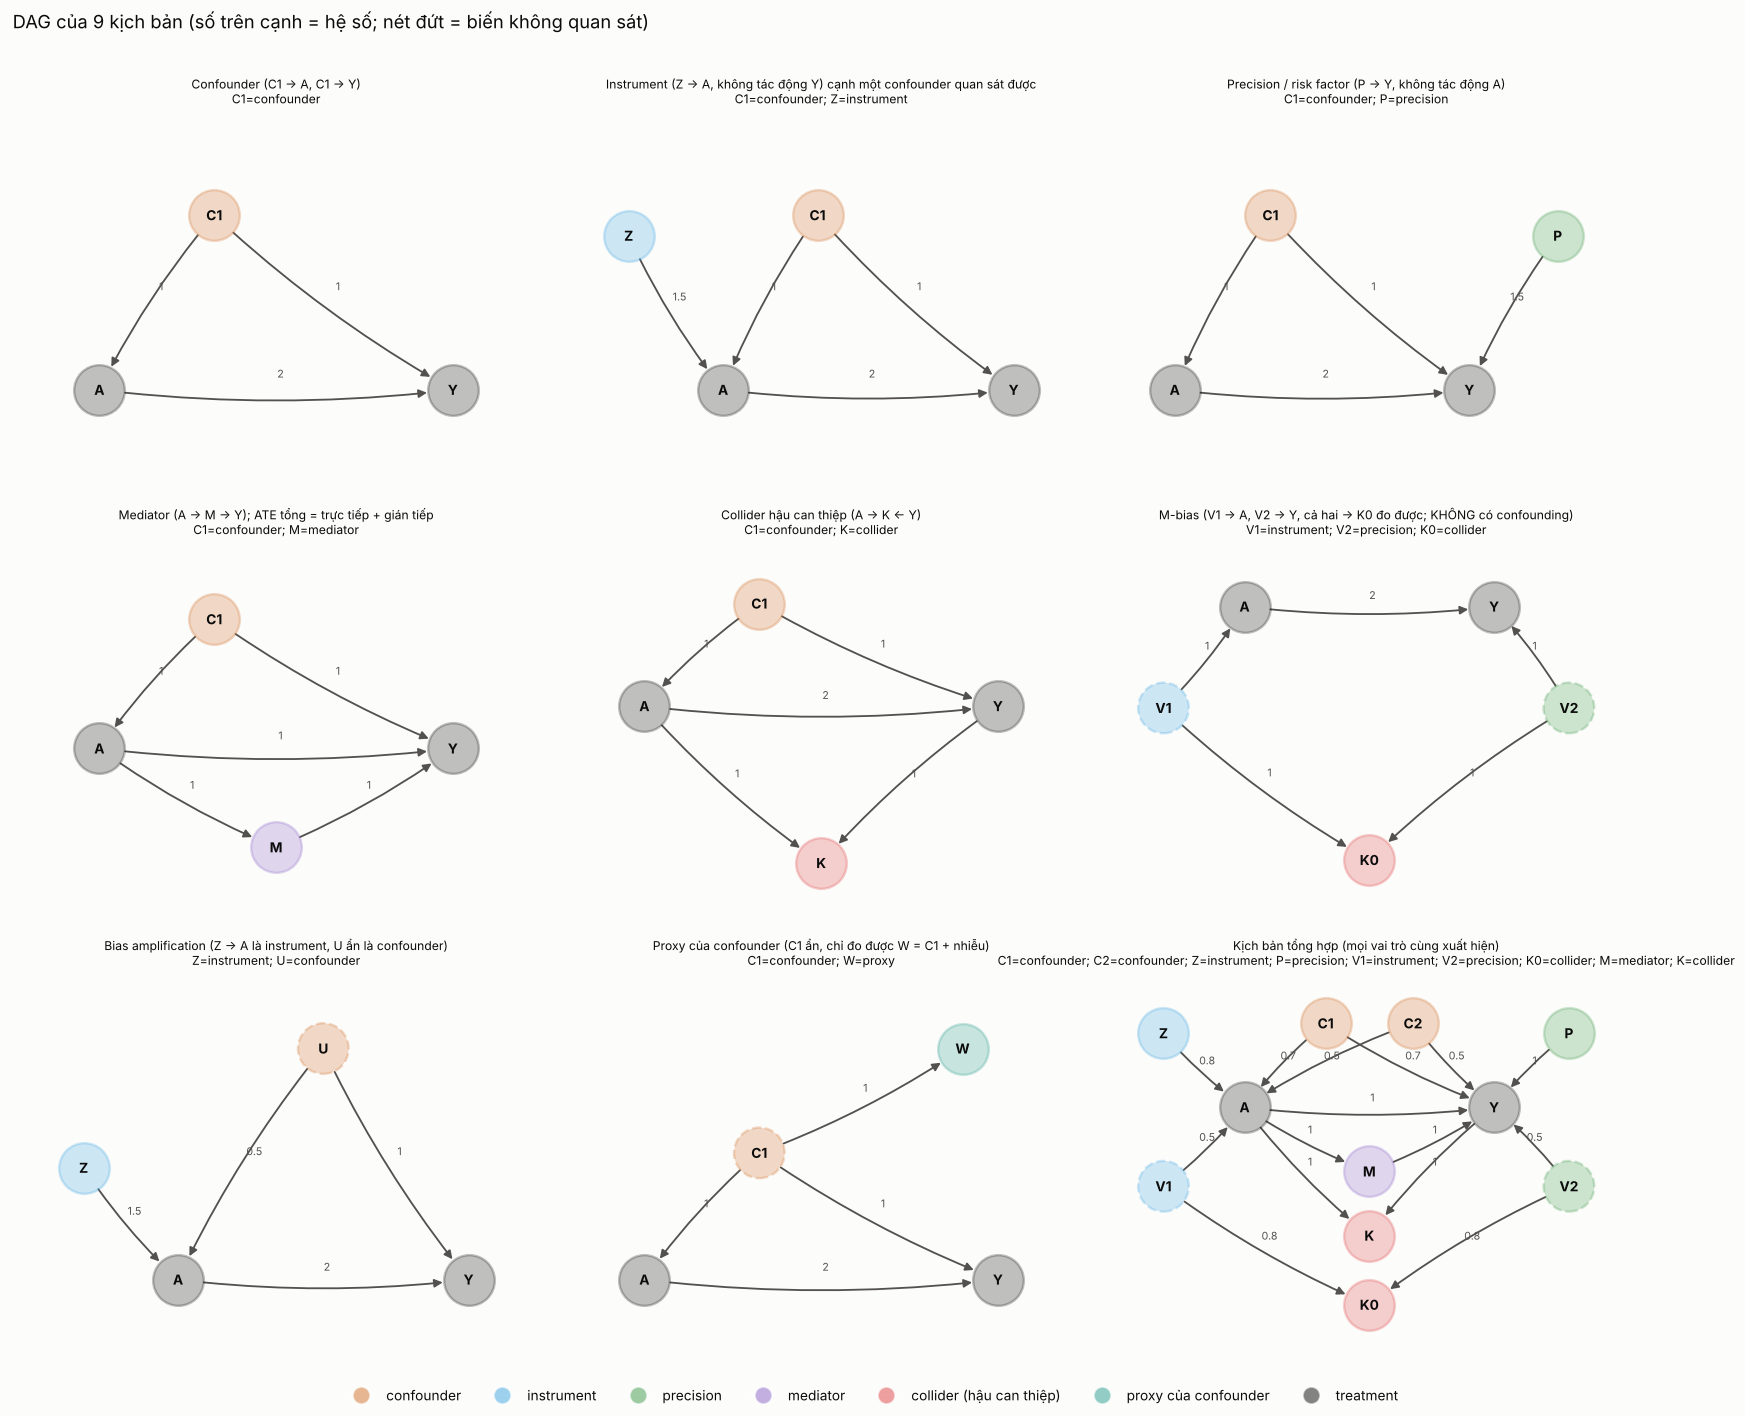

In [3]:
def draw_dag(sim, ax, title=None):
    dag = sim.dag(); roles = classify_roles(dag["edges"])
    pos = {k: v["pos"] for k, v in dag["nodes"].items()}
    for s, d, c in dag["edges"]:
        (x0, y0), (x1, y1) = pos[s], pos[d]
        ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=11, lw=1.2,
                                     color="#52514e", shrinkA=17, shrinkB=17, connectionstyle="arc3,rad=0.06"))
        ax.text((x0 + x1) / 2 + 0.05, (y0 + y1) / 2 + 0.12, f"{c:g}", fontsize=7, color="#52514e", ha="center")
    for k, v in dag["nodes"].items():
        col = ROLE_COLOR.get(roles.get(k, "nhiễu"), GRAY)
        ax.scatter(*pos[k], s=1100, color=col, alpha=0.25, edgecolor=col, linewidth=1.6,
                   linestyle="--" if v["latent"] else "-", zorder=3)
        ax.text(pos[k][0], pos[k][1], k, ha="center", va="center", fontsize=9, fontweight="bold", zorder=4)
    xs, ys = [p[0] for p in pos.values()], [p[1] for p in pos.values()]
    ax.set_xlim(min(xs) - 1.0, max(xs) + 1.0); ax.set_ylim(min(ys) - 1.0, max(ys) + 1.0); ax.axis("off")
    r = {k: roles[k] for k in dag["nodes"] if k in roles and k not in ("A", "Y")}
    ax.set_title((title or sim.info["title"]) + "\n" + "; ".join(f"{k}={v.split(' ')[0]}" for k, v in r.items()), fontsize=8)

fig, axes = plt.subplots(3, 3, figsize=(15, 13))
for ax, k in zip(axes.ravel(), SCENARIO_ORDER):
    draw_dag(RoleSimulation(k), ax)
handles = [Line2D([0], [0], marker="o", color="w", markerfacecolor=c, alpha=0.5, markersize=11, label=r)
           for r, c in ROLE_COLOR.items() if r in {"confounder", "instrument", "precision", "mediator", "collider (hậu can thiệp)", "proxy của confounder", "treatment"}]
fig.legend(handles=handles, loc="lower center", ncol=7, frameon=False)
fig.suptitle("DAG của 9 kịch bản (số trên cạnh = hệ số; nét đứt = biến không quan sát)", x=0.01, ha="left", fontsize=12)
fig.tight_layout(rect=[0, 0.03, 1, 0.97]); plt.show()

### 3.4 Dự đoán lý thuyết trước khi chạy Monte Carlo

Trước khi lặp mô phỏng, chúng ta tính **bias tiệm cận** của từng phương pháp và từng chiến lược hiệu chỉnh bằng một mẫu rất lớn ($n=300\,000$, hàm `asymptotic_bias`). Số này là **đáp án cấu trúc** (không còn nhiễu mẫu): nếu Monte Carlo ở $n$ nhỏ cho bias gần số này thì sai lệch là chệch hệ thống do DAG. Các bảng và biểu đồ sau dùng nó làm vạch tham chiếu (dấu gạch đen).

Cột `strategy` là *tập biến được đưa vào mô hình* (ví dụ `C1+M` nghĩa là hiệu chỉnh $C_1$ và $M$). Với IPTW và AIPW tập này đưa vào mô hình PS, và với OLS, AIPW đưa vào mô hình outcome.

In [4]:
ASYM = {}
rows = []
t0 = time.time()
for k in SCENARIO_ORDER:
    sim = RoleSimulation(k)
    for s, v in sim.strategies.items():
        row = {"kịch bản": k, "strategy": s, "tập hiệu chỉnh": "{" + ", ".join(v["adjust"]) + "}"}
        for m in ("ols", "iptw", "aipw"):
            ASYM[(k, s, m)] = asymptotic_bias(sim, v["adjust"], m, n=ASYM_N)
            row[m] = ASYM[(k, s, m)]
        rows.append(row)
ASYM_TAB = pd.DataFrame(rows).set_index(["kịch bản", "strategy"])
print(f"bias tiệm cận (n={ASYM_N}), tính trong {time.time()-t0:.0f}s; ATE tổng = 2")
display(ASYM_TAB.round(3))

bias tiệm cận (n=300000), tính trong 9s; ATE tổng = 2


tập hiệu chỉnh    ols   iptw   aipw
kịch bản      strategy                                               
confounder    none                            {}  0.830  0.830  0.830
              C1                            {C1} -0.002 -0.005 -0.003
instrument    none                            {}  0.646  0.646  0.646
              C1                            {C1}  0.001  0.004  0.000
              C1+Z                       {C1, Z}  0.004  0.007  0.004
precision     none                            {}  0.821  0.821  0.821
              C1                            {C1} -0.009 -0.010 -0.010
              C1+P                       {C1, P} -0.000 -0.001  0.000
mediator      none                            {}  0.826  0.826  0.826
              C1                            {C1} -0.007 -0.008 -0.006
              C1+M                       {C1, M} -1.004 -1.012 -1.002
collider      none                            {}  0.830  0.830  0.830
              C1                            {C1} -0.002 -0.005 -0.003
              C1+K                       {C1, K} -1.501 -1.653 -1.470
m_bias        none                            {} -0.002 -0.002 -0.002
              K0                            {K0} -0.295 -0.294 -0.295
amplification none                            {}  0.348  0.348  0.348
              Z                              {Z}  0.472  0.479  0.480
proxy         none                            {}  0.826  0.826  0.826
              W                              {W}  0.454  0.455  0.454
kitchen_sink  none                            {}  0.561  0.561  0.561
              conf                      {C1, C2} -0.005 -0.003 -0.004
              conf+P                 {C1, C2, P} -0.005 -0.004 -0.004
              conf+P+Z            {C1, C2, P, Z} -0.007 -0.005 -0.008
              pre-all         {C1, C2, P, Z, K0} -0.073 -0.071 -0.075
              conf+M                 {C1, C2, M} -1.004 -1.000 -0.997
              conf+K                 {C1, C2, K} -2.292 -2.252 -2.281
              all       {C1, C2, P, Z, K0, M, K} -2.113 -2.093 -2.105

**Nhận xét.** Bảng trên cho biết *đáp án cấu trúc* trước khi có nhiễu mẫu. Ba điều rút ra:

1. **Ba phương pháp gần như trùng nhau** ở hầu hết các dòng (chênh nhau không quá 0,04). Nghĩa là bias ở đây **không do chọn phương pháp** mà do chọn *tập biến*; đổi OLS sang AIPW không cứu được một tập biến sai. Ngoại lệ rõ nhất là IPTW ở `collider/C1+K` (−1,65 so với −1,50 của OLS), vì PS gần như tất định nên ước lượng trọng số kém ổn định.
2. **Các giá trị khớp với lý thuyết.** Mediator: −1,004 ≈ $-a_mb_m=-1$. Hiệu chỉnh đúng tập backdoor cho bias xấp xỉ 0 ở mọi kịch bản mà confounder đều được đo (trừ `amplification` và `proxy`, nơi confounder không đo được). Proxy: 0,826 → 0,454, tức còn khoảng 55% bias ban đầu, gần với $1-\lambda=0{,}5$ (độ tin cậy $\lambda=0{,}5$).
3. **Một chi tiết bất ngờ ở hàng `instrument/none`:** naive chỉ chệch 0,646 chứ không phải 0,83 như ở kịch bản confounder, dù $C_1$ có cùng hệ số. Lý do là $Z$ giải thích một phần biến thiên của $A$ mà không liên quan đến $Y$, nên phần "chọn can thiệp theo đất tốt" bị **pha loãng**. Ý này quay lại ở kịch bản khuếch đại bias (mục 5.7).

Với `collider` còn có công thức đóng. Giả sử $Y\mid A,C_1$ chuẩn với phương sai $v$ và $K=k_aA+k_yY+\varepsilon_K$ ($\operatorname{Var}\varepsilon_K=1$), thì hệ số của $A$ trong hồi quy có $K$ lệch một lượng $-c\,(k_y\tau+k_a)$ với $c=k_yv/(k_y^2v+1)$. Với $k_a=k_y=1$, $v=1$, $\tau=2$ ta có $c=0{,}5$ và bias $=-1{,}5$, đúng như bảng. Công thức này (tự suy ra, chưa tìm thấy trong tài liệu nên cần coi là nhận xét của người làm) sẽ được kiểm lại bằng phép quét ở mục 6.

## 4. Kiểm tra dữ liệu sinh ra và giới hạn của chẩn đoán từ dữ liệu

Trước tiên xem một mẫu của từng kịch bản ($n=2000$): tỉ lệ treated, độ cực đoan của **PS thật** (`e` trong dữ liệu, biến mà analyst không thấy) và, với **từng chiến lược hiệu chỉnh**, ESS (cỡ mẫu hiệu dụng, Kish) và trọng số lớn nhất của IPTW. Mục đích: (1) chắc chắn rằng PS thật không quá cực đoan, để kết quả sau đó không bị vi phạm positivity chi phối; (2) thấy trước chiến lược nào làm trọng số xấu đi (ESS/n thấp).

In [5]:
rows = {}
for k in SCENARIO_ORDER:
    sim = RoleSimulation(k, seed=SEED); df = sim.generate(n=2000)
    for st, v in sim.strategies.items():
        if not v["adjust"]: continue          # không hiệu chỉnh => PS hằng số, không có gì để kiểm tra
        tab, dg = estimate(df, ps_set=v["adjust"], methods=("iptw",))
        rows[(k, st)] = {"treated_rate": df.A.mean(), "PS thật min": df.e.min(), "PS thật max": df.e.max(),
                         "ESS/n": dg["ess_ratio"], "max w": dg["max_weight"], "PS ước lượng ngoài [.01,.99]": dg["e_outside"]}
OVL = pd.DataFrame(rows).T; OVL.index.names = ["kịch bản", "strategy"]
display(OVL.round(3))

treated_rate  PS thật min  PS thật max  ESS/n    max w  PS ước lượng ngoài [.01,.99]
kịch bản      strategy                                                                                      
confounder    C1               0.498        0.030        0.967  0.700   27.123                         0.000
instrument    C1               0.492        0.004        0.999  0.856    7.904                         0.000
              C1+Z             0.492        0.004        0.999  0.342   73.287                         0.016
precision     C1               0.497        0.030        0.967  0.752   13.540                         0.000
              C1+P             0.497        0.030        0.967  0.752   13.414                         0.000
mediator      C1               0.498        0.030        0.967  0.700   27.123                         0.000
              C1+M             0.498        0.030        0.967  0.032  542.488                         0.003
collider      C1               0.498        0.030        0.967  0.700   27.123                         0.000
              C1+K             0.498        0.030        0.967  0.014  774.517                         0.197
m_bias        K0               0.500        0.030        0.967  0.934    7.162                         0.000
amplification Z                0.498        0.005        0.997  0.536   30.544                         0.002
proxy         W                0.497        0.030        0.967  0.900    7.673                         0.000
kitchen_sink  conf             0.500        0.012        0.982  0.899    6.471                         0.000
              conf+P           0.500        0.012        0.982  0.898    6.860                         0.000
              conf+P+Z         0.500        0.012        0.982  0.730   26.114                         0.000
              pre-all          0.500        0.012        0.982  0.725   14.998                         0.000
              conf+M           0.500        0.012        0.982  0.601   23.973                         0.002
              conf+K           0.500        0.012        0.982  0.284   88.900                         0.022
              all              0.500        0.012        0.982  0.283   52.738                         0.081

### Dữ liệu có phân biệt được vai trò của các biến không?

Một cách làm phổ biến trong thực hành là quan sát tương quan: *biến nào liên quan cả tới $A$ lẫn tới $Y$ thì coi là confounder*. Hàm `role_diagnostics` tính hai đại lượng: chênh lệch chuẩn hóa của $X$ giữa hai nhóm $A$ (SMD) và tương quan riêng của $X$ với $Y$ sau khi loại ảnh hưởng của $A$. Dưới đây áp dụng cho kịch bản tổng hợp và vẽ "dấu vân tay" của từng biến, tô màu theo **vai trò thật** (biết vì chúng ta đã tự dựng DAG).

,smd_A,corr_XY_A,corr_XA,liên quan A?,liên quan Y|A?,vai trò thật
C1,0.594,0.321,0.285,có,có,confounder
C2,0.364,0.217,0.179,có,có,confounder
Z,0.615,-0.056,0.294,có,không,instrument
P,-0.008,0.507,-0.004,không,có,precision
K0,0.163,0.127,0.081,có,có,collider (M-bias)
M,0.997,0.508,0.446,có,có,mediator
K,1.622,0.890,0.630,có,có,collider (hậu can thiệp)


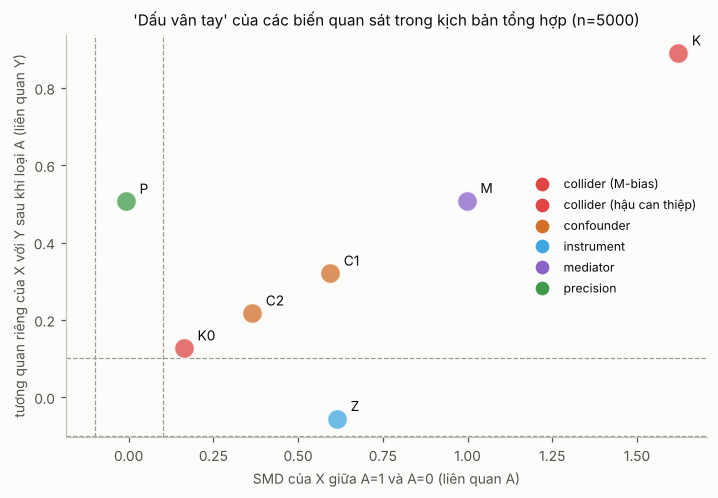

In [6]:
sim_ks = RoleSimulation("kitchen_sink", seed=SEED)
df_ks = sim_ks.generate(n=5000)
fp = role_diagnostics(df_ks, sim_ks.observed)
roles_ks = classify_roles(sim_ks.dag()["edges"])
fp["vai trò thật"] = [roles_ks[c] for c in fp.index]
display(fp.round(3))

fig, ax = plt.subplots(figsize=(6.6, 4.6))
for c, r in fp.iterrows():
    ax.scatter(r["smd_A"], r["corr_XY_A"], s=170, color=ROLE_COLOR[r["vai trò thật"]], alpha=0.75, edgecolor="white", zorder=3)
    ax.annotate(c, (r["smd_A"], r["corr_XY_A"]), textcoords="offset points", xytext=(9, 5), fontsize=9)
ax.axvline(0.1, color=GRAY, ls="--", lw=0.8); ax.axvline(-0.1, color=GRAY, ls="--", lw=0.8)
ax.axhline(0.1, color=GRAY, ls="--", lw=0.8); ax.axhline(-0.1, color=GRAY, ls="--", lw=0.8)
ax.set_xlabel("SMD của X giữa A=1 và A=0 (liên quan A)"); ax.set_ylabel("tương quan riêng của X với Y sau khi loại A (liên quan Y)")
ax.set_title("'Dấu vân tay' của các biến quan sát trong kịch bản tổng hợp (n=5000)")
leg = [Line2D([0], [0], marker="o", color="w", markerfacecolor=ROLE_COLOR[r], markersize=10, label=r) for r in sorted(set(fp["vai trò thật"]))]
ax.legend(handles=leg, frameon=False, fontsize=8, loc="best"); fig.tight_layout(); plt.show()

**Nhận xét.** Biểu đồ cho thấy giới hạn của việc "nhìn dữ liệu để chọn biến":

- $P$ (precision) nằm sát trục dọc: không liên quan $A$ (SMD $\approx0$) nhưng liên quan $Y$ (tương quan riêng 0,51). $Z$ (instrument) thì ngược lại (SMD 0,62, tương quan với $Y$ gần 0). Hai loại này **có thể nhận ra** từ dữ liệu vì chỉ liên quan một phía.
- Nhưng $C_1,C_2$ (confounder), $M$ (mediator), $K$ (collider hậu can thiệp) và cả $K_0$ (collider tiền can thiệp) đều rơi vào cùng một vùng: *liên quan cả $A$ lẫn $Y$*. $M$ và $K$ thậm chí trông "giống confounder" hơn chính confounder thật (SMD 1,0 và 1,6 so với 0,59 và 0,36). $K_0$ cũng vượt ngưỡng 0,1 (SMD 0,16, tương quan 0,13), tức một quy tắc kiểu "biến nào mất cân bằng thì cho vào" sẽ chọn nó.
- Ở mục 5 ta đã thấy hậu quả: đưa $M$ vào gây bias −1,0, đưa $K$ vào gây bias −2,3 (kịch bản tổng hợp).

Nguyên nhân là **vai trò nhân quả không nằm trong phân phối biên hay tương quan** [1, 2]. Hai DAG khác nhau có thể sinh ra cùng một ma trận tương quan. Cái giúp phân biệt confounder với mediator/collider là **thứ tự thời gian** (đo trước hay sau khi áp dụng can thiệp) và **kiến thức chuyên môn**: $M$ (độ ẩm đất sau tưới) và $K$ (có được chọn vào danh sách khảo sát sau vụ) đều xảy ra sau $A$, nên bị loại ngay cả khi số liệu "đẹp". Đây là lý do pipeline thực tế phải có một **bảng vai trò biến do chuyên gia điền** (thời điểm đo, có thể là hậu quả của can thiệp hay không) *trước* bước chọn biến tự động.

## 5. Monte Carlo cho từng vai trò

Với mỗi kịch bản và mỗi cỡ mẫu $n\in\{200,500,2000,5000\}$ chúng ta lặp 1000 lần. Mỗi lần: sinh dữ liệu mới, rồi với **mỗi chiến lược hiệu chỉnh** (xem `SCENARIOS[...]['strategies']`) chạy naive, OLS, IPTW, AIPW. Kết quả được gộp vào bảng `RES` (tóm tắt) và `RAW` (ước lượng từng lần lặp, dùng cho boxplot).

**Về SE.** SE của IPTW được tính có hiệu chỉnh cho việc ước lượng PS (`utilities.hajek_se_ps_corrected`, theo ý tưởng của [15]); mục 9 so sánh với cách coi PS đã biết. SE của OLS là robust HC1, của AIPW theo hàm ảnh hưởng.

In [7]:
t0 = time.time()
parts, RAW = [], {}
for k in SCENARIO_ORDER:
    sim = RoleSimulation(k)
    for n in NS:
        summ, raw = monte_carlo(sim, n=n, reps=REPS, seed=SEED, n_jobs=2)
        parts.append(summ)
        if n in (500, 2000): RAW[(k, n)] = raw
RES = pd.concat(parts, ignore_index=True)
print(f"xong {len(SCENARIO_ORDER)} kịch bản x {len(NS)} cỡ mẫu x {REPS} lần lặp trong {time.time()-t0:.0f}s")
RES.head()

xong 9 kịch bản x 4 cỡ mẫu x 1000 lần lặp trong 187s


,scenario,n,strategy,method,mean_est,bias,sd,rmse,mean_se,coverage,ci_width,ess_ratio,max_weight,e_outside,mc_se_bias
0,confounder,200,none,naive,2.825586,0.825586,0.197149,0.848776,0.191322,0.013,0.749968,0.995085,2.122269,0.0000,0.006234
1,confounder,200,none,ols,2.825586,0.825586,0.197149,0.848776,0.191312,0.013,0.749930,0.995085,2.122269,0.0000,0.006234
2,confounder,200,none,iptw,2.825586,0.825586,0.197149,0.848776,0.190353,0.013,0.746171,0.995085,2.122269,0.0000,0.006234
3,confounder,200,none,aipw,2.825586,0.825586,0.197149,0.848776,0.190831,0.013,0.748043,0.995085,2.122269,0.0000,0.006234
4,confounder,200,C1,naive,2.825586,0.825586,0.197149,0.848776,0.191322,0.013,0.749968,0.750729,10.499943,0.0001,0.006234


### Hàm trực quan hóa

Mỗi kịch bản được trình bày bằng ba hình:

- **Hình A** (n=2000): bias, SD và coverage theo *chiến lược hiệu chỉnh* và phương pháp. Thanh sai số trong ô bias là ±1,96·sai số Monte Carlo; **gạch đen ngang** là bias tiệm cận ở mục 3.4; dải xanh trong ô coverage là $0.95\pm0.014$.
- **Hình B**: bias và SD theo cỡ mẫu để tách chệch hệ thống (phẳng theo $n$) khỏi nhiễu (giảm như $1/\sqrt n$, đường chấm là độ dốc $-1/2$).
- **Hình C**: boxplot các ước lượng qua 1000 lần lặp (n=500 và n=2000), vạch đứt là giá trị đích.

In [8]:
STRAT_COL = ["#4c78a8", "#f58518", "#54a24b", "#b279a2", "#e45756", "#72b7b2", "#9d755d", "#bab0ac"]
METHOD_ORDER = ["naive", "ols", "iptw", "aipw"]

def _sel(scenario, n=None):
    d = RES[RES.scenario == scenario]
    if n is not None: d = d[d.n == n]
    return d[(d.method != "naive") | (d.strategy == "none")]

def plot_overview(scenario, n=2000, methods=METHOD_ORDER, extra_truth=None):
    sim = RoleSimulation(scenario); strat = list(sim.strategies); d = _sel(scenario, n)
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.7))
    for ax, (col, ttl) in zip(axes, [("bias", f"Bias so với ATE tổng = {sim.true_ate:g}"), ("sd", "SD của ước lượng"), ("coverage", "Độ phủ CI 95%")]):
        for i, s in enumerate(strat):
            for j, m in enumerate(methods):
                r = d[(d.strategy == s) & (d.method == m)]
                if r.empty: continue
                x = i + (j - (len(methods) - 1) / 2) * 0.17; y = float(r[col].iloc[0])
                ax.scatter(x, y, color=MCOL[m], s=42, zorder=3)
                if col == "bias":
                    ax.errorbar(x, y, yerr=Z95 * float(r.mc_se_bias.iloc[0]), color=MCOL[m], capsize=2, lw=1)
                    if m != "naive": ax.scatter(x, ASYM[(scenario, s, m)], marker="_", s=150, color=INK, zorder=4, linewidths=1.5)
        ax.set_xticks(range(len(strat))); ax.set_xticklabels([s if scenario == "kitchen_sink" else sim.strategies[s]["label"] for s in strat], rotation=25, ha="right", fontsize=8)
        ax.set_title(ttl)
        if col == "bias": ax.axhline(0, color=INK, lw=0.8)
        if col == "coverage": ax.axhspan(0.95 - MC_BAND, 0.95 + MC_BAND, color="#7ED386", alpha=0.25); ax.set_ylim(-0.02, 1.02)
    axes[0].legend(handles=[Line2D([0], [0], marker="o", color="w", markerfacecolor=MCOL[m], markersize=8, label=m) for m in methods]
                   + [Line2D([0], [0], marker="_", color=INK, markersize=10, lw=0, label="bias tiệm cận")], frameon=False, fontsize=8)
    fig.suptitle(f"{sim.info['title']} · n={n}", x=0.01, ha="left", fontsize=11); fig.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

def plot_vs_n(scenario, methods=("ols", "iptw", "aipw")):
    sim = RoleSimulation(scenario); strat = list(sim.strategies)
    d = RES[(RES.scenario == scenario) & RES.method.isin(methods)]
    ls = {"ols": "-", "iptw": "--", "aipw": ":"}
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.5))
    for ax, (col, ttl) in zip(axes, [("bias", "Bias theo cỡ mẫu"), ("sd", "SD theo cỡ mẫu (log-log)"), ("coverage", "Độ phủ CI theo cỡ mẫu")]):
        for i, s in enumerate(strat):
            for m in methods:
                r = d[(d.strategy == s) & (d.method == m)].sort_values("n")
                ax.plot(r.n, r[col], ls[m], marker="o", ms=3.5, color=STRAT_COL[i], lw=1.3)
        ax.set_xscale("log"); ax.set_xticks(list(NS)); ax.set_xticklabels(NS); ax.xaxis.set_minor_formatter(NullFormatter()); ax.set_xlabel("n"); ax.set_title(ttl)
        if col == "bias": ax.axhline(0, color=INK, lw=0.8)
        if col == "sd":
            ax.set_yscale("log"); r0 = d[(d.strategy == strat[1]) & (d.method == "ols") & (d.n == NS[0])]
            if len(r0): y0 = float(r0.sd.iloc[0]); ax.plot(NS, [y0 * (NS[0] / n) ** 0.5 for n in NS], color=INK, lw=0.8, ls=(0, (1, 3)))
        if col == "coverage": ax.axhspan(0.95 - MC_BAND, 0.95 + MC_BAND, color="#7ED386", alpha=0.25); ax.set_ylim(-0.02, 1.02)
    axes[0].legend(handles=[Line2D([0], [0], color=STRAT_COL[i], lw=2, label=s if scenario == "kitchen_sink" else sim.strategies[s]["label"]) for i, s in enumerate(strat)]
                   + [Line2D([0], [0], color=INK, ls=ls[m], lw=1.2, label=m) for m in methods], frameon=False, fontsize=7.5)
    fig.tight_layout(); plt.show()

def plot_box(scenario, extra_lines=(), methods=("ols", "iptw", "aipw")):
    sim = RoleSimulation(scenario); strat = list(sim.strategies)
    fig, axes = plt.subplots(1, 2, figsize=(15.5, 3.6), sharey=True)
    for ax, n in zip(axes, (500, 2000)):
        raw = RAW[(scenario, n)]
        for i, s in enumerate(strat):
            for j, m in enumerate(methods):
                x = raw[(raw.strategy == s) & (raw.method == m)].est.dropna().to_numpy()
                pos = i + (j - 1) * 0.22
                bp = ax.boxplot(x, positions=[pos], widths=0.18, patch_artist=True, showfliers=True, manage_ticks=False,
                                flierprops=dict(marker=".", ms=2, alpha=0.35), medianprops=dict(color=INK))
                bp["boxes"][0].set_facecolor(MCOL[m]); bp["boxes"][0].set_alpha(0.65)
        ax.axhline(sim.true_ate, color=INK, ls="--", lw=1)
        for y, c, lab in extra_lines: ax.axhline(y, color=c, ls=":", lw=1.2)
        ax.set_xticks(range(len(strat))); ax.set_xticklabels([s if scenario == "kitchen_sink" else sim.strategies[s]["label"] for s in strat], fontsize=8, rotation=25 if scenario == "kitchen_sink" else 0)
        ax.set_title(f"Phân phối ước lượng, n={n}"); lo, hi = np.nanpercentile(raw.est, [0.5, 99.5]); ax.set_ylim(min(lo, sim.true_ate) - 0.2, max(hi, sim.true_ate) + 0.2)
    axes[0].legend(handles=[Line2D([0], [0], color=MCOL[m], lw=6, alpha=0.65, label=m) for m in methods], frameon=False, fontsize=8)
    fig.tight_layout(); plt.show()

def show_table(scenario, n=2000, cols=("bias", "sd", "rmse", "mean_se", "coverage", "ci_width", "ess_ratio", "max_weight")):
    d = _sel(scenario, n).set_index(["strategy", "method"])[list(cols)]
    display(d.round(3))

def run_role(scenario, extra_lines=()):
    show_table(scenario); plot_overview(scenario); plot_vs_n(scenario); plot_box(scenario, extra_lines)

### 5.1 Confounder: $C_1\to A$, $C_1\to Y$

**Cơ chế.** $C_1$ tạo ra đường cửa sau $A\leftarrow C_1\to Y$. Nông hộ có đất tốt vừa dễ áp dụng kỹ thuật mới vừa có năng suất cao, nên so sánh thẳng hai nhóm trộn lẫn tác động của đất với tác động của kỹ thuật [2, 4]. Hiệu chỉnh $C_1$ chặn đường này: với OLS là giữ $C_1$ cố định trong hồi quy, với IPTW là tạo "quần thể giả" trong đó $C_1$ phân phối giống nhau ở hai nhóm.

**Chiều và độ lớn của bias khi bỏ qua.** Cả hai cạnh đều dương nên naive đánh giá quá cao hiệu ứng. Độ lớn xấp xỉ $b_{c1}\times(E[C_1|A=1]-E[C_1|A=0])$.


**Dự đoán trước khi chạy:** naive chệch dương cỡ 0,8; OLS, IPTW, AIPW đều không chệch khi hiệu chỉnh $C_1$ và độ phủ CI quanh 0,95.

bias     sd   rmse  mean_se  coverage  ci_width  ess_ratio  max_weight
strategy method                                                                         
none     naive   0.829  0.061  0.831    0.061     0.000     0.237      1.000       2.036
         ols     0.829  0.061  0.831    0.061     0.000     0.237      1.000       2.036
         iptw    0.829  0.061  0.831    0.060     0.000     0.237      1.000       2.036
         aipw    0.829  0.061  0.831    0.060     0.000     0.237      1.000       2.036
C1       ols     0.002  0.049  0.049    0.049     0.957     0.193      0.753      17.571
         iptw    0.001  0.060  0.060    0.059     0.946     0.230      0.753      17.571
         aipw    0.001  0.052  0.052    0.052     0.952     0.202      0.753      17.571

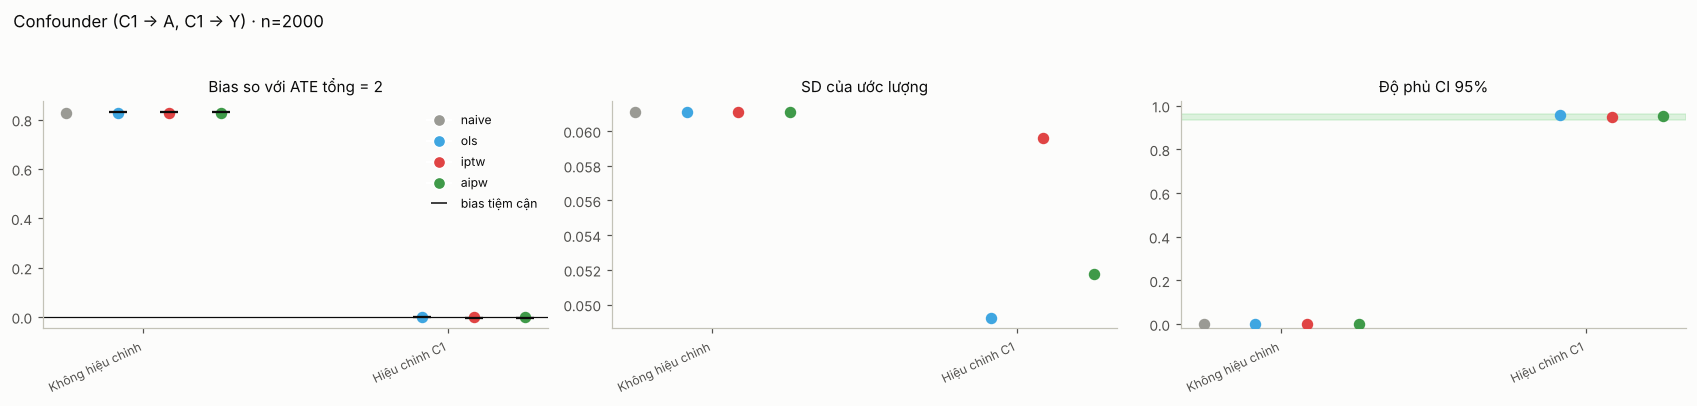

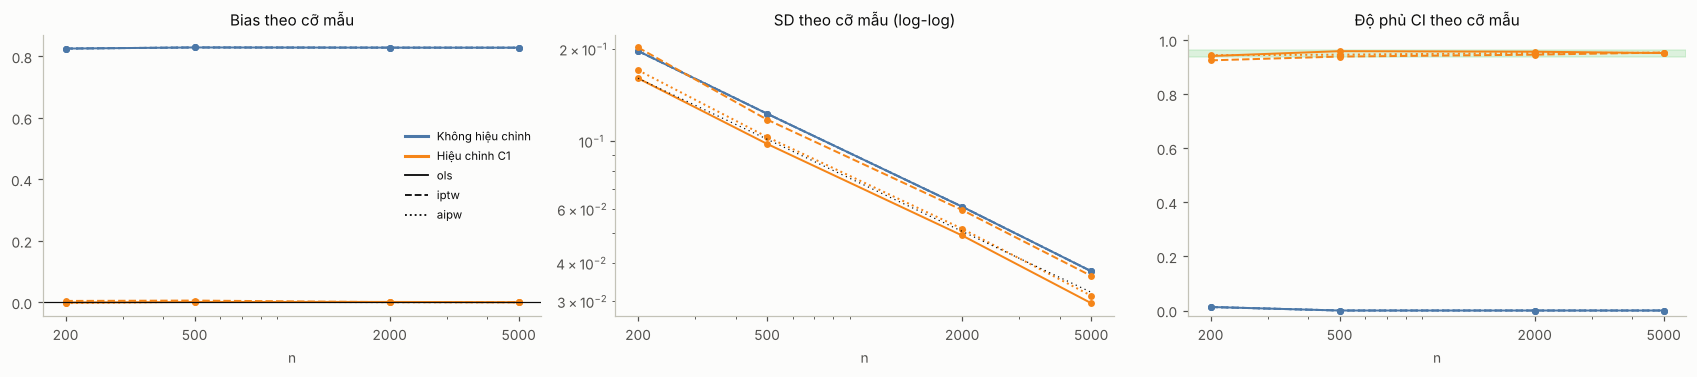

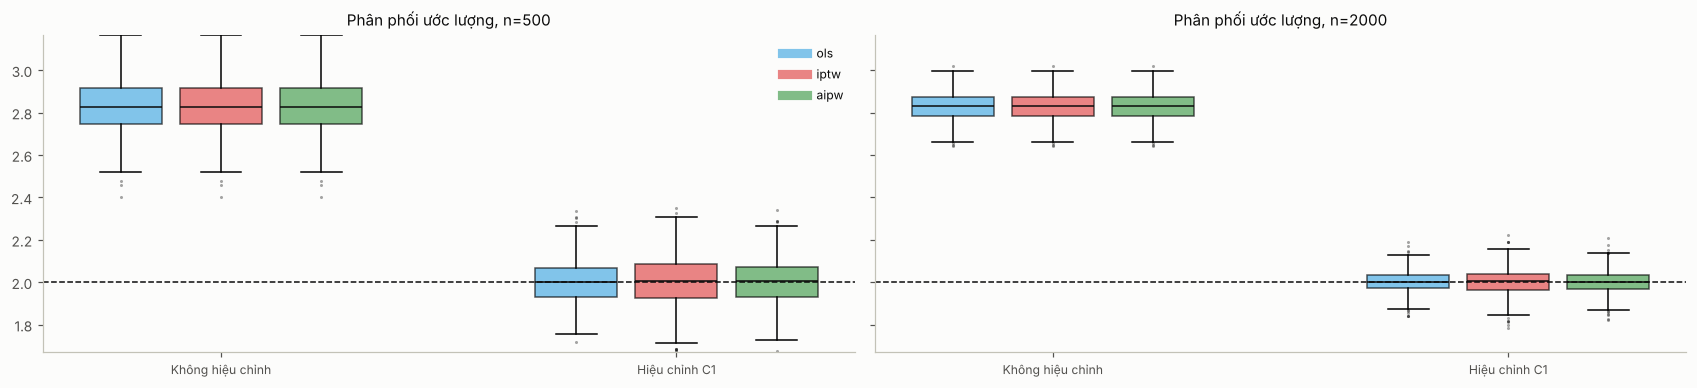

In [9]:
run_role("confounder")

**Nhận xét.**

- **Bias.** Naive chệch +0,829 ở $n=2000$ (gấp khoảng 13 lần SD của chính nó là 0,061) và **không đổi theo $n$** (0,826; 0,829; 0,829; 0,829). Khi tăng $n$ chỉ làm khoảng tin cậy hẹp lại quanh một giá trị sai, nên coverage về 0 từ $n=500$. Đây chính là bằng chứng "dữ liệu nhiều hơn không cứu được confounding". Khi hiệu chỉnh $C_1$, bias của cả ba phương pháp nằm trong khoảng ±0,006, bằng cỡ sai số Monte Carlo (0,002 ở $n=2000$).
- **Độ chính xác.** SD ở $n=2000$: OLS 0,049 < AIPW 0,052 < IPTW 0,060. OLS tốt nhất vì mô hình tuyến tính đúng dạng và dùng hết thông tin của $C_1$. IPTW chỉ dùng $C_1$ để tạo trọng số, mà trọng số không đều (ESS/n = 0,75, trọng số lớn nhất khoảng 18), nên "mất" khoảng 25% mẫu. SD của cả ba giảm đúng khoảng một nửa khi $n$ tăng 4 lần (0,098 → 0,049 với OLS), phù hợp với $1/\sqrt n$.
- **Coverage.** Với $n\ge500$ cả ba nằm trong dải 0,95 ± 0,014 (OLS 0,957; IPTW 0,946; AIPW 0,952 ở $n=2000$). Riêng $n=200$ IPTW chỉ đạt 0,925, hơi dưới dải: mẫu nhỏ làm PS ước lượng kém ổn định và SE tiệm cận hơi thấp.
- **So với dự đoán:** đúng. Đây là kịch bản "chuẩn" để so sánh với những kịch bản tiếp theo: bất kỳ sai lệch nào ở các mục sau đều là do biến được thêm vào chứ không phải do phương pháp.

### 5.2 Instrument: $Z\to A$ (không tác động trực tiếp lên $Y$)

**Cơ chế.** $Z$ (khoảng cách tới trạm khuyến nông) chỉ ảnh hưởng đến việc áp dụng kỹ thuật. Vì không có đường nào từ $Z$ tới $Y$ ngoài qua $A$, $Z$ **không phải confounder** và không cần hiệu chỉnh. Hiệu chỉnh nó làm gì? Phần biến thiên của $A$ mà $Z$ giải thích được bị loại ra, nên còn ít biến thiên "tự do" của $A$ để ước lượng hiệu ứng. Với OLS, $\operatorname{Var}(\hat\beta_A)\propto\sigma^2/[n\operatorname{Var}(A\mid X)]$ tăng lên. Với IPTW, PS trở nên cực đoan hơn, trọng số lớn hơn, ESS nhỏ đi [5, 6]. Kết luận cổ điển: instrument **không gây bias nhưng làm tăng phương sai** (khi không còn confounder ẩn).


**Dự đoán trước khi chạy:** mọi chiến lược có hiệu chỉnh $C_1$ đều không chệch; thêm $Z$ làm SD tăng, rõ nhất ở IPTW (và AIPW), ESS/n giảm; OLS tăng ít.

bias     sd   rmse  mean_se  coverage  ci_width  ess_ratio  max_weight
strategy method                                                                         
none     naive   0.645  0.062  0.648    0.062     0.000     0.242      0.999       2.037
         ols     0.645  0.062  0.648    0.062     0.000     0.242      0.999       2.037
         iptw    0.645  0.062  0.648    0.062     0.000     0.241      0.999       2.037
         aipw    0.645  0.062  0.648    0.062     0.000     0.241      0.999       2.037
C1       ols     0.001  0.048  0.048    0.047     0.948     0.185      0.871       9.555
         iptw    0.004  0.050  0.050    0.050     0.946     0.196      0.871       9.555
         aipw    0.001  0.049  0.049    0.048     0.943     0.188      0.871       9.555
C1+Z     ols     0.001  0.054  0.054    0.055     0.953     0.215      0.391      64.130
         iptw    0.004  0.106  0.106    0.091     0.937     0.356      0.391      64.130
         aipw   -0.000  0.075  0.075    0.072     0.962     0.283      0.391      64.130

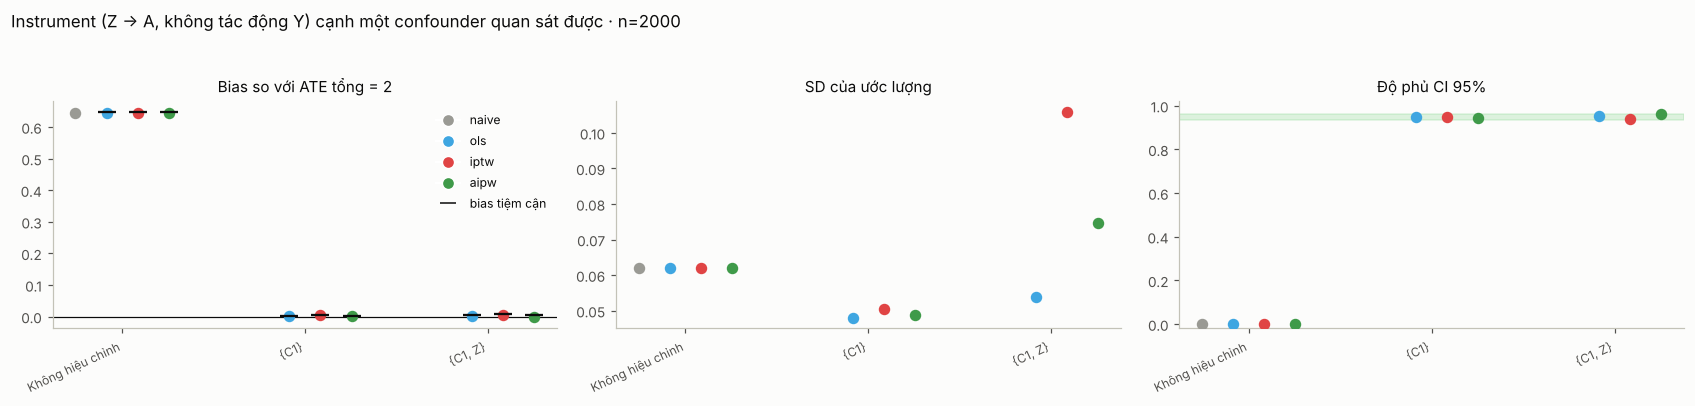

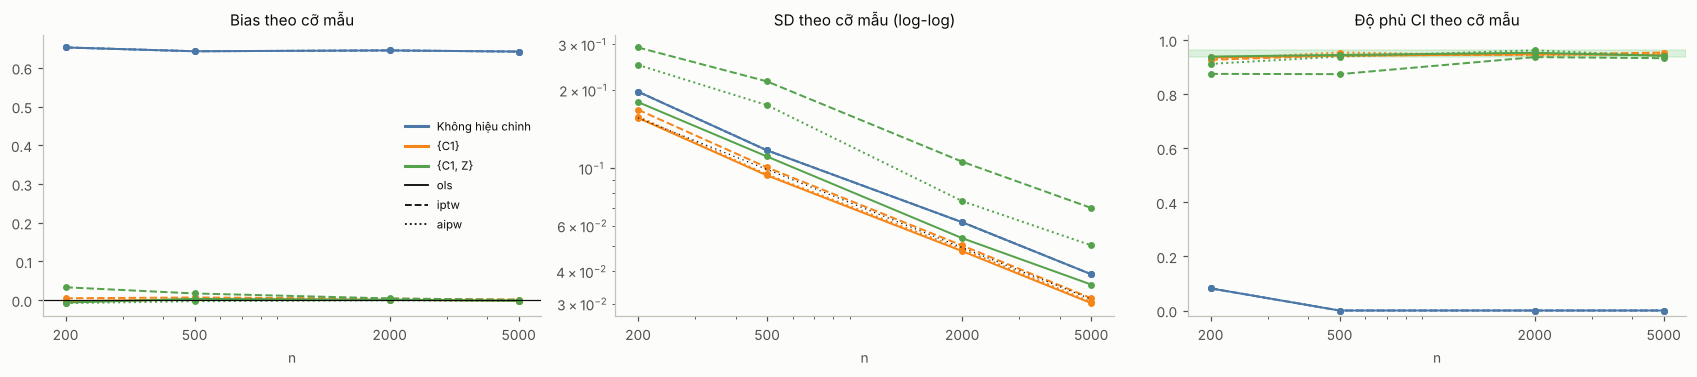

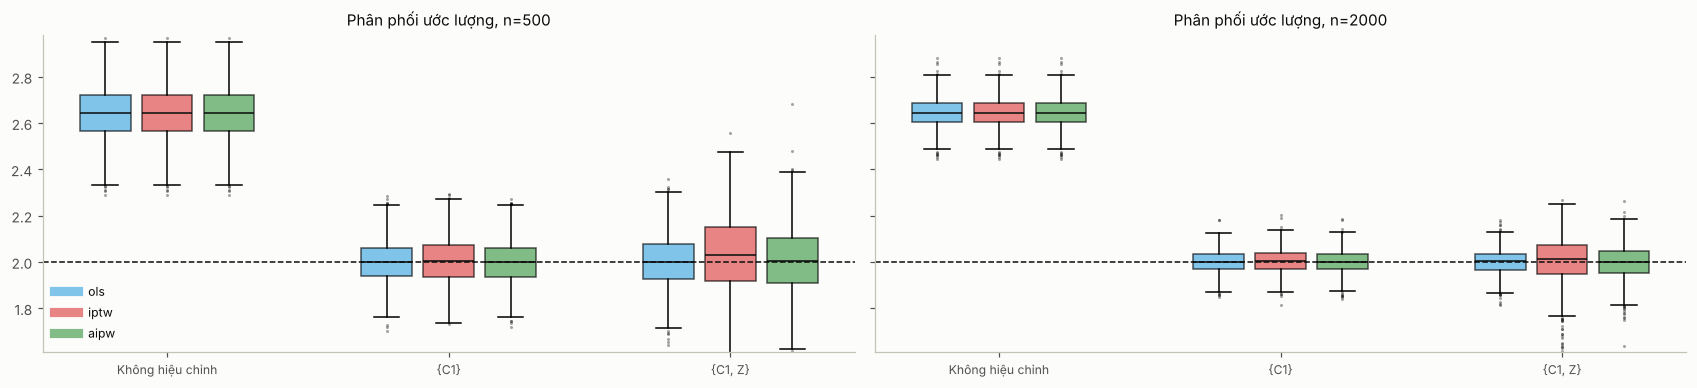

In [10]:
run_role("instrument")

**Nhận xét.**

- **Bias.** Cả `{C1}` và `{C1, Z}` đều không chệch (|bias| ≤ 0,004 ở $n\ge2000$), đúng như lý thuyết: $Z$ không nằm trên đường cửa sau nào nên thêm vào không gây lệch [5, 6].
- **Cái giá là phương sai.** Ở $n=2000$, khi thêm $Z$: SD của OLS tăng 0,048 → 0,054 (+12%), AIPW 0,049 → 0,075 (+53%), IPTW 0,050 → 0,106 (gấp 2,1 lần). Đi kèm là ESS/n giảm từ 0,87 xuống 0,39 và trọng số lớn nhất tăng từ 9,6 lên 64. OLS ít bị ảnh hưởng nhất vì SE của OLS phụ thuộc $\operatorname{Var}(A\mid X)$ chứ không dùng nghịch đảo PS; IPTW và AIPW có $1/e(X)$ nên những quan sát có $e$ gần 0 hoặc 1 (do $Z$ mạnh) bị khuếch đại mạnh.
- **Mẫu nhỏ còn tệ hơn.** Ở $n=200$–$500$ IPTW với `{C1, Z}` có bias +0,033 và +0,017 và coverage 0,875, thấp hơn dải chấp nhận, chỉ phục hồi (0,937) ở $n=2000$. Nguyên nhân là gần vi phạm positivity: một số nông hộ có xác suất áp dụng rất thấp (PS thật nhỏ nhất ≈ 0,004) nhưng vẫn "được áp dụng", mang trọng số hàng chục.
- **Chi tiết cần chú ý:** `none` chỉ chệch 0,645 thay vì 0,83 như kịch bản confounder (xem nhận xét ở mục 3.4).
- **So với dự đoán:** đúng cả ba ý (không lệch, SD tăng, IPTW tăng nhiều nhất).

### 5.3 Precision (risk factor): $P\to Y$ (không tác động lên $A$)

**Cơ chế.** $P$ (lượng mưa) làm năng suất biến động nhưng không liên quan tới việc áp dụng kỹ thuật, nên bỏ qua $P$ **không gây bias**. Tuy nhiên $P$ góp vào phương sai residual của $Y$: $\operatorname{Var}(Y\mid A,C_1)=1+b_p^2$. Đưa $P$ vào mô hình outcome loại phần biến động này, hạ SE xuống theo hệ số $\approx 1/\sqrt{1+b_p^2}$ [5, 13]. Lưu ý quan trọng về **vị trí** của biến: trong IPTW $P$ chỉ xuất hiện ở mô hình PS, mà $P$ không dự đoán $A$ nên lợi ích (nếu có) chỉ là gián tiếp [5]; OLS và AIPW có mô hình outcome nên được lợi trực tiếp.


**Dự đoán trước khi chạy:** không chệch ở mọi chiến lược; thêm $P$ giảm SD của OLS và AIPW khoảng 45% (1−0,55); IPTW được lợi ít hơn nhiều (hoặc không).

bias     sd   rmse  mean_se  coverage  ci_width  ess_ratio  max_weight
strategy method                                                                         
none     naive   0.828  0.089  0.833    0.090     0.000     0.354      0.999       2.037
         ols     0.828  0.089  0.833    0.090     0.000     0.354      0.999       2.037
         iptw    0.828  0.089  0.833    0.090     0.000     0.354      0.999       2.037
         aipw    0.828  0.089  0.833    0.090     0.000     0.354      0.999       2.037
C1       ols    -0.000  0.088  0.088    0.089     0.956     0.347      0.754      17.590
         iptw    0.002  0.096  0.096    0.097     0.951     0.379      0.754      17.590
         aipw    0.000  0.091  0.091    0.093     0.959     0.363      0.754      17.590
C1+P     ols     0.002  0.049  0.049    0.049     0.946     0.193      0.753      17.673
         iptw    0.004  0.064  0.065    0.062     0.946     0.245      0.753      17.673
         aipw    0.002  0.052  0.052    0.052     0.954     0.202      0.753      17.673

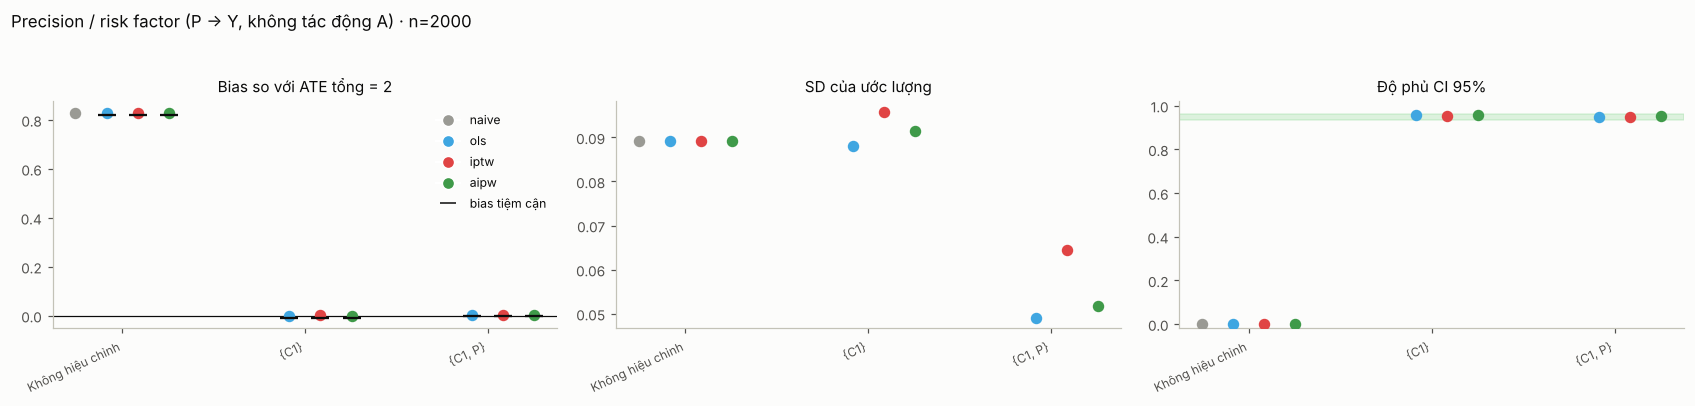

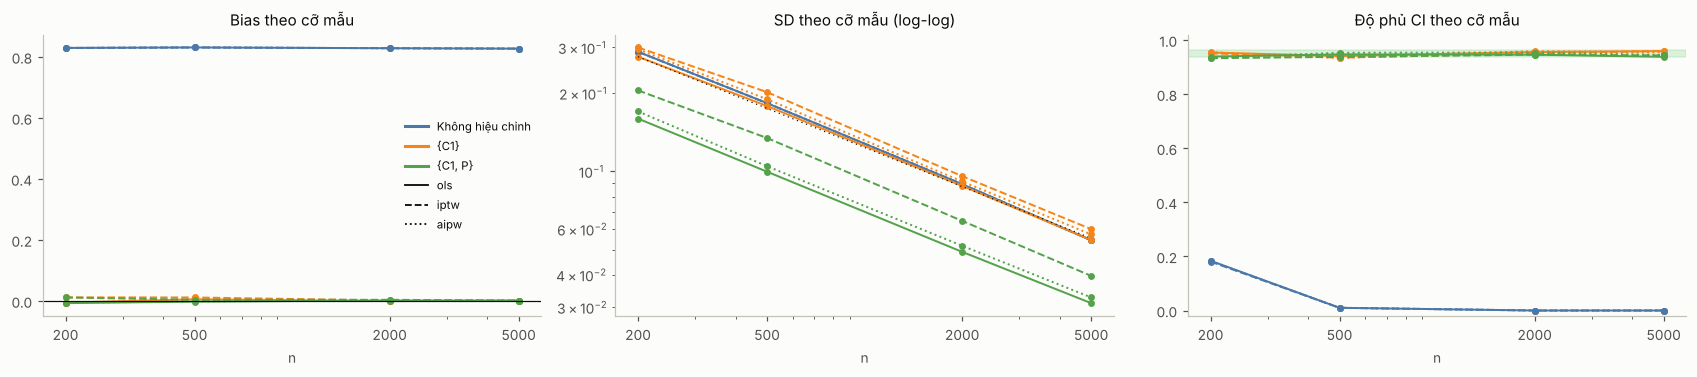

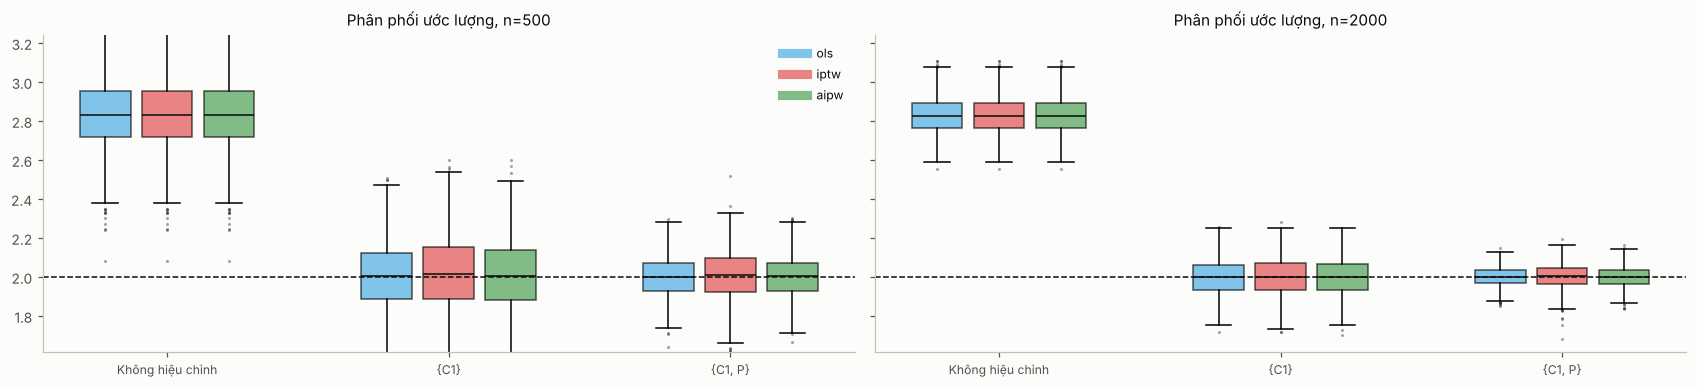

In [11]:
run_role("precision")

**Nhận xét.**

- **Bias.** Thêm $P$ không đổi bias (|bias| ≤ 0,004 ở cả hai chiến lược, $n=2000$), đúng như lý thuyết vì $P$ không nằm trên đường cửa sau.
- **Phương sai.** Ở $n=2000$, SD của OLS giảm 0,088 → 0,049, tức còn 56% so với trước, trùng khớp con số lý thuyết $1/\sqrt{1+1{,}5^2}=0{,}55$. AIPW giảm 0,091 → 0,052 (57%). Điều này hợp lý: $P$ giải thích phần lớn nhiễu của $Y$ (phương sai residual từ 3,25 xuống 1), nên sai số ước lượng hệ số $A$ nhỏ đi.
- **Dự đoán sai ở IPTW.** Ta dự đoán IPTW gần như không đổi vì $P$ không dự đoán được $A$, nhưng SD của IPTW giảm 0,096 → 0,064 (còn 67%). Giải thích mà nhóm đưa ra (dựa trên [5, 15]): khi PS được **ước lượng** từ dữ liệu và có $P$ trong mô hình, trọng số buộc hai nhóm cân bằng *trong mẫu* theo $P$; vì $P$ dự báo mạnh $Y$ nên phần nhiễu do hai nhóm lệch $P$ ngẫu nhiên cũng bị triệt tiêu. Chúng ta chưa có thí nghiệm riêng (ví dụ so sánh với PS thật đã biết) để chứng minh nguyên nhân này, nên coi đây là giải thích hợp lý chứ chưa phải kết luận.
- **Coverage** ổn định quanh 0,94–0,96 ở mọi chiến lược đã hiệu chỉnh $C_1$, và SE trung bình của IPTW (0,062) sát SD thật (0,064): SE hiệu chỉnh cho PS ước lượng đã "bắt" được phần giảm phương sai này.
- **Ý nghĩa thực hành:** khác với instrument, đưa biến chỉ dự báo $Y$ vào mô hình **luôn có lợi** (miễn là nó không bị ảnh hưởng bởi $A$). Lợi ích tăng theo độ mạnh của $P$ (xem 6.1).

### 5.4 Mediator: $A\to M\to Y$

**Cơ chế.** Áp dụng kỹ thuật làm tăng độ ẩm đất $M$, và $M$ cao làm năng suất tăng. Hiệu ứng tổng $=\tau_d+a_mb_m=1+1\cdot1=2$. Nếu hiệu chỉnh $M$ thì chặn đường gián tiếp $A\to M\to Y$, và ước lượng chỉ còn hiệu ứng trực tiếp $\tau_d=1$. Đây **không phải lỗi thống kê** mà là **sai estimand** (overadjustment, [8, 9]): bias so với hiệu ứng tổng chính xác bằng $-a_mb_m=-1$. Đồ thị dùng vạch đứt đen cho hiệu ứng tổng (2) và vạch chấm tím cho hiệu ứng trực tiếp (1). Nếu mục tiêu của nghiên cứu là hiệu ứng trực tiếp thì hiệu chỉnh $M$ lại là đúng, nhưng khi đó cần thêm giả định về confounding giữa $M$ và $Y$ [3].


**Dự đoán trước khi chạy:** hiệu chỉnh $\{C_1\}$ cho 2; hiệu chỉnh $\{C_1,M\}$ cho khoảng 1 ở cả OLS, IPTW, AIPW và coverage so với hiệu ứng tổng rơi về gần 0.

bias     sd   rmse  mean_se  coverage  ci_width  ess_ratio  max_weight
strategy method                                                                         
none     naive   0.830  0.076  0.833    0.075     0.000     0.295      0.999       2.037
         ols     0.830  0.076  0.833    0.075     0.000     0.295      0.999       2.037
         iptw    0.830  0.076  0.833    0.075     0.000     0.295      0.999       2.037
         aipw    0.830  0.076  0.833    0.075     0.000     0.295      0.999       2.037
C1       ols     0.002  0.068  0.068    0.069     0.947     0.272      0.754      17.687
         iptw    0.003  0.078  0.078    0.078     0.948     0.305      0.754      17.687
         aipw    0.002  0.072  0.072    0.073     0.946     0.285      0.754      17.687
C1+M     ols    -1.001  0.053  1.002    0.054     0.000     0.212      0.451      51.183
         iptw   -1.000  0.149  1.011    0.128     0.000     0.503      0.451      51.183
         aipw   -1.000  0.070  1.003    0.067     0.000     0.264      0.451      51.183

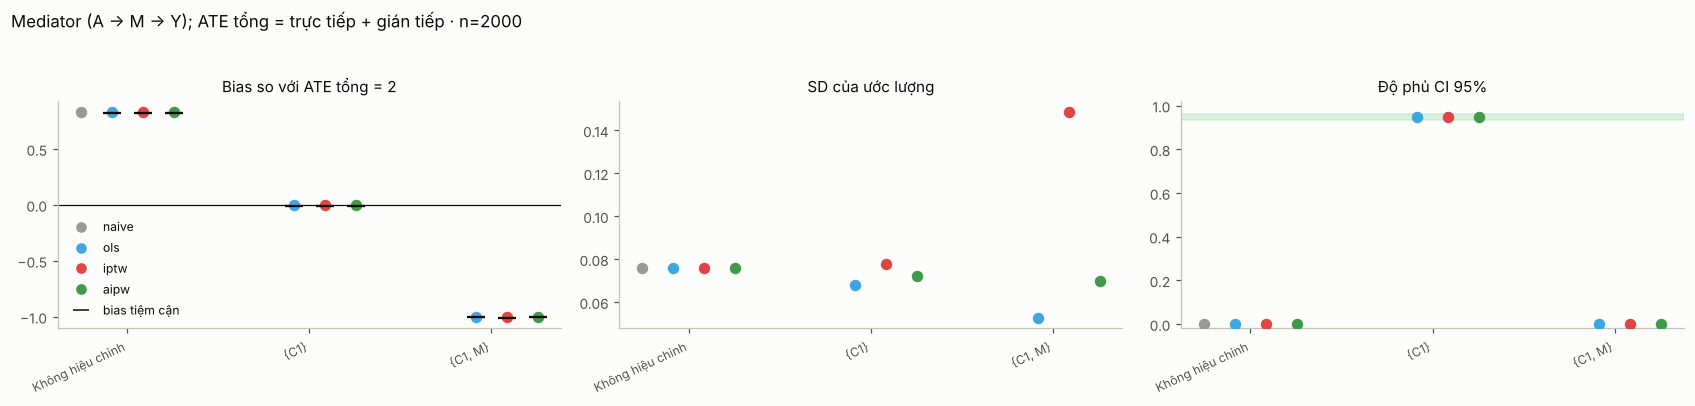

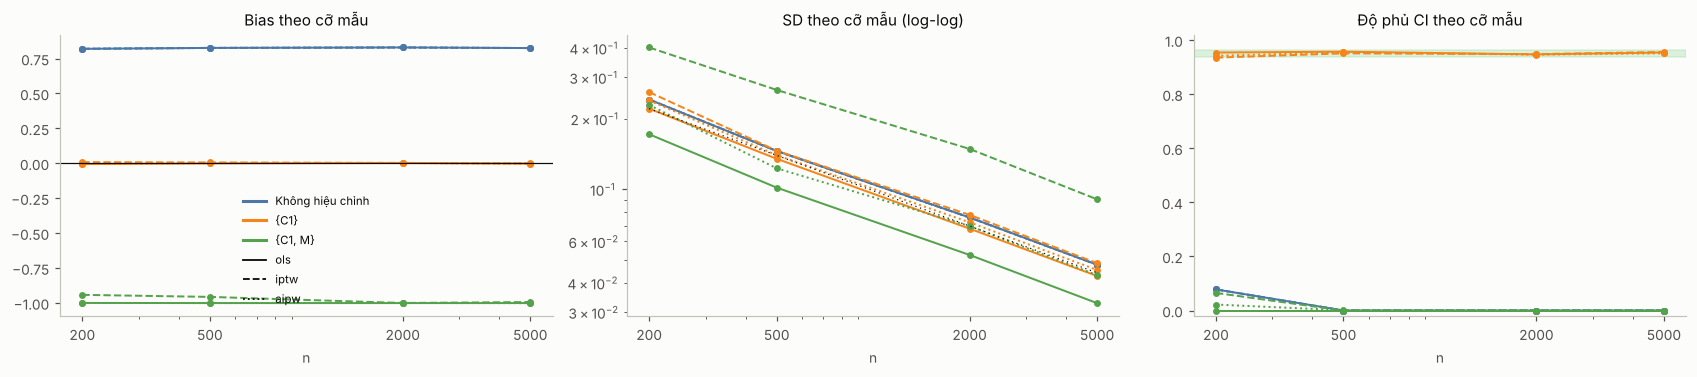

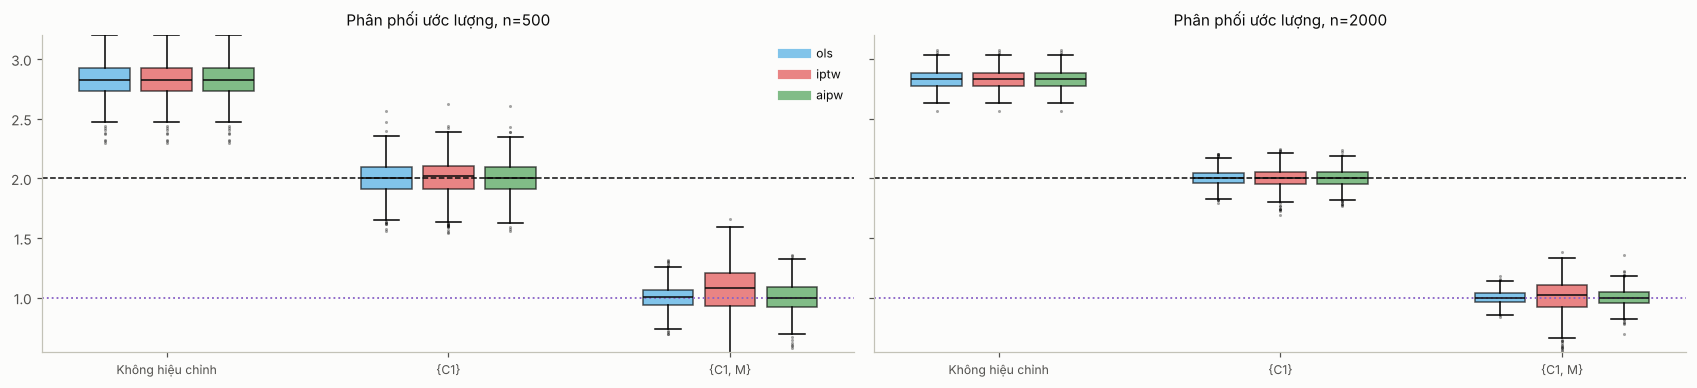

In [12]:
run_role("mediator", extra_lines=[(1.0, PURPLE, "hiệu ứng trực tiếp")])

In [13]:
# Độ phủ CI so với HAI đích: hiệu ứng tổng (2) và hiệu ứng trực tiếp (1), n=2000
raw = RAW[("mediator", 2000)]; rows = []
for s in ("C1", "C1+M"):
    for m in ("ols", "iptw", "aipw"):
        r = raw[(raw.strategy == s) & (raw.method == m)]; lo, hi = r.est - Z95 * r.se, r.est + Z95 * r.se
        rows.append({"chiến lược": s, "phương pháp": m, "trung bình ước lượng": r.est.mean(),
                     "coverage so với tổng (=2)": ((lo <= 2) & (2 <= hi)).mean(),
                     "coverage so với trực tiếp (=1)": ((lo <= 1) & (1 <= hi)).mean()})
display(pd.DataFrame(rows).round(3))

,chiến lược,phương pháp,trung bình ước lượng,coverage so với tổng (=2),coverage so với trực tiếp (=1)
0,C1,ols,2.002,0.947,0.000
1,C1,iptw,2.003,0.948,0.000
2,C1,aipw,2.002,0.946,0.000
3,C1+M,ols,0.999,0.000,0.948
4,C1+M,iptw,1.000,0.000,0.901
5,C1+M,aipw,1.000,0.000,0.948


**Nhận xét.**

- **Bias là sai estimand, không phải nhiễu.** Với `{C1}` ước lượng trung bình 2,002 (đúng hiệu ứng tổng). Khi thêm $M$, ước lượng rơi về 0,999–1,000 ở cả ba phương pháp, tức đúng **hiệu ứng trực tiếp** $\tau_d=1$ và lệch $-a_mb_m=-1$ so với hiệu ứng tổng. Bias này ổn định theo $n$ (−1,000; −1,001; −1,001; −1,001 với OLS) nên là lệch cấu trúc.
- **Bảng coverage hai đích** cho thấy rõ vấn đề: `{C1}` phủ hiệu ứng tổng 0,947 và phủ hiệu ứng trực tiếp 0,000. `{C1, M}` làm ngược lại (0,000 so với hiệu ứng tổng; 0,948 so với hiệu ứng trực tiếp với OLS và AIPW; IPTW chỉ 0,901 vì trọng số không ổn định). Vậy **mô hình `{C1, M}` không "sai", nó trả lời câu hỏi khác** [8, 9]. Với nông nghiệp: nếu câu hỏi là "áp dụng kỹ thuật tưới tiết kiệm làm năng suất tăng bao nhiêu (kể cả qua độ ẩm đất)" thì phải bỏ $M$; nếu hỏi "phần tăng không đi qua độ ẩm" thì mới giữ $M$, và khi đó cần thêm giả định không có confounding giữa $M$ và $Y$ [3].
- **Cái bẫy của việc đưa $M$ vào:** SD của OLS *giảm* từ 0,068 xuống 0,053 vì $M$ giải thích bớt nhiễu của $Y$. Mô hình "chặt" hơn, CI hẹp hơn nhưng quanh một con số khác. Chỉ nhìn SE hoặc $R^2$ thì không phát hiện được.
- **IPTW chịu giá cao nhất:** SD tăng 0,078 → 0,149 (gấp 1,9 lần), ESS/n còn 0,45, vì $M=A+\varepsilon$ dự đoán $A$ khá tốt nên PS cực đoan.
- **So với dự đoán:** đúng (hiệu chỉnh $\{C_1\}$ cho 2, $\{C_1,M\}$ cho 1, coverage so với hiệu ứng tổng bằng 0).

### 5.5 Collider hậu can thiệp: $A\to K\leftarrow Y$

**Cơ chế.** $K$ ("được chọn vào danh sách hỗ trợ/khảo sát sau vụ mùa") phụ thuộc vào cả việc áp dụng kỹ thuật lẫn năng suất. Trong dữ liệu chung, $A$ và $Y$ không có đường nào qua $K$. Nhưng khi **điều kiện hóa trên $K$** (đưa vào mô hình hoặc chỉ phân tích nhóm được chọn) thì hai nguyên nhân của $K$ trở nên liên quan: nếu $K$ cao mà $A=1$ thì không cần $Y$ cao để giải thích, nên $A$ và $Y$ tương quan **âm** trong từng lát của $K$ ("explaining away", Berkson) [2, 10]. Cả hai cạnh dương nên chiều của bias là âm. Thêm vào đó $K$ là hậu quả mạnh của $A$ nên khi đưa vào PS làm trọng số rất cực đoan.


**Dự đoán trước khi chạy:** hiệu chỉnh $\{C_1\}$ cho kết quả đúng; hiệu chỉnh $\{C_1,K\}$ gây bias **âm lớn** ở cả ba phương pháp, không giảm khi $n$ tăng, coverage về 0; IPTW bất ổn hơn (ESS rất thấp).

bias     sd   rmse  mean_se  coverage  ci_width  ess_ratio  max_weight
strategy method                                                                         
none     naive   0.831  0.062  0.833    0.061     0.000     0.237      0.999       2.037
         ols     0.831  0.062  0.833    0.061     0.000     0.237      0.999       2.037
         iptw    0.831  0.062  0.833    0.060     0.000     0.237      0.999       2.037
         aipw    0.831  0.062  0.833    0.061     0.000     0.237      0.999       2.037
C1       ols     0.003  0.048  0.048    0.049     0.953     0.193      0.754      17.687
         iptw    0.004  0.059  0.059    0.058     0.949     0.229      0.754      17.687
         aipw    0.003  0.051  0.051    0.052     0.956     0.202      0.754      17.687
C1+K     ols    -1.499  0.048  1.499    0.048     0.000     0.190      0.100     331.486
         iptw   -1.384  0.510  1.475    0.290     0.000     1.137      0.100     331.486
         aipw   -1.493  0.210  1.508    0.131     0.012     0.512      0.100     331.486

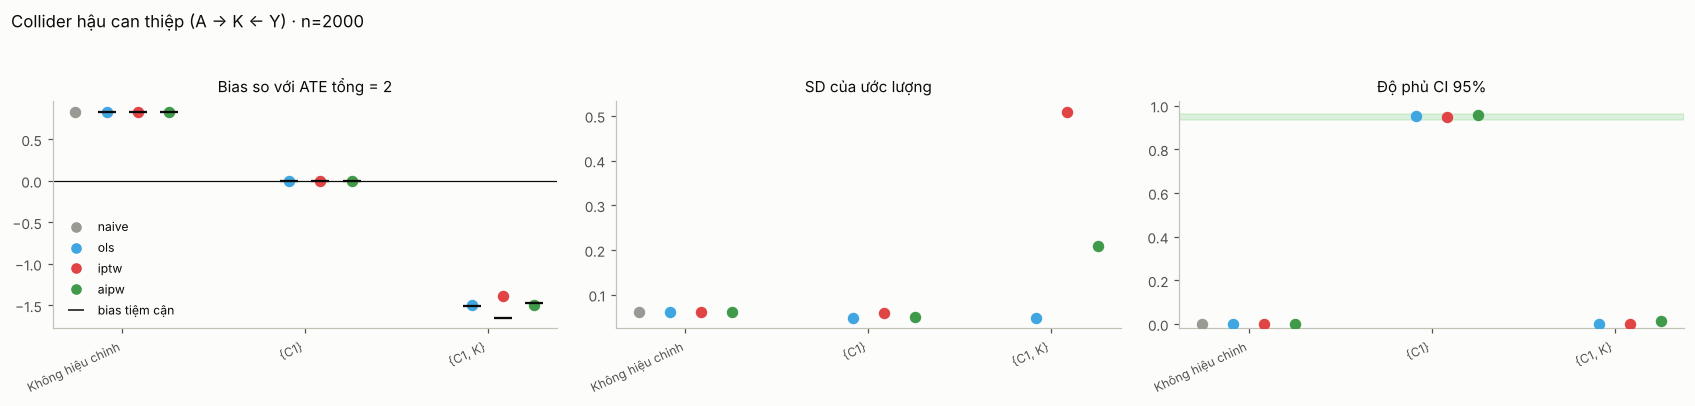

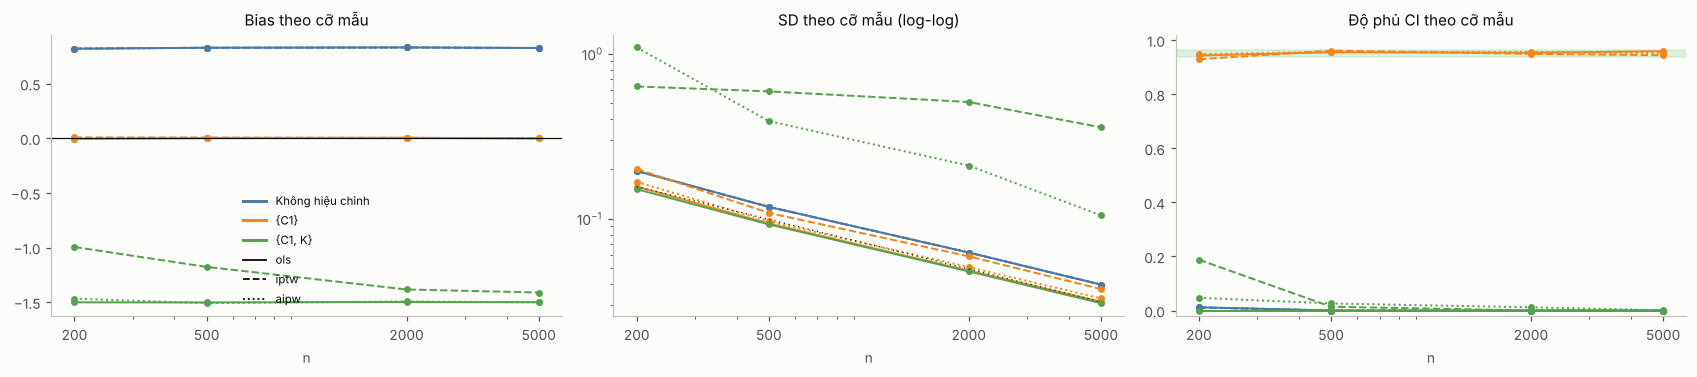

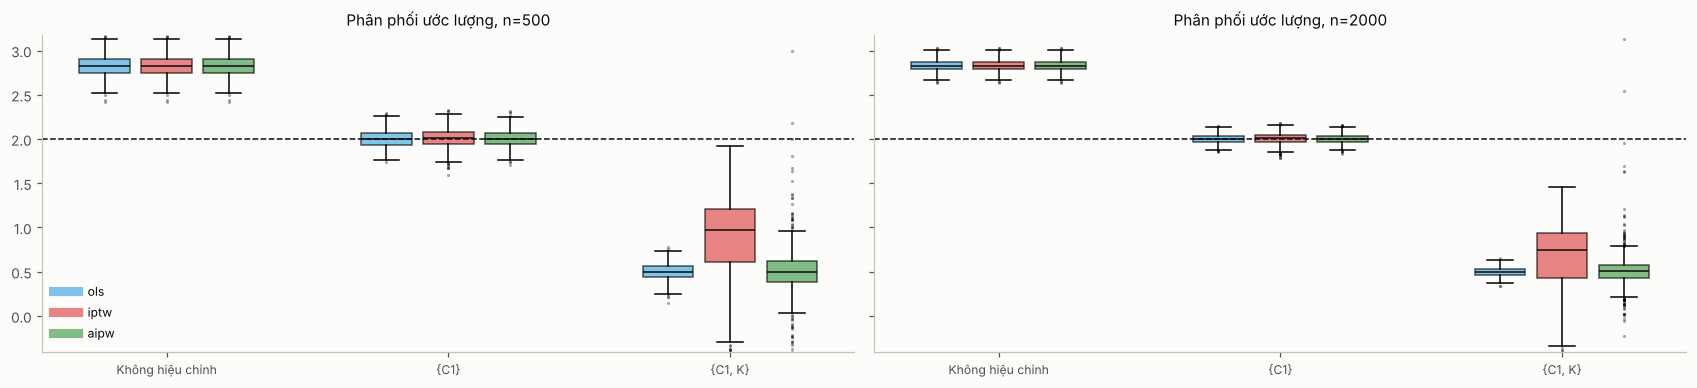

In [14]:
run_role("collider")

**Nhận xét.**

- **Bias lớn và không giảm theo $n$.** Ở $n=2000$ bias của OLS là −1,499 và AIPW −1,493, đúng bằng giá trị lý thuyết −1,5 từ công thức ở mục 3.4 ($c=0{,}5$, bias $=-0{,}5\times(1\times2+1)$). Coverage bằng 0 (OLS, AIPW) cho mọi $n$. Nghĩa là điều chỉnh nhầm một collider hậu can thiệp **biến một ước lượng đúng (2,0) thành một ước lượng sai nặng (≈ 0,5)**; ước lượng thậm chí còn đổi hẳn "độ lớn" của hiệu ứng.
- **Cơ chế (explaining away).** Trong nhóm có cùng giá trị $K$, nếu hộ đã áp dụng kỹ thuật ($A=1$) thì $K$ cao có thể giải thích được bằng $A$, nên không cần $Y$ cao nữa; ngược lại hộ không áp dụng mà vẫn có $K$ cao thì $Y$ phải cao. Vì thế trong từng lát của $K$, $A$ và $Y$ tương quan *âm* và hệ số của $A$ bị kéo xuống [2, 10].
- **OLS cho kết quả "chắc chắn nhưng sai":** SD chỉ 0,048, còn nhỏ hơn chiến lược đúng (0,049), vì $K$ chứa rất nhiều thông tin về $Y$. Đây là tình huống nguy hiểm nhất khi làm việc thực tế: SE nhỏ, $R^2$ cao nhưng đáp án sai.
- **IPTW và AIPW còn bất ổn thêm.** $K$ phụ thuộc mạnh vào $A$ nên PS gần như tất định: ESS/n chỉ 0,10, trọng số lớn nhất 331, 21% quan sát có PS ngoài [0,01; 0,99]. SD của IPTW là 0,51 (gấp 10 lần OLS), SD của AIPW 0,21, và SE trung bình *thấp hơn nhiều* SD thật (IPTW 0,29 so với 0,51; AIPW 0,13 so với 0,21), nên CI cũng không đáng tin.
- **IPTW chưa hội tụ ngay cả ở $n=5000$:** bias −0,995 ($n=200$), −1,177, −1,384, −1,412 ($n=5000$), trong khi bias tiệm cận là −1,65. Coverage 0,188 ở $n=200$ cũng không phải dấu hiệu tốt: CI rộng đến mức vô tình chứa 2 (SD 0,63), chứ không phải ước lượng chính xác.
- **Ý nghĩa thực hành:** không đưa vào mô hình bất kỳ biến nào được đo *sau* kết quả hoặc bị chọn dựa trên kết quả (ví dụ chỉ khảo sát những hộ "thành công"). Cũng nên xem ESS và trọng số lớn nhất như một **tín hiệu cảnh báo** về chọn biến sai, không chỉ về overlap.

### 5.6 Collider tiền can thiệp (M-bias): $A\leftarrow V_1\to K_0\leftarrow V_2\to Y$

**Cơ chế.** Đây là tình huống không có confounding: $V_1$ chỉ tác động $A$ và $V_2$ chỉ tác động $Y$ nên **naive đã đúng**. $K_0$ (mức sống đo được) là kết quả chung của $V_1$ và $V_2$. Vì $K_0$ được đo **trước** can thiệp nên theo thói quen "hiệu chỉnh mọi biến tiền can thiệp" người ta sẽ đưa nó vào. Khi điều kiện hóa trên $K_0$, $V_1$ và $V_2$ (độc lập trước đó) trở nên tương quan âm, mở ra đường $A\leftarrow V_1\ \cdots\ V_2\to Y$ và tạo bias [11, 13]. Ding & Miratrix chỉ ra M-bias thường nhỏ khi các cạnh vừa phải; ở đây chọn hệ số 1 để cố ý phóng đại.


**Dự đoán trước khi chạy:** naive (không hiệu chỉnh) không chệch; hiệu chỉnh $K_0$ gây bias nhỏ nhưng khác 0, không giảm khi $n$ tăng; bias âm.

bias     sd   rmse  mean_se  coverage  ci_width  ess_ratio  max_weight
strategy method                                                                         
none     naive   0.002  0.065  0.065    0.063     0.941     0.248      0.999       2.038
         ols     0.002  0.065  0.065    0.063     0.941     0.248      0.999       2.038
         iptw    0.002  0.065  0.065    0.063     0.941     0.248      0.999       2.038
         aipw    0.002  0.065  0.065    0.063     0.941     0.248      0.999       2.038
K0       ols    -0.292  0.061  0.298    0.059     0.001     0.232      0.934       6.004
         iptw   -0.292  0.061  0.298    0.059     0.001     0.233      0.934       6.004
         aipw   -0.292  0.061  0.298    0.059     0.001     0.233      0.934       6.004

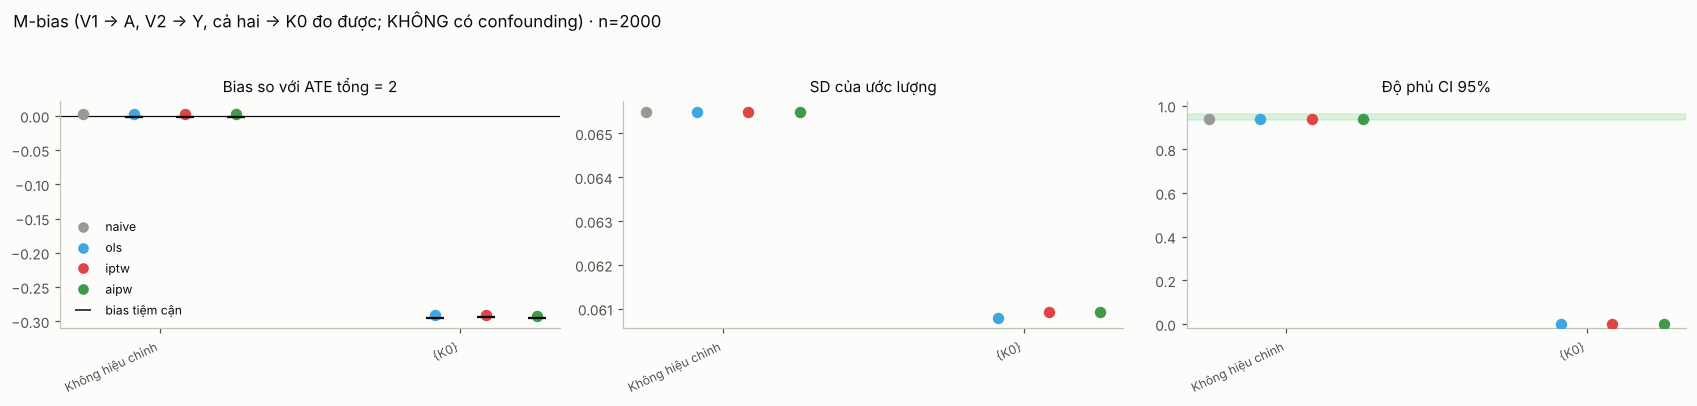

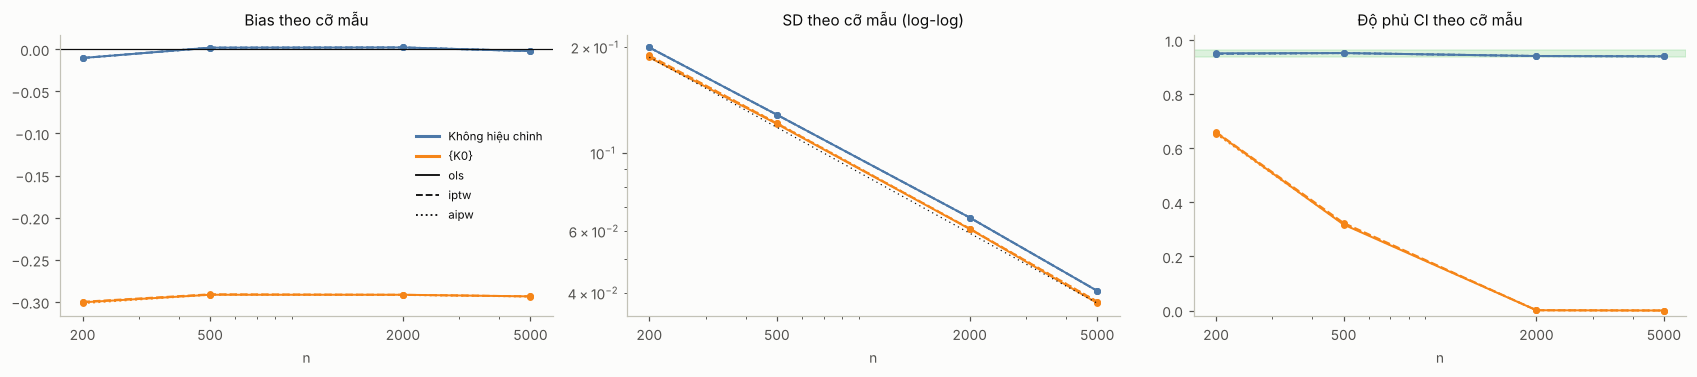

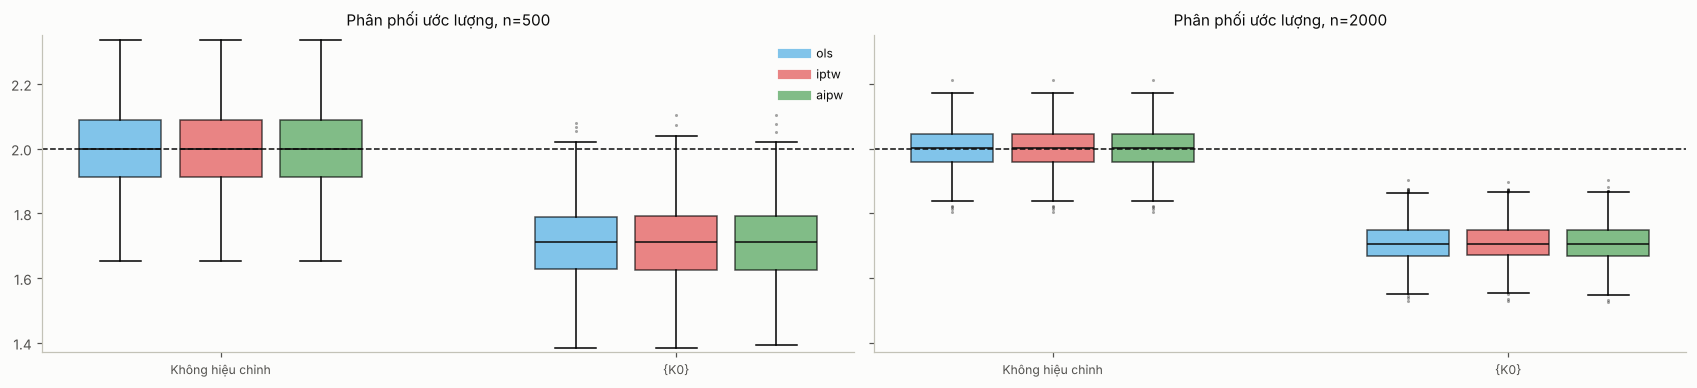

In [15]:
run_role("m_bias")

**Nhận xét.**

- **Naive đúng ở đây.** Vì không có confounding, không hiệu chỉnh gì cả cho bias ≈ 0 (0,002 ở $n=2000$) và coverage 0,94–0,95. Đây là ví dụ cho thấy "cứ hiệu chỉnh cho an toàn" không phải lúc nào cũng an toàn.
- **Bias của việc hiệu chỉnh $K_0$ là −0,29** (−0,292 ở $n=2000$, tiệm cận −0,295) và giống nhau ở ba phương pháp. Nguyên nhân: $K_0\approx V_1+V_2+\text{nhiễu}$, nên khi giữ $K_0$ cố định, $V_1$ và $V_2$ (vốn độc lập) trở nên tương quan âm; hộ có tín dụng cao hơn (dễ áp dụng) thì thích ứng thời tiết thấp hơn (năng suất thấp hơn), kéo hệ số $A$ xuống [11].
- **Bias nhỏ nhưng coverage thì sụp đổ theo $n$:** 0,66 ($n=200$), 0,32 (500), 0,001 (2000), 0,000 (5000). Lý do: bias gần như cố định (≈ −0,29) còn SD giảm theo $1/\sqrt n$; tỉ số bias/SD tăng từ 1,6 ($n=200$) lên 4,8 ($n=2000$). Vậy ở mẫu nhỏ M-bias bị nhiễu che mất, ở mẫu lớn nó lộ ra. Điều này cũng có nghĩa là một nghiên cứu có $n$ lớn **càng cần chọn biến cẩn thận**.
- **Ở chiều ngược lại,** $K_0$ trông giống một confounder yếu (SMD 0,16; mục 4), nên các quy tắc dựa vào SMD sẽ đưa nó vào. Nếu $K_0$ thực sự là confounder thì đưa vào là đúng; không có DAG thì không phân biệt được.
- **Lưu ý về độ mạnh:** chúng ta cố ý chọn hệ số 1 (xem 3.2). Ding & Miratrix [11] cho rằng M-bias thường nhỏ hơn bias do bỏ sót confounder; phép quét ở 6.2 cho thấy với hệ số 0,5, bias còn −0,14.

### 5.7 Khuếch đại bias: instrument $Z$ khi còn confounder ẩn $U$

**Cơ chế.** Giờ có confounder ẩn $U$ ($U\to A$, $U\to Y$) mà ta không đo được, nên mọi ước lượng đều còn bias. Câu hỏi: *đưa instrument $Z$ vào có giúp không?* Không những không giúp, mà còn làm **xấu hơn**. Hiệu chỉnh $Z$ loại bỏ phần biến thiên của $A$ do $Z$, phần còn lại của $A$ ít "vô tội" hơn: tỉ trọng biến thiên do $U$ cao hơn, nên $U$ gây bias nhiều hơn mỗi đơn vị biến thiên $A$ [7, 6]. Đây là lý do một số tác giả khuyên **không đưa instrument vào PS** khi nghi ngờ còn confounder ẩn.


**Dự đoán trước khi chạy:** cả hai chiến lược đều chệch dương; hiệu chỉnh $Z$ cho bias **lớn hơn** không hiệu chỉnh (khuếch đại).

bias     sd   rmse  mean_se  coverage  ci_width  ess_ratio  max_weight
strategy method                                                                         
none     naive   0.344  0.063  0.350    0.063       0.0     0.246      0.999       2.038
         ols     0.344  0.063  0.350    0.063       0.0     0.246      0.999       2.038
         iptw    0.344  0.063  0.350    0.063       0.0     0.246      0.999       2.038
         aipw    0.344  0.063  0.350    0.063       0.0     0.246      0.999       2.038
Z        ols     0.469  0.073  0.475    0.073       0.0     0.286      0.554      36.446
         iptw    0.477  0.085  0.485    0.084       0.0     0.328      0.554      36.446
         aipw    0.478  0.086  0.486    0.084       0.0     0.330      0.554      36.446

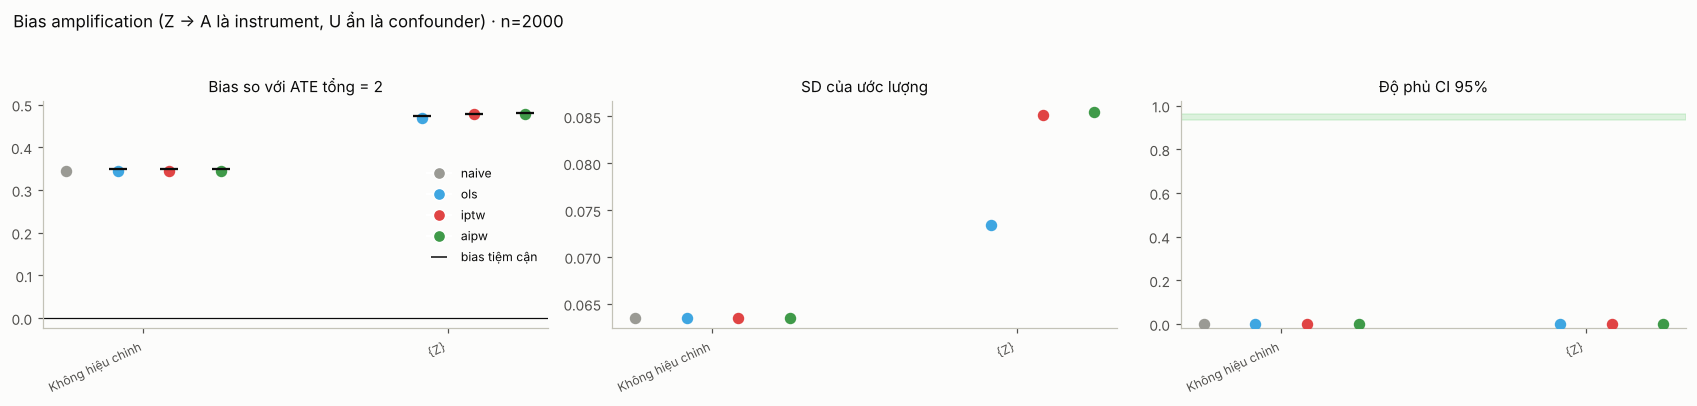

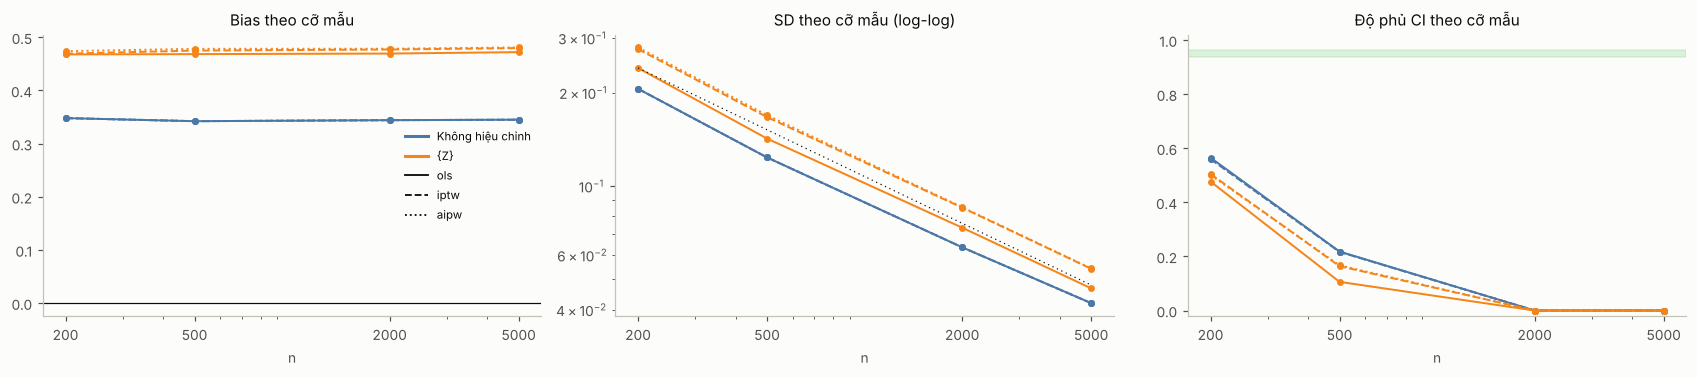

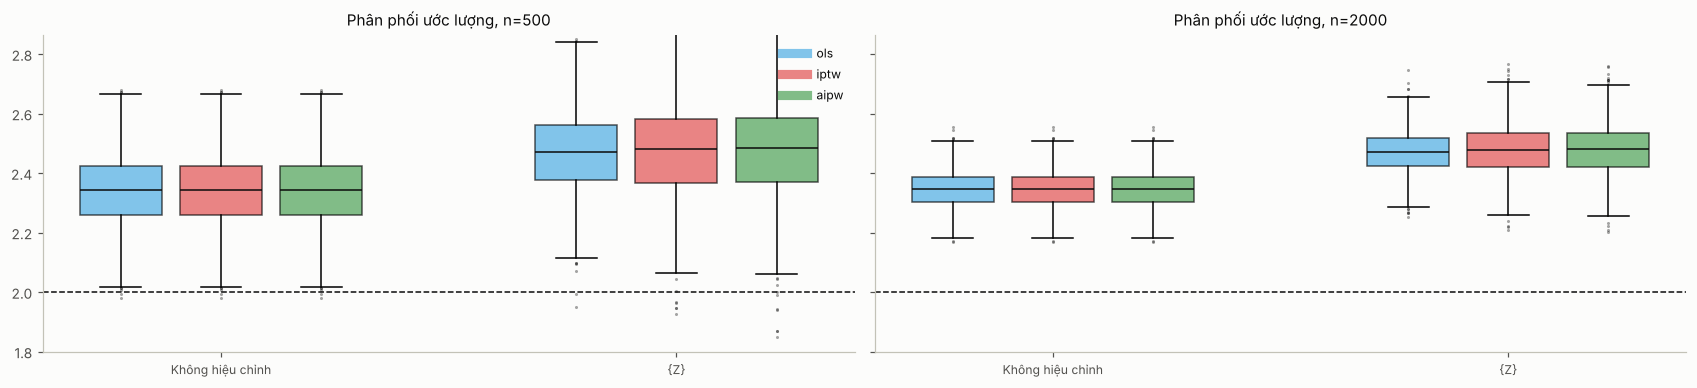

In [16]:
run_role("amplification")

**Nhận xét.**

- **Cả hai chiến lược đều sai, nhưng có một chiến lược sai hơn.** Ở $n=2000$ bias không hiệu chỉnh là +0,344, còn khi hiệu chỉnh $Z$ là +0,469 (OLS), +0,477 (IPTW), +0,478 (AIPW), tức **tăng khoảng 36%**. Bias tiệm cận cũng cho kết quả tương tự (0,348 → 0,480). Coverage đều bằng 0 từ $n=2000$.
- **Cơ chế (dựa trên [7, 6]).** Logit của PS có hai nguồn biến thiên: $Z$ (hệ số 1,5) và $U$ (0,5). Nếu không hiệu chỉnh, $U$ chỉ giải thích một phần nhỏ biến thiên của $A$ (khoảng $0{,}25/2{,}5=10\%$ phương sai logit). Khi giữ $Z$ cố định, phần biến thiên còn lại của $A$ *gần như toàn bộ do $U$*, nên mọi sự khác biệt giữa nhóm áp dụng và không áp dụng đều mang dấu vết của $U$ nhiều hơn, tức bias lớn hơn. Hiểu theo cách đó, hiệu chỉnh $Z$ đưa ta về đúng mức bias khi $Z$ không tồn tại (0,473, xem 6.2).
- **Phương sai cũng tăng** (SD 0,063 → 0,073 với OLS; 0,085–0,086 với IPTW, AIPW; ESS/n 0,55), như ở mục 5.2.
- **Bài học:** khi nghi còn confounder không đo, **không** đưa vào những biến chỉ dự đoán $A$. Ngoài ra, AIPW "doubly robust" cũng không giúp: tính bền vững kép bảo vệ trước sai mô hình, không bảo vệ trước confounder bị bỏ sót [14].

### 5.8 Proxy của confounder: chỉ đo được $W=C_1+\varepsilon_W$

**Cơ chế.** Chất lượng đất thật ($C_1$) không đo được, ta chỉ có chỉ số $W$ đo có sai số. $W$ không chặn hoàn toàn đường cửa sau $A\leftarrow C_1\to Y$: sau khi hiệu chỉnh $W$ vẫn còn phần $C_1$ không được $W$ giải thích, gọi là *residual confounding* [12]. Độ tin cậy (reliability) $\lambda=\operatorname{Var}(C_1)/\operatorname{Var}(W)=1/(1+w^2)$ quyết định mức giảm bias: $\lambda=1$ (không có sai số đo) thì hiệu chỉnh trọn vẹn, $\lambda\to0$ thì như không hiệu chỉnh.


**Dự đoán trước khi chạy:** hiệu chỉnh $W$ giảm bias so với không hiệu chỉnh nhưng **không** về 0 (khoảng một nửa còn lại với $w=1$); bias không giảm theo $n$.

bias     sd   rmse  mean_se  coverage  ci_width  ess_ratio  max_weight
strategy method                                                                         
none     naive   0.830  0.059  0.832    0.060       0.0     0.237      0.999       2.037
         ols     0.830  0.059  0.832    0.060       0.0     0.237      0.999       2.037
         iptw    0.830  0.059  0.832    0.060       0.0     0.237      0.999       2.037
         aipw    0.830  0.059  0.832    0.060       0.0     0.237      0.999       2.037
W        ols     0.455  0.057  0.458    0.056       0.0     0.221      0.897       7.949
         iptw    0.456  0.058  0.460    0.057       0.0     0.224      0.897       7.949
         aipw    0.455  0.057  0.459    0.057       0.0     0.223      0.897       7.949

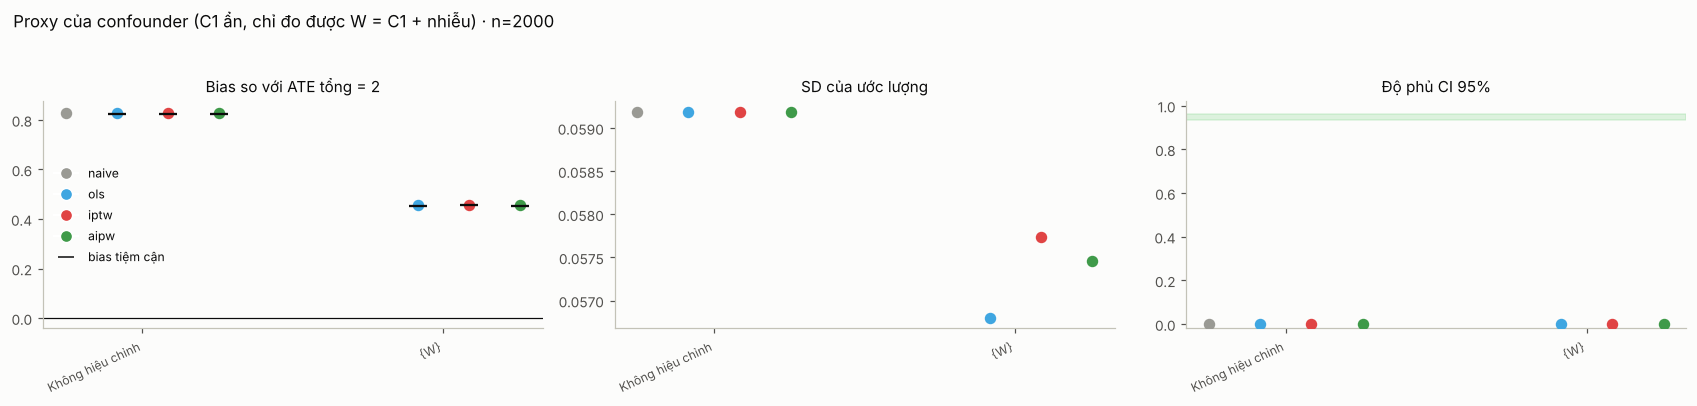

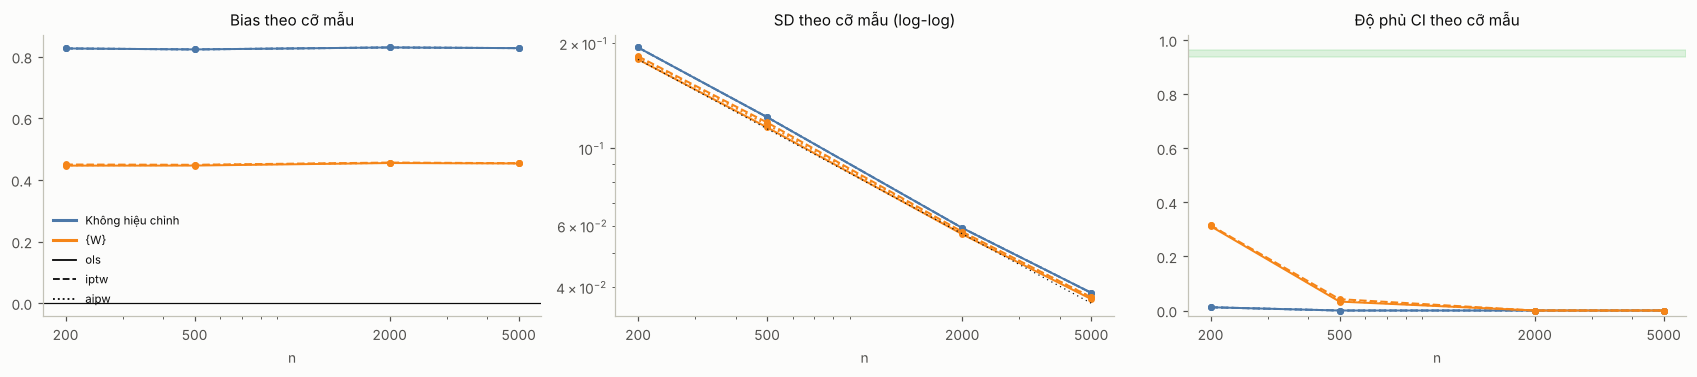

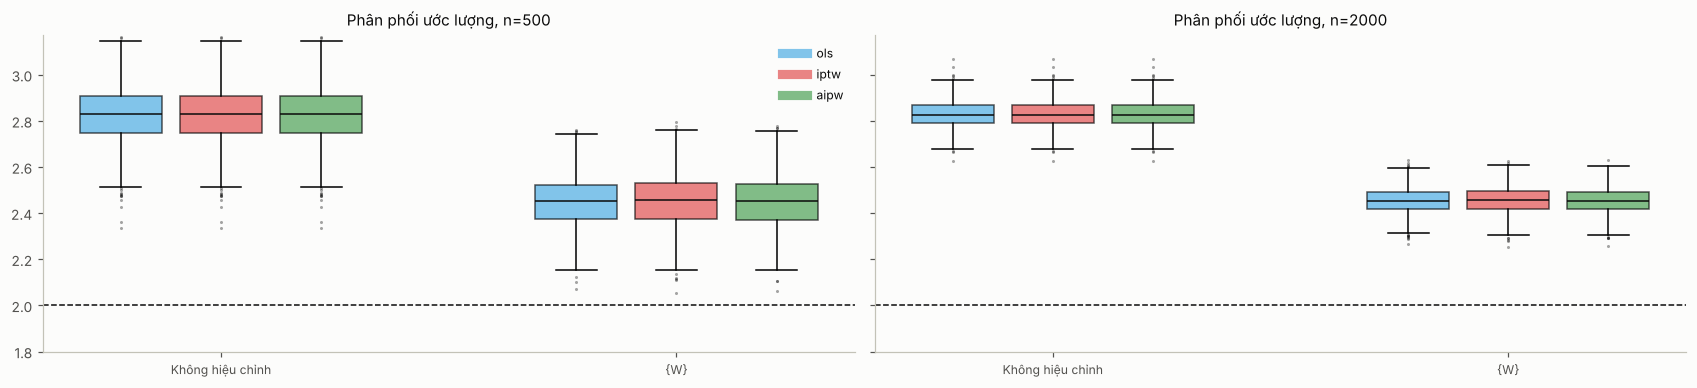

In [17]:
run_role("proxy")

**Nhận xét.**

- **Giảm được một phần.** Bias giảm từ +0,830 xuống +0,455 ở $n=2000$ (−45%), nên phần bias còn lại là khoảng 55%, gần với $1-\lambda=0{,}5$ khi độ tin cậy là 0,5. Không có sự khác biệt giữa OLS, IPTW và AIPW (0,455; 0,456; 0,455). Vấn đề ở đây là **thông tin còn thiếu** (W chỉ chứa một nửa phương sai của $C_1$) chứ không phải dạng mô hình, và tính chất doubly robust không bù được [12, 14].
- **Coverage vẫn bằng 0 từ $n=2000$** (0,31 ở $n=200$, 0,03 ở $n=500$). SD gần như không đổi (0,057 so với 0,059), nên CI hẹp quanh một giá trị còn lệch gần 0,46. Đưa proxy vào là *tốt hơn không đưa*, nhưng suy luận (CI, p-value) vẫn sai; kết quả cần đi kèm phân tích độ nhạy (ví dụ E-value [18]) và nói rõ trong bài rằng còn residual confounding.
- **So với dự đoán:** đúng (giảm nhưng không về 0, không giảm theo $n$).

## 6. Quét tham số: bias và phương sai phụ thuộc thế nào vào độ mạnh của cạnh

Các kết quả ở mục 5 dùng một giá trị tham số cố định. Để chắc rằng kết luận không phải "ăn may" theo giá trị chọn, chúng ta quét độ mạnh của từng cạnh đặc trưng (xem `SWEEPS` trong `simulation.py`), với $n=2000$ và 400 lần lặp mỗi điểm. Vạch đứt là bias tiệm cận (mẫu lớn) của AIPW, dùng làm tham chiếu.

In [18]:
def run_sweep(scn, reps=SWEEP_REPS, n=SWEEP_N, methods=("ols", "iptw", "aipw")):
    label, grid = SWEEPS[scn]; out = []
    for v, ov in grid:
        sim = RoleSimulation(scn, **ov)
        s, _ = monte_carlo(sim, n=n, reps=reps, methods=methods, seed=SEED, n_jobs=2)
        s["x"] = v
        s["asym"] = [asymptotic_bias(sim, sim.strategies[st]["adjust"], m, n=ASYM_N // 2) if m == "aipw" else np.nan
                     for st, m in zip(s.strategy, s.method)]
        out.append(s)
    return label, pd.concat(out, ignore_index=True)

t0 = time.time()
SWP = {scn: run_sweep(scn) for scn in SWEEPS}
print(f"xong {len(SWEEPS)} phép quét trong {time.time()-t0:.0f}s")

def plot_sweep(scn, third="coverage"):
    label, d = SWP[scn]; sim = RoleSimulation(scn); strat = list(sim.strategies)
    ls = {"ols": "-", "iptw": "--", "aipw": ":"}
    fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.5))
    for ax, (col, ttl) in zip(axes, [("bias", "Bias"), ("sd", "SD"), (third, {"coverage": "Độ phủ CI 95%", "ess_ratio": "ESS/n của IPTW"}[third])]):
        for i, s in enumerate(strat):
            for m in ("ols", "iptw", "aipw"):
                r = d[(d.strategy == s) & (d.method == m)].sort_values("x")
                if col == "ess_ratio" and m != "iptw": continue
                ax.plot(r.x, r[col], ls[m], marker="o", ms=3.5, color=STRAT_COL[i], lw=1.3)
            if col == "bias":
                r = d[(d.strategy == s) & (d.method == "aipw")].sort_values("x")
                ax.plot(r.x, r.asym, color=STRAT_COL[i], lw=0, marker="_", ms=14, mew=1.6, alpha=0.8)
        ax.set_xlabel(label); ax.set_title(ttl)
        if col == "bias": ax.axhline(0, color=INK, lw=0.8)
        if col == "coverage": ax.axhspan(0.95 - Z95 * np.sqrt(0.95 * 0.05 / SWEEP_REPS), 0.95 + Z95 * np.sqrt(0.95 * 0.05 / SWEEP_REPS), color="#7ED386", alpha=0.25); ax.set_ylim(-0.02, 1.02)
    axes[0].legend(handles=[Line2D([0], [0], color=STRAT_COL[i], lw=2, label=sim.strategies[s]["label"]) for i, s in enumerate(strat)]
                   + [Line2D([0], [0], color=INK, ls=ls[m], lw=1.2, label=m) for m in ls]
                   + [Line2D([0], [0], marker="_", color=INK, lw=0, markersize=10, label="bias tiệm cận (AIPW)")], frameon=False, fontsize=7.5)
    fig.suptitle(f"Quét tham số, kịch bản '{scn}': {sim.info['title']}", x=0.01, ha="left", fontsize=10.5); fig.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

xong 7 phép quét trong 83s


### 6.1 Instrument và precision: ảnh hưởng chủ yếu lên phương sai
Hai kịch bản này không gây bias; điều cần xem là SD, ESS và coverage khi độ mạnh của biến tăng. Với instrument, hình thứ ba là ESS/n của trọng số IPTW.

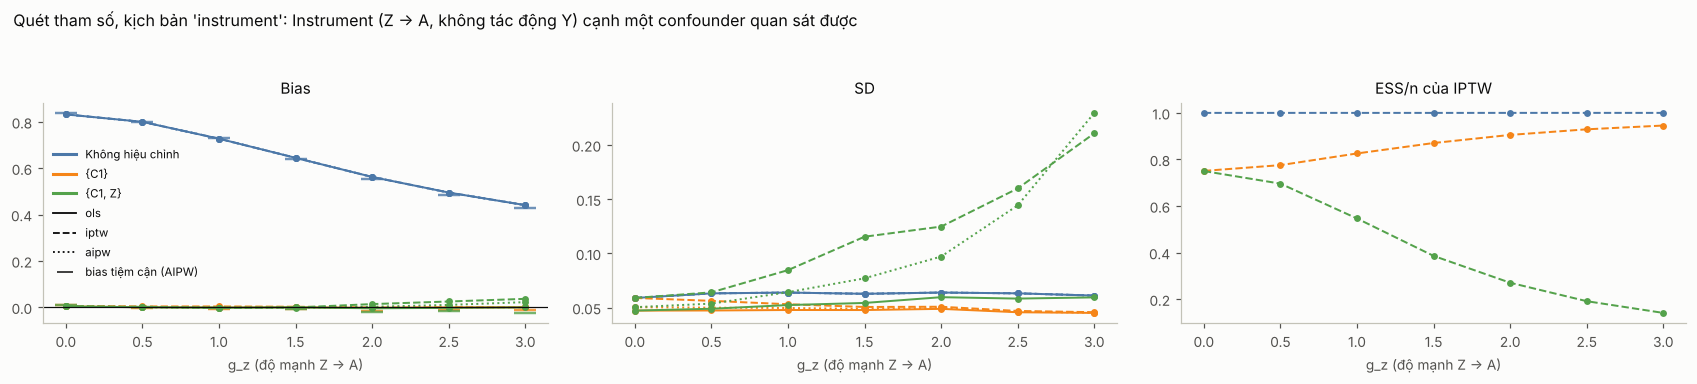

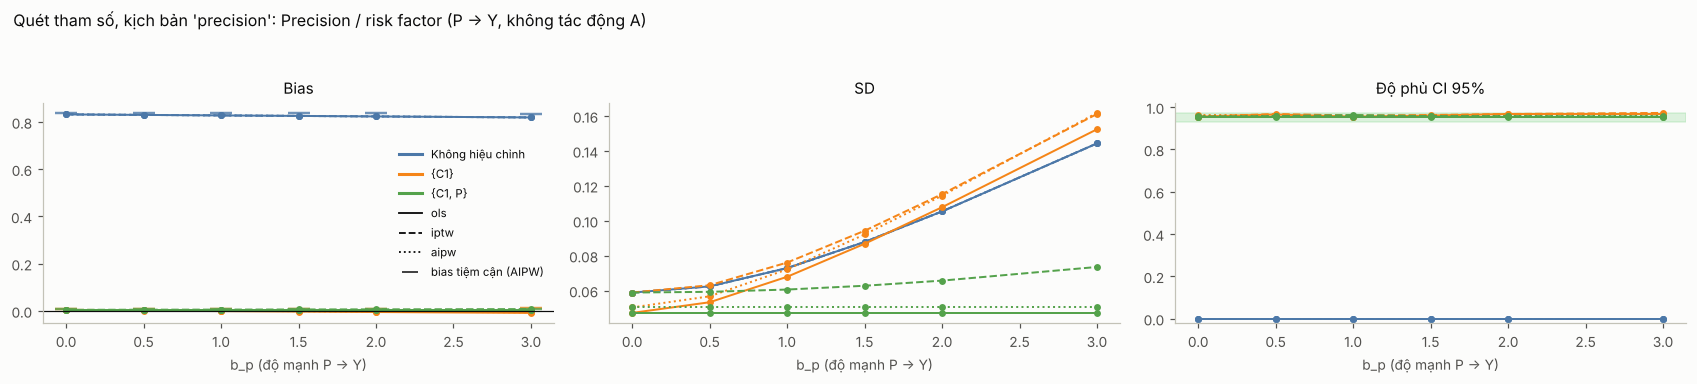

In [19]:
plot_sweep("instrument", third="ess_ratio"); plot_sweep("precision")

**Nhận xét.**

*Instrument.* Khi $g_z$ tăng từ 0 đến 3:
- Naive (không hiệu chỉnh) **giảm** bias từ 0,83 xuống 0,44 (hiệu ứng pha loãng đã nói ở 3.4), còn `{C1}` luôn không lệch với ESS/n tăng nhẹ (0,75 → 0,95).
- Thêm $Z$ vào: OLS gần như không đổi (SD 0,047 → 0,059), nhưng IPTW (0,059 → 0,211) và AIPW (0,050 → 0,230) tăng gấp **4 đến 5 lần**; ESS/n của IPTW rơi từ 0,75 xuống 0,14. IPTW còn bắt đầu có bias nhỏ (0,036 tại $g_z=3$) và coverage 0,86 vì PS quá cực đoan. AIPW coverage vẫn khoảng 0,95 nhưng bằng cách mở rộng CI.
- Một chi tiết đáng chú ý: ở $g_z$ lớn AIPW có SD *lớn hơn* IPTW (0,230 so với 0,211), tức tính "ổn định" của AIPW không còn khi trọng số quá cực đoan. Giải thích có thể là mô hình outcome phải ngoại suy ở vùng đuôi có rất ít quan sát; nhóm chưa kiểm chứng riêng điều này.

*Precision.* Khi $b_p$ tăng từ 0 đến 3:
- Không có $P$, SD của OLS tăng theo $\sqrt{1+b_p^2}$ (0,047 → 0,152; công thức cho 0,149); có $P$ thì **hằng số 0,047**. AIPW có $P$ cũng hằng số 0,050. IPTW có $P$ tăng nhẹ từ 0,059 lên 0,074 (so với 0,161 khi không có $P$).
- Bias và coverage không đổi (≈ 0, 0,96).

Kết luận: tác hại của instrument và lợi ích của precision đều **tăng theo độ mạnh** của biến, và phụ thuộc phương pháp: instrument hại IPTW/AIPW nhiều hơn OLS; precision lợi OLS/AIPW nhiều hơn IPTW.

### 6.2 Mediator, collider, M-bias, khuếch đại bias và proxy: ảnh hưởng lên bias
Vạch đứt ngắn là bias tiệm cận. Nếu đường mô phỏng bám sát vạch này tức là sai lệch hoàn toàn mang tính cấu trúc.

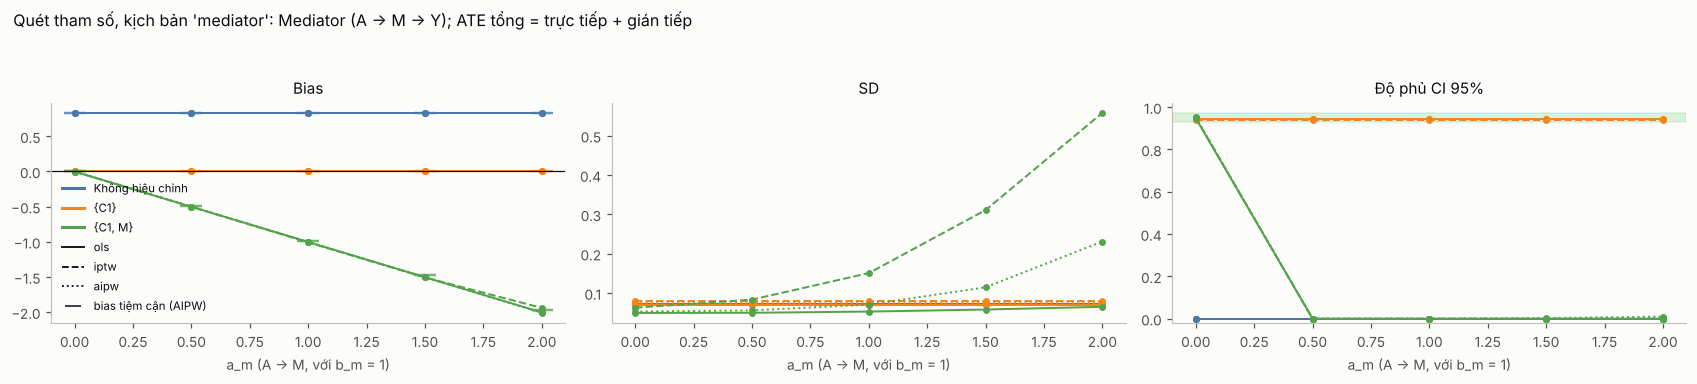

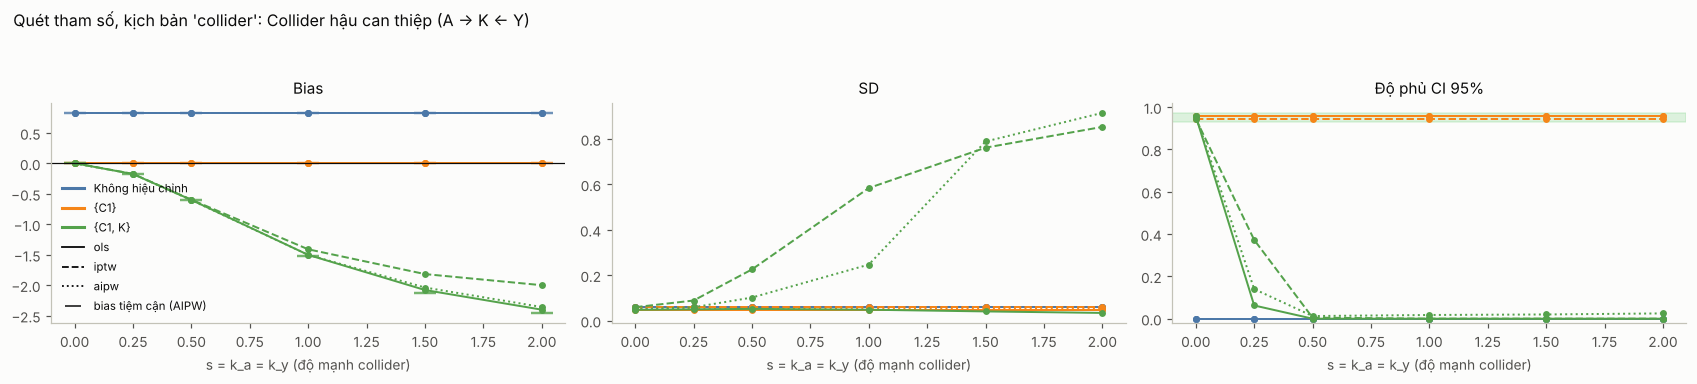

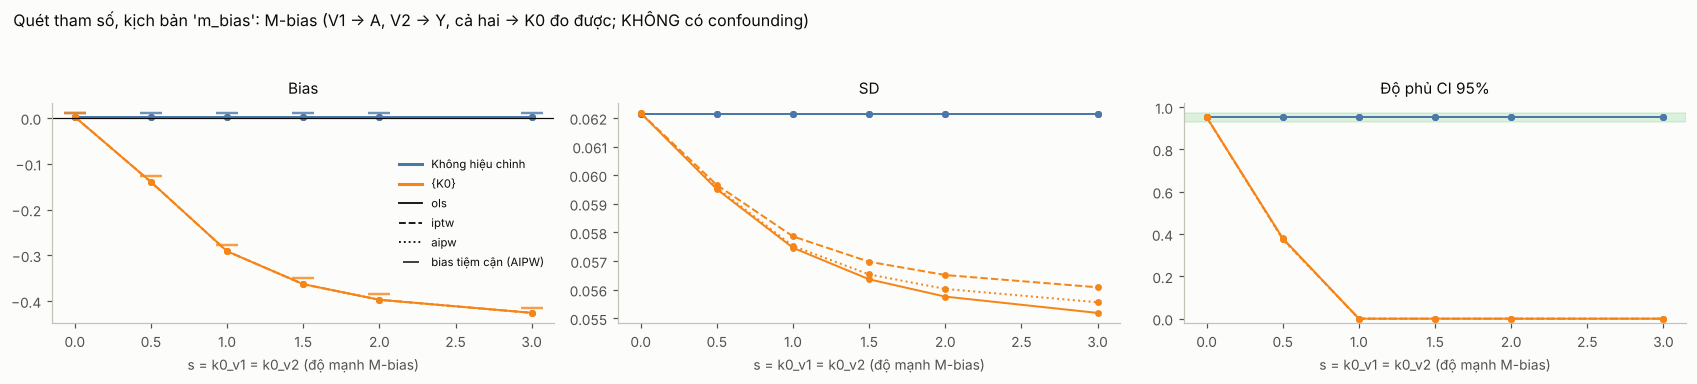

In [20]:
for s in ("mediator", "collider", "m_bias"): plot_sweep(s)

**Nhận xét.**

*Mediator.* (Lưu ý ở đây ATE đích là $1+a_m$ nên thay đổi theo trục $x$; bias được tính so với đích tương ứng.) Bias của `{C1, M}` là **đúng bằng $-a_m$**: −0,50; −1,00; −1,50; −2,00 với $a_m=0{,}5\ldots2$, ở cả ba phương pháp. Khi $a_m=0$, $M$ không còn là trung gian mà chỉ là một biến chỉ dự đoán $Y$ (precision), nên bias bằng 0 và SD thậm chí giảm (0,049 so với 0,069). Phép quét cho thấy cùng một biến $M$ có thể là biến "tốt" hoặc "xấu" tùy vào việc $A$ có tác động lên nó hay không, minh họa rằng vai trò do cấu trúc quyết định chứ không do bản thân biến. IPTW chịu thiệt nặng: SD tăng từ 0,063 ($a_m=0$) lên 0,558 ($a_m=2$) khi $M$ trở thành bộ dự đoán gần hoàn hảo của $A$.

*Collider.* Bias của OLS là −0,17; −0,60; −1,50; −2,08; −2,40 với $s=0{,}25;0{,}5;1;1{,}5;2$. Công thức đóng ở mục 3.4, $-c(k_y\tau+k_a)$ với $c=sv/(s^2v+1)$, cho −0,18; −0,60; −1,50; −2,08; −2,40: khớp đến chữ số thứ hai. Hai điểm đáng chú ý: (1) một collider rất yếu ($s=0{,}25$) đã làm coverage của OLS rơi xuống 0,06; (2) bias bão hòa dần khi $s$ lớn nhưng SD của IPTW và AIPW tăng vọt (0,76–0,92 khi $s\ge1{,}5$), tức khi collider mạnh, các phương pháp dùng trọng số không còn dùng được.

*M-bias.* Bias của `{K0}` là −0,14; −0,29; −0,36; −0,40; −0,43 với $s=0{,}5;1;1{,}5;2;3$ và **bão hòa**: tăng $s$ từ 1 lên 3 chỉ làm bias tăng thêm 0,13. Điều này hợp lý vì độ tương quan âm giữa $V_1$ và $V_2$ khi biết $K_0$ có giới hạn. Coverage ở $n=2000$ đã rơi xuống 0,38 ngay tại $s=0{,}5$. Ngoài ra SD hơi *giảm* khi $s$ tăng (0,062 → 0,055) vì $K_0$ mang một ít thông tin về $V_2$ (một nguyên nhân của $Y$), nghĩa là biến này vừa tăng chính xác vừa tạo bias, và chỉ nhìn SE thì không thấy cái giá phải trả.

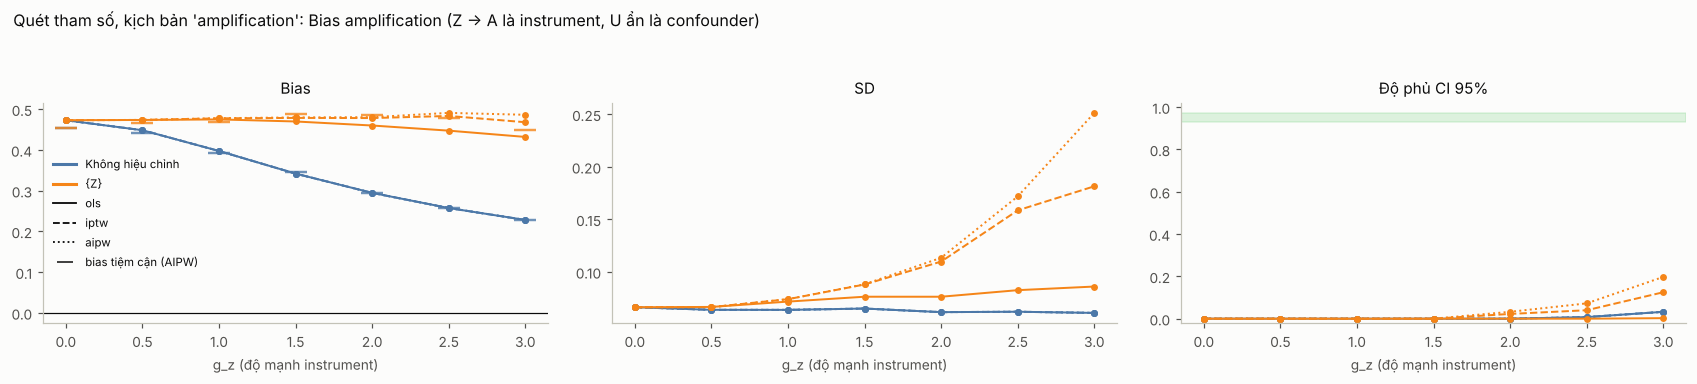

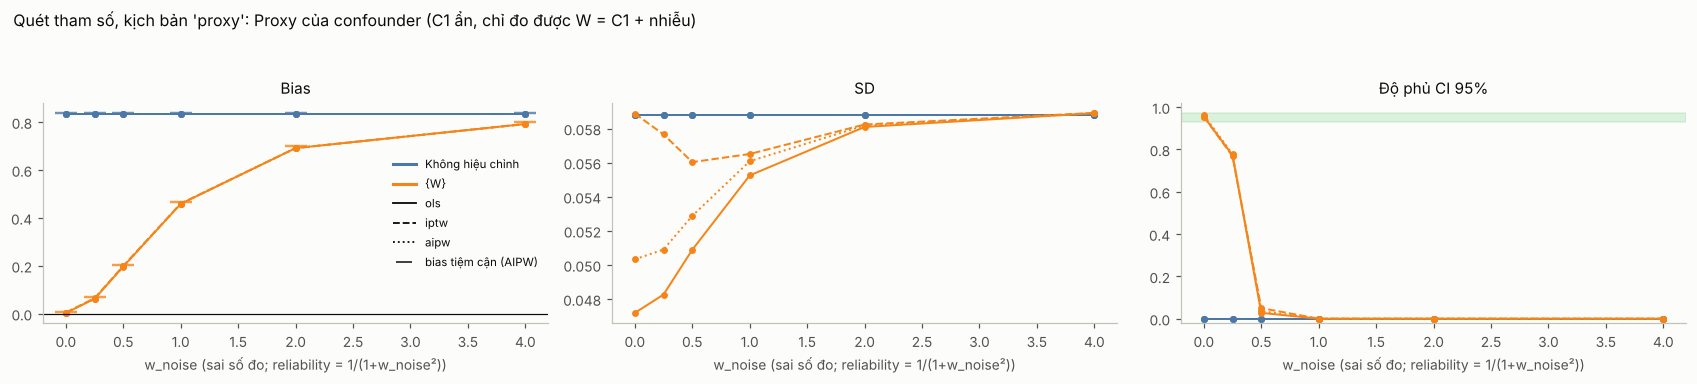

In [21]:
for s in ("amplification", "proxy"): plot_sweep(s)

**Nhận xét.**

*Khuếch đại bias.* Đường `{Z}` gần như **nằm ngang tại 0,47** (OLS từ 0,473 xuống 0,432, IPTW/AIPW 0,47–0,49), đúng bằng bias khi $Z$ không tồn tại ($g_z=0$: 0,473). Trong khi đó bias khi *không* hiệu chỉnh giảm từ 0,473 xuống 0,228 khi $g_z$ tăng, vì $Z$ pha loãng vai trò của $U$. Do đó mức khuếch đại $\approx$ bias(`{Z}`)/bias(`none`) tăng từ 1 ($g_z=0$) lên khoảng 2,1 ($g_z=3$: 0,468 so với 0,228 với IPTW; 0,486 so với 0,228 với AIPW). Nói cách khác, instrument càng mạnh thì việc hiệu chỉnh nó càng "tốn kém", và SD của IPTW/AIPW cũng tăng (0,18/0,25 ở $g_z=3$). Phép quét này kiểm chứng giải thích ở 5.7.

*Proxy.* Bias còn lại của `{W}`: 0,003; 0,062; 0,197; 0,459; 0,691; 0,792 với $w=0;0{,}25;0{,}5;1;2;4$. Chia cho bias gốc (0,832) ta có tỉ lệ còn lại 0,004; 0,075; 0,24; 0,55; 0,83; 0,95, xấp xỉ $1-\lambda$ với $\lambda=1/(1+w^2)$ (0; 0,06; 0,20; 0,50; 0,80; 0,94), cao hơn một chút. Cho thấy độ tin cậy của phép đo là đại lượng quyết định chất lượng điều chỉnh. Coverage ở $n=2000$ cũng rất nhạy: chỉ cần $w=0{,}25$ (độ tin cậy 0,94, tức proxy "khá tốt") là coverage đã còn 0,77, và từ $w=0{,}5$ trở đi gần bằng 0. Hàm ý cho thực nghiệm: đo confounder bằng chỉ số nhiễu thì nên coi **kết quả là cận trên** của hiệu ứng thực và báo cáo kèm phân tích độ nhạy.

## 7. Kịch bản tổng hợp: "đưa hết biến vào mô hình" có tốt không?

Trong dữ liệu thật các vai trò xuất hiện **cùng lúc**. Kịch bản `kitchen_sink` có 2 confounder ($C_1,C_2$), 1 instrument ($Z$), 1 precision ($P$), 1 mediator ($M$), 1 collider hậu can thiệp ($K$) và một cặp M-bias ($K_0$ đo được, $V_1,V_2$ ẩn). Tám chiến lược hiệu chỉnh được so sánh, từ không hiệu chỉnh gì, tập tối thiểu theo DAG, tập "mọi biến tiền can thiệp" (hay được khuyên theo Rubin) đến "kitchen sink" (tất cả cột). Tập khuyến nghị theo DAG do `recommended_adjustment_set` suy ra.

Vai trò suy ra từ DAG: {'M': 'mediator', 'Z': 'instrument', 'C2': 'confounder', 'C1': 'confounder', 'K': 'collider (hậu can thiệp)', 'K0': 'collider (M-bias)', 'P': 'precision'}
Tập hiệu chỉnh khuyến nghị: ['C1', 'C2', 'P']


,tập hiệu chỉnh,mô tả,ghi chú
none,{},Không hiệu chỉnh,
conf,"{C1, C2}",Chỉ confounder,tập tối thiểu theo backdoor
conf+P,"{C1, C2, P}",+ precision,tập khuyến nghị
conf+P+Z,"{C1, C2, P, Z}",+ instrument,
pre-all,"{C1, C2, P, Z, K0}",Mọi biến trước can thiệp,kể cả collider M-bias
conf+M,"{C1, C2, M}",confounder + mediator,
conf+K,"{C1, C2, K}",confounder + collider,
all,"{C1, C2, P, Z, K0, M, K}",Tất cả (kitchen sink),'cứ có biến là đưa vào'


bias     sd   rmse  mean_se  coverage  ci_width  ess_ratio  max_weight
strategy method                                                                         
none     naive   0.559  0.090  0.567    0.088     0.000     0.347      0.999       2.038
         ols     0.559  0.090  0.567    0.088     0.000     0.347      0.999       2.038
         iptw    0.559  0.090  0.567    0.088     0.000     0.347      0.999       2.038
         aipw    0.559  0.090  0.567    0.088     0.000     0.347      0.999       2.038
conf     ols    -0.000  0.088  0.088    0.085     0.937     0.334      0.867       9.810
         iptw    0.001  0.089  0.089    0.087     0.942     0.342      0.867       9.810
         aipw   -0.000  0.089  0.089    0.086     0.936     0.339      0.867       9.810
conf+P   ols    -0.002  0.073  0.073    0.071     0.943     0.278      0.866       9.873
         iptw   -0.000  0.076  0.076    0.073     0.942     0.288      0.866       9.873
         aipw   -0.002  0.074  0.074    0.072     0.939     0.282      0.866       9.873
conf+P+Z ols    -0.001  0.076  0.076    0.075     0.947     0.294      0.696      22.411
         iptw    0.001  0.089  0.089    0.086     0.940     0.336      0.696      22.411
         aipw   -0.001  0.083  0.083    0.080     0.934     0.314      0.696      22.411
pre-all  ols    -0.067  0.076  0.101    0.074     0.849     0.291      0.674      24.526
         iptw   -0.065  0.090  0.111    0.087     0.887     0.342      0.674      24.526
         aipw   -0.068  0.083  0.107    0.080     0.854     0.314      0.674      24.526
conf+M   ols    -1.001  0.081  1.004    0.079     0.000     0.308      0.553      35.437
         iptw   -0.996  0.121  1.003    0.117     0.000     0.459      0.553      35.437
         aipw   -1.000  0.092  1.004    0.090     0.000     0.353      0.553      35.437
conf+K   ols    -2.295  0.052  2.296    0.050     0.000     0.197      0.310      81.018
         iptw   -2.253  0.278  2.270    0.218     0.000     0.853      0.310      81.018
         aipw   -2.294  0.076  2.296    0.072     0.000     0.281      0.310      81.018
all      ols    -2.114  0.045  2.115    0.046     0.000     0.180      0.174     159.499
         iptw   -2.032  0.403  2.071    0.280     0.000     1.097      0.174     159.499
         aipw   -2.110  0.108  2.112    0.088     0.002     0.344      0.174     159.499

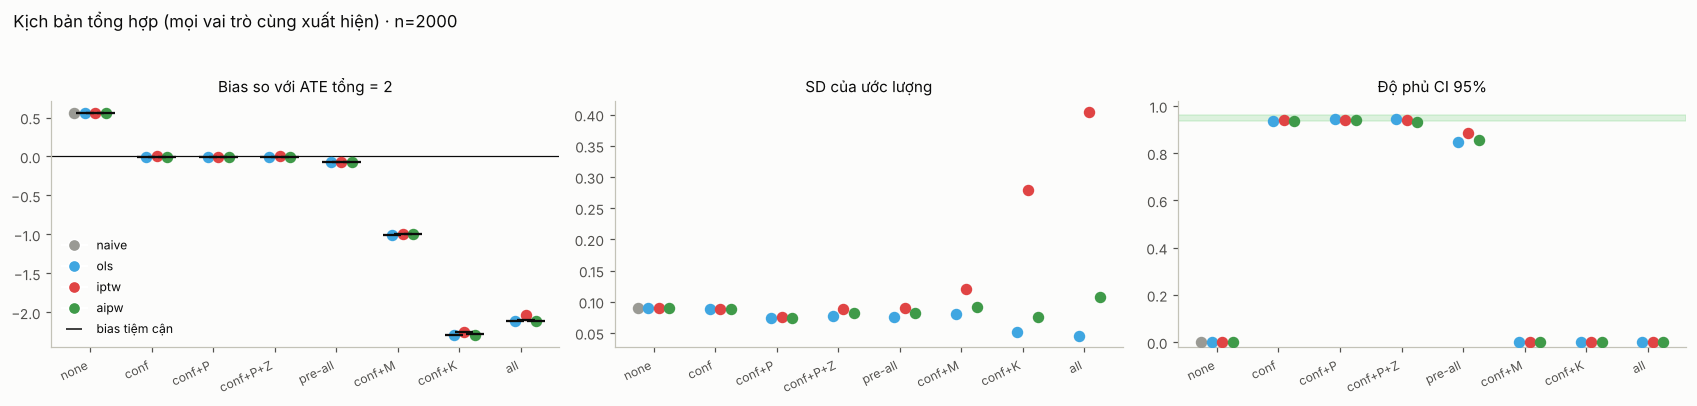

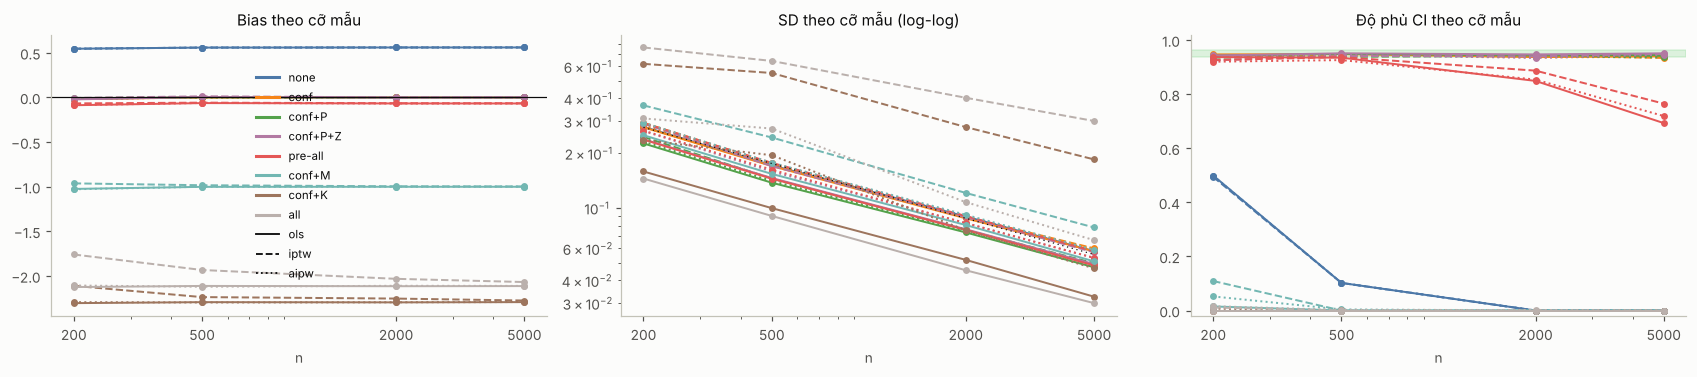

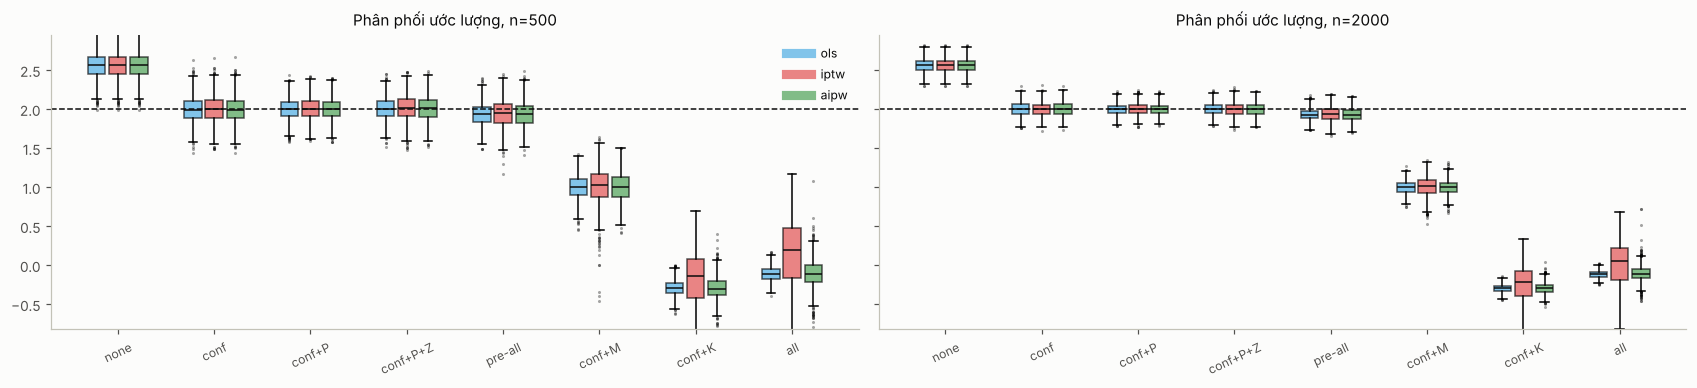

In [22]:
sim = RoleSimulation("kitchen_sink")
print("Vai trò suy ra từ DAG:", {k: v for k, v in classify_roles(sim.dag()["edges"]).items() if k in sim.observed})
print("Tập hiệu chỉnh khuyến nghị:", recommended_adjustment_set(sim.dag()["edges"], sim.observed))
display(pd.DataFrame({k: {"tập hiệu chỉnh": "{" + ", ".join(v["adjust"]) + "}", "mô tả": v["label"], "ghi chú": v["note"]} for k, v in sim.strategies.items()}).T)
run_role("kitchen_sink")

**Nhận xét** ($n=2000$, các con số theo OLS/IPTW/AIPW nếu không nói rõ).

- **`none`:** bias +0,56, coverage 0.
- **`conf` (tập tối thiểu theo backdoor):** bias ≈ 0 (|bias| ≤ 0,001), SD 0,088–0,089, coverage 0,936–0,942. Đây là mốc chuẩn.
- **`conf+P` (tập khuyến nghị):** vẫn không lệch, SD giảm xuống 0,073 (OLS), 0,076 (IPTW), 0,074 (AIPW); RMSE thấp nhất trong 8 chiến lược. Mức giảm (~17%) nhỏ hơn ở kịch bản precision vì ở đây $P$ chiếm một phần nhỏ hơn trong phương sai của $Y$ (đã có thêm nhiễu từ $M$, $V_2$).
- **`conf+P+Z` (thêm instrument):** không lệch nhưng SD tăng (0,076; 0,089; 0,083) và ESS/n giảm từ 0,87 xuống 0,70. Do $g_z=0{,}8$ vừa phải, cái giá ở đây nhẹ hơn nhiều so với kịch bản instrument ($g_z=1{,}5$).
- **`pre-all` ("mọi biến đo trước can thiệp", kể cả $K_0$):** bias nhỏ (−0,065 đến −0,068, gần giá trị tiệm cận −0,073) nhưng **coverage giảm theo $n$**: OLS 0,937 ($n=200$) → 0,849 (2000) → 0,693 (5000). Cái bẫy ở đây là ở $n$ nhỏ không thấy lỗi gì.
- **`conf+M`:** bias −1,00 ở cả ba phương pháp (hiệu ứng trực tiếp thay vì hiệu ứng tổng), coverage bằng 0.
- **`conf+K`:** bias −2,30 (OLS), −2,25 (IPTW), −2,29 (AIPW); coverage bằng 0. Con số lớn hơn −1,5 ở kịch bản collider đơn lẻ vì $Y$ ở đây nhiễu hơn ($v\approx3{,}25$ do còn $P$, $M$, $V_2$), nên $c=v/(v+1)\approx0{,}76$ và bias $=-c(\tau+1)\approx-2{,}29$. Dòng này khớp với công thức mục 3.4 và cho thấy **bias của collider tăng khi $Y$ nhiễu hơn**.
- **`all` (đưa hết các cột vào):** bias −2,11 (OLS), −2,03 (IPTW), −2,11 (AIPW). Tệ hơn *không hiệu chỉnh gì* (+0,56) khoảng 3,8 lần, và RMSE là 2,1 so với 0,073 của tập khuyến nghị, **gấp ~29 lần**. ESS/n chỉ còn 0,17 và 8,6% PS nằm ngoài [0,01; 0,99]. Coverage bằng 0 (AIPW 0,002).
- **Các phương pháp không khác nhau về bản chất.** Ở những chiến lược sai, OLS cho SD nhỏ nhất (0,045 ở `all`) tức "sai một cách chắc chắn nhất"; IPTW có SD lớn nhất (0,40). AIPW là doubly robust nhưng cả hai mô hình nuisance đều dùng cùng tập biến sai, nên không cứu được.

**Kết luận của mục này:** trong dữ liệu có nhiều vai trò lẫn lộn, chất lượng ước lượng **do chọn biến quyết định hơn là do chọn phương pháp**. Ba chiến lược đầu của nhóm hiệu chỉnh đúng (`conf`, `conf+P`, `conf+P+Z`) có RMSE 0,073–0,089, trong khi các chiến lược chứa mediator/collider có RMSE 1,0–2,3.

### 7.1 Bản đồ nhiệt: chiến lược × phương pháp
Hình dưới gom bias, RMSE và coverage của các phương pháp theo chiến lược ($n=2000$). Ô bias và RMSE tô đỏ càng đậm càng sai nhiều; ô coverage đỏ = CI mất độ tin cậy, xanh = gần 0,95. Cột `naive` không dùng biến nên giống nhau ở mọi hàng.

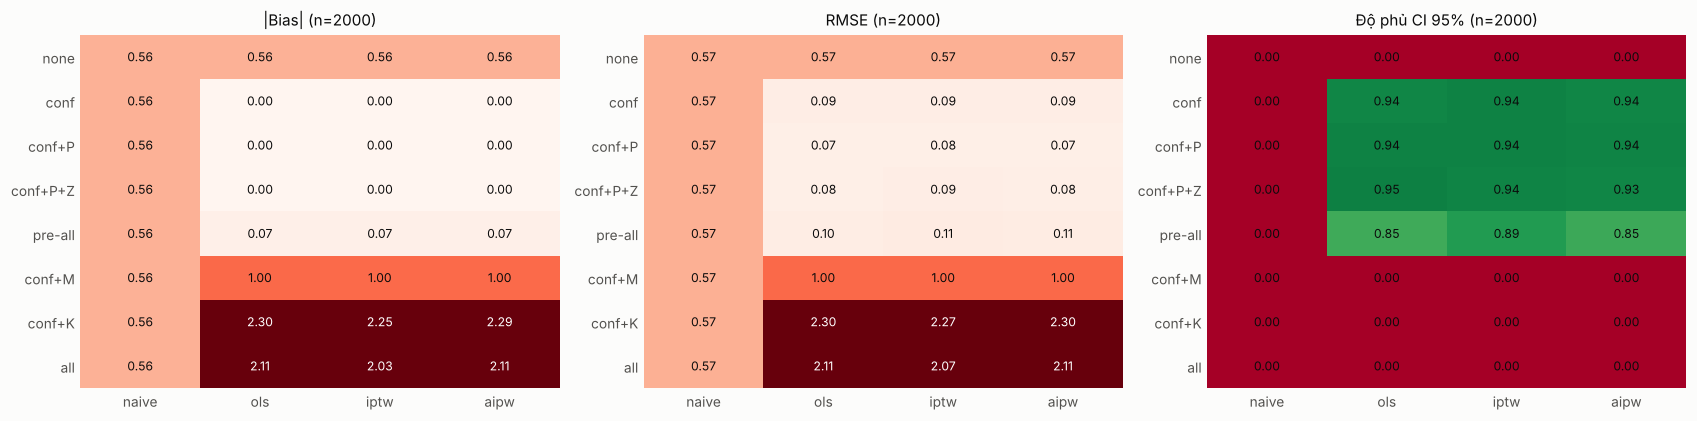

In [23]:
def heat(ax, M, title, fmt="{:.2f}", cmap="Reds", vmin=None, vmax=None):
    im = ax.imshow(M.to_numpy(float), cmap=cmap, aspect="auto", vmin=vmin, vmax=vmax)
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            v = M.iloc[i, j]
            ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=8, color="white" if (cmap == "Reds" and im.norm(v) > 0.62) else INK)
    ax.set_xticks(range(M.shape[1])); ax.set_xticklabels(M.columns); ax.set_yticks(range(M.shape[0])); ax.set_yticklabels(M.index)
    ax.set_title(title); ax.tick_params(length=0)
    for s in ax.spines.values(): s.set_visible(False)

sim = RoleSimulation("kitchen_sink"); d = RES[(RES.scenario == "kitchen_sink") & (RES.n == 2000)]
order = list(sim.strategies); lab = {k: sim.strategies[k]["label"] for k in order}
def piv(col): return d.pivot(index="strategy", columns="method", values=col).loc[order, ["naive", "ols", "iptw", "aipw"]]
fig, axes = plt.subplots(1, 3, figsize=(15.5, 3.9))
heat(axes[0], piv("bias").abs(), "|Bias| (n=2000)", cmap="Reds", vmin=0, vmax=2)
heat(axes[1], piv("rmse"), "RMSE (n=2000)", cmap="Reds", vmin=0, vmax=2)
heat(axes[2], piv("coverage"), "Độ phủ CI 95% (n=2000)", cmap="RdYlGn", vmin=0, vmax=1)
fig.tight_layout(); plt.show()

### 7.2 Kiểm tra balance: chẩn đoán SMD có "bắt" được lỗi chọn biến không?

Cuối cùng xem chẩn đoán balance (`balance_after_strategy`). Với mỗi chiến lược, ước lượng PS **chỉ từ tập hiệu chỉnh**, tính trọng số IPTW rồi kiểm tra SMD của **mọi** biến quan sát. Lưu ý với mediator $M$ và collider $K$ (hậu can thiệp), SMD sau trọng số không có ý nghĩa nhân quả; chúng được in để thấy PS "dùng" chúng mạnh thế nào.

,trước trọng số,conf,conf+P+Z,pre-all,all
C1,0.594,0.012,0.016,0.001,0.089
C2,0.364,0.005,0.011,0.010,0.061
Z,0.615,0.712,-0.015,-0.018,0.010
P,-0.008,-0.002,0.019,0.025,-0.040
K0,0.163,0.186,0.222,-0.030,0.018
M,0.997,1.014,1.049,1.049,0.032
K,1.622,1.360,1.396,1.368,0.093


Chẩn đoán trọng số IPTW theo chiến lược (n=5000):


,conf,conf+P+Z,pre-all,all
n,5000.000,5000.000,5000.000,5000.000
ess,4293.004,3464.811,3232.175,570.211
ess_ratio,0.859,0.693,0.646,0.114
ess_treated,2090.596,1626.122,1533.659,760.050
ess_control,2206.407,1857.717,1710.540,185.999
max_weight,10.475,26.055,36.625,242.807
p99_weight,5.025,7.365,7.322,13.838


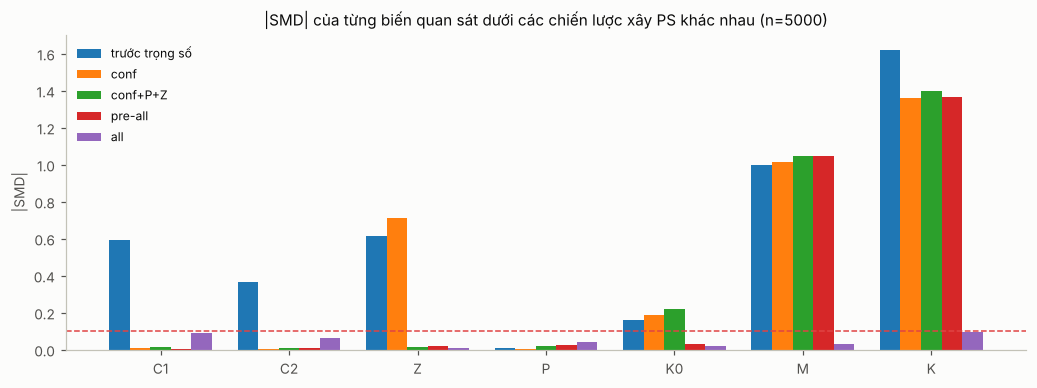

In [24]:
sim = RoleSimulation("kitchen_sink", seed=SEED); df = sim.generate(n=5000)
out = {}
for s in ("conf", "conf+P+Z", "pre-all", "all"):
    t = balance_after_strategy(df, sim.strategies[s]["adjust"], sim.observed)
    out[s] = t["smd_after"].astype(float)
before = balance_table(df, sim.observed)["smd_before"].astype(float)
bal = pd.DataFrame(out); bal.insert(0, "trước trọng số", before)
display(bal.round(3))
wd = {}
for s in ("conf", "conf+P+Z", "pre-all", "all"):
    e_s = estimate_ps(df, sim.strategies[s]["adjust"])
    wd[s] = weight_diagnostics(df.A.to_numpy(), iptw_weights(df.A.to_numpy(), e_s))
print("Chẩn đoán trọng số IPTW theo chiến lược (n=5000):"); display(pd.DataFrame(wd).round(3))
fig, ax = plt.subplots(figsize=(9.5, 3.6)); x = np.arange(len(bal)); w = 0.8 / bal.shape[1]
for j, c in enumerate(bal.columns):
    ax.bar(x + j * w - 0.4 + w / 2, bal[c].abs(), w, label=c)
ax.axhline(0.1, color=RED, ls="--", lw=1); ax.set_xticks(x); ax.set_xticklabels(bal.index); ax.set_ylabel("|SMD|")
ax.set_title("|SMD| của từng biến quan sát dưới các chiến lược xây PS khác nhau (n=5000)"); ax.legend(frameon=False, fontsize=8)
fig.tight_layout(); plt.show()

**Nhận xét.**

- **Trọng số chỉ cân bằng được những biến có trong mô hình PS.** Với PS chỉ từ $\{C_1,C_2\}$ (`conf`), SMD của $C_1$ giảm từ 0,594 xuống 0,012 và $C_2$ từ 0,364 xuống 0,005, nhưng $Z$ (0,615 → 0,712), $K_0$, $M$, $K$ không được cải thiện. Với biến $Z$, $K_0$ điều đó **không phải vấn đề** (một là instrument, một là collider); với $M$ và $K$ thì việc không cân bằng cũng là đúng ý, vì cân bằng chúng đồng nghĩa với việc xóa tác động của $A$ lên chúng.
- **Kịch bản `all` cho SMD "đẹp" một cách đáng ngờ.** $M$ và $K$ có SMD sau trọng số chỉ 0,032 và 0,093 (dưới ngưỡng 0,1), nên theo tiêu chí SMD thì mọi thứ đều cân bằng. Nhưng chính việc "cân bằng" hai biến này là nguồn của bias −2,1 ở mục 7. Hơn nữa, lúc này ESS/n chỉ còn 0,114 và trọng số lớn nhất 243 (so với 0,859 và 10,5 ở `conf`), và $C_1$, $C_2$ lại cân bằng *kém hơn* (0,089 và 0,061 so với 0,012 và 0,005), vì PS bị chi phối bởi $M$, $K$.
- **SMD không "bắt" được lỗi chọn biến.** Kiểm tra balance chỉ nói rằng *các biến đã chọn* được cân bằng, không nói rằng *các biến đã chọn là đúng*. Với `pre-all`, $K_0$ có SMD −0,03 sau trọng số, tức một người chỉ nhìn bảng này sẽ cho là mô hình rất tốt, trong khi bias −0,07 là do chính $K_0$.
- **Chẩn đoán hữu ích hơn trong trường hợp này là ESS và trọng số lớn nhất.** Chúng tăng/giảm đúng theo mức độ "xấu" của tập biến: ESS/n = 0,86 (`conf`), 0,69 (`conf+P+Z`), 0,65 (`pre-all`), 0,11 (`all`). ESS thấp bất thường khi thêm một biến là dấu hiệu để xem lại vai trò của biến đó (có phải hậu quả của $A$ không?).
- **Cân bằng phải đi cùng DAG.** Khi quy trình thực tế, báo cáo balance nên chia thành *biến tiền can thiệp* (phải cân bằng) và *biến hậu can thiệp* (không đưa vào, không kiểm tra balance).

## 8. Tổng hợp: quy tắc rút ra cho từng vai trò

Bảng dưới được **tính từ kết quả** (AIPW, $n=2000$): bias và SD của chiến lược "nên dùng" và chiến lược "dễ nhầm" ở mỗi vai trò, kèm đối chiếu với bias tiệm cận.

,tập cơ sở,tập sau khi thêm,bias cơ sở,bias sau,SD cơ sở,SD sau,coverage cơ sở,coverage sau
biến được thêm vào,,,,,,,,
confounder C1,none,C1,0.829,0.001,0.061,0.052,0.000,0.952
instrument Z,C1,C1+Z,0.001,-0.000,0.049,0.075,0.943,0.962
precision P,C1,C1+P,0.000,0.002,0.091,0.052,0.959,0.954
mediator M,C1,C1+M,0.002,-1.000,0.072,0.070,0.946,0.000
collider K (hậu can thiệp),C1,C1+K,0.003,-1.493,0.051,0.210,0.956,0.012
collider K0 (M-bias),none,K0,0.002,-0.292,0.065,0.061,0.941,0.001
instrument Z khi còn U ẩn,none,Z,0.344,0.478,0.063,0.086,0.000,0.000
proxy W của confounder,none,W,0.830,0.455,0.059,0.057,0.000,0.000
tất cả các cột,conf+P,all,-0.002,-2.110,0.074,0.108,0.939,0.002


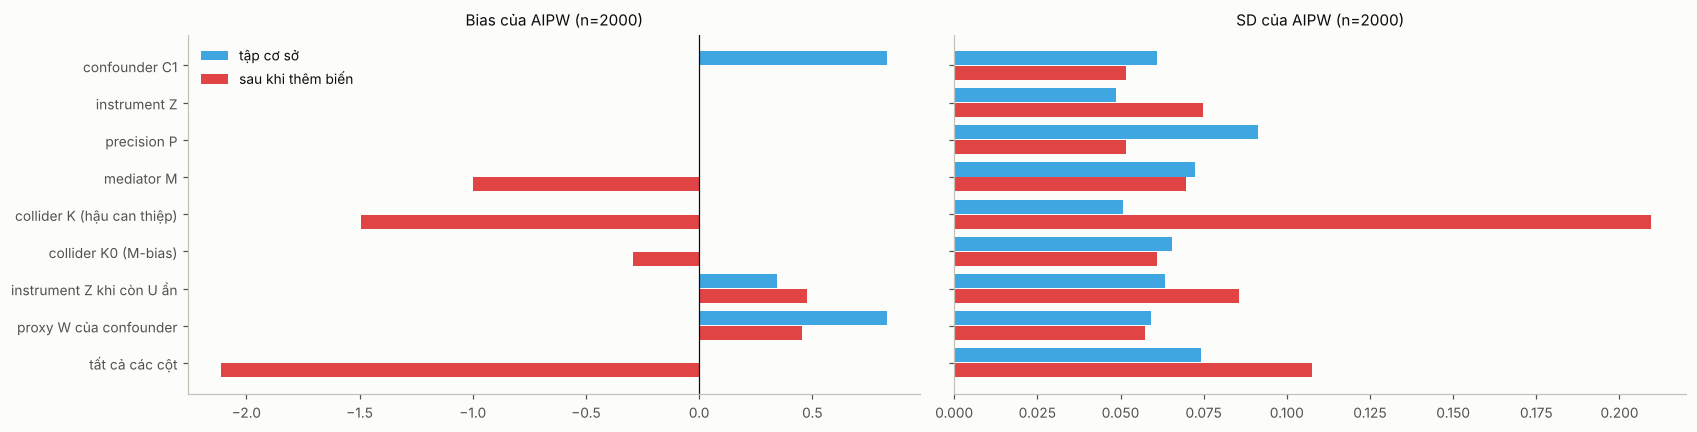

In [25]:
PAIRS = [  # (kịch bản, chiến lược cơ sở, chiến lược so sánh, vai trò biến được thêm vào)
 ("confounder", "none", "C1", "confounder C1"),
 ("instrument", "C1", "C1+Z", "instrument Z"),
 ("precision", "C1", "C1+P", "precision P"),
 ("mediator", "C1", "C1+M", "mediator M"),
 ("collider", "C1", "C1+K", "collider K (hậu can thiệp)"),
 ("m_bias", "none", "K0", "collider K0 (M-bias)"),
 ("amplification", "none", "Z", "instrument Z khi còn U ẩn"),
 ("proxy", "none", "W", "proxy W của confounder"),
 ("kitchen_sink", "conf+P", "all", "tất cả các cột"),
]
rows = []
for scn, base, add, what in PAIRS:
    d = RES[(RES.scenario == scn) & (RES.n == 2000) & (RES.method == "aipw")].set_index("strategy")
    rows.append({"biến được thêm vào": what, "tập cơ sở": base, "tập sau khi thêm": add,
                 "bias cơ sở": d.loc[base, "bias"], "bias sau": d.loc[add, "bias"],
                 "SD cơ sở": d.loc[base, "sd"], "SD sau": d.loc[add, "sd"],
                 "coverage cơ sở": d.loc[base, "coverage"], "coverage sau": d.loc[add, "coverage"]})
SUM = pd.DataFrame(rows).set_index("biến được thêm vào")
display(SUM.round(3))

fig, axes = plt.subplots(1, 2, figsize=(15.5, 4.0)); y = np.arange(len(SUM))
axes[0].barh(y - 0.2, SUM["bias cơ sở"], 0.38, color=BLUE, label="tập cơ sở"); axes[0].barh(y + 0.2, SUM["bias sau"], 0.38, color=RED, label="sau khi thêm biến")
axes[0].axvline(0, color=INK, lw=0.8); axes[0].set_yticks(y); axes[0].set_yticklabels(SUM.index); axes[0].invert_yaxis(); axes[0].set_title("Bias của AIPW (n=2000)"); axes[0].legend(frameon=False)
axes[1].barh(y - 0.2, SUM["SD cơ sở"], 0.38, color=BLUE); axes[1].barh(y + 0.2, SUM["SD sau"], 0.38, color=RED)
axes[1].set_yticks(y); axes[1].set_yticklabels([]); axes[1].invert_yaxis(); axes[1].set_title("SD của AIPW (n=2000)")
fig.tight_layout(); plt.show()

**Nhận xét: quy tắc rút ra cho từng vai trò** (AIPW, $n=2000$, theo bảng và hình trên).

| Vai trò của biến thêm vào | Kết quả mô phỏng | Quy tắc |
|---|---|---|
| Confounder $C_1$ | bias 0,829 → 0,001; coverage 0 → 0,952 | **Luôn hiệu chỉnh** (PS và outcome) |
| Instrument $Z$ | bias không đổi, SD 0,049 → 0,075 (×1,5; IPTW ×2,1) | **Không đưa vào**; nếu đã biết là instrument thì loại |
| Precision $P$ | bias không đổi, SD 0,091 → 0,052 (−43%) | **Nên đưa vào** (mô hình outcome, cũng không hại ở PS) |
| Mediator $M$ | bias 0,002 → −1,000 (sai estimand) | **Không đưa vào** nếu cần hiệu ứng *tổng* |
| Collider hậu can thiệp $K$ | bias 0,003 → −1,493; SD ×4 | **Tuyệt đối không** |
| Collider tiền can thiệp $K_0$ | bias 0,002 → −0,292; coverage 0,94 → 0,001 | **Không đưa vào** nếu có cơ sở là collider; nguy hiểm khi $n$ lớn |
| Instrument $Z$ khi còn $U$ ẩn | bias 0,344 → 0,478 (+39% theo AIPW) | **Không đưa vào** |
| Proxy $W$ của confounder ẩn | bias 0,830 → 0,455 | **Nên đưa vào** nhưng còn bias; cần phân tích độ nhạy |
| Tất cả các cột | bias −0,002 → −2,110 | Không bao giờ chọn "tất cả" làm mặc định |

**Quy trình tổng quát cho dữ liệu thật ("nếu vấn đề A thì xử lý B và ước lượng C").** Đây là bản nháp; phần gạch dưới có thể bổ sung ở các nhóm tiếp theo.

| Bước | Vấn đề A (quan sát được hoặc biết từ chuyên môn) | Xử lý B | Ước lượng C |
|---|---|---|---|
| 1 | Biến đo **sau** can thiệp hoặc có thể là hậu quả của $A$/$Y$ (mediator, collider, descendant) | Loại khỏi PS và outcome (hoặc tách riêng nếu hỏi hiệu ứng trực tiếp) | — |
| 2 | Biến tiền can thiệp liên quan cả $A$ lẫn $Y$ | Đưa vào PS và outcome | AIPW (OLS để đối chiếu) |
| 3 | Biến chỉ liên quan $Y$ | Đưa vào mô hình outcome | AIPW hoặc OLS |
| 4 | Biến chỉ liên quan $A$ (nghi là instrument) | Loại, đặc biệt khi nghi còn confounder không đo | — |
| 5 | Nghi biến tiền can thiệp là hậu quả chung của hai nguyên nhân khác (M-bias) | Loại nếu có kiến thức DAG; nếu không rõ có phải confounder thật không thì cân nhắc theo [11, 13] | So sánh kết quả có và không có biến đó |
| 6 | Confounder chỉ có proxy | Đưa proxy vào; ghi rõ residual confounding | Cộng thêm phân tích độ nhạy (E-value [18]) |
| 7 | ESS/n thấp, trọng số lớn nhất lớn khi thêm một biến | **Xem lại tập biến** trước khi trimming | AIPW + so sánh với OLS; trimming/OW chỉ là phương án sau |
| 8 | Confounder không đo | Không có cách xử lý bằng điều chỉnh | Cần thiết kế khác (biến công cụ, DiD, ...) |

Quy trình này mới dùng cho **vấn đề chọn biến** (nhóm 6). Các vấn đề về hình dạng, vị trí, phân tán, cộng tuyến phi tuyến được xử lý ở các nhóm trước; khi gộp lại thành pipeline sẽ thêm các bước kiểm tra phân phối và overlap ở trước bước 1.

## 9. Phụ lục: hiệu chỉnh SE của IPTW cho việc ước lượng PS

Ở mục 5 SE của IPTW được tính bằng `hajek_se_ps_corrected`. Phụ lục này kiểm tra lại lựa chọn đó: so sánh SE **coi PS đã biết** (`iptw_plugin`, tức bỏ qua việc PS được ước lượng) với SE hiệu chỉnh (`iptw`) trên kịch bản confounder và tập tối thiểu của kịch bản tổng hợp. Lý thuyết [15] cho biết khi PS được ước lượng bằng mô hình đúng, phương sai của IPTW **nhỏ hơn** so với khi PS đã biết (vì phần ước lượng PS cũng hiệu chỉnh luôn một phần nhiễu mẫu), nên SE plug-in sẽ quá bảo thủ.

,kịch bản,n,SE,SD thật,SE trung bình,SE/SD,coverage,độ rộng CI
0,confounder,500,hiệu chỉnh PS,0.118,0.114,0.968,0.939,0.447
1,confounder,500,plug-in (PS đã biết),0.118,0.163,1.385,0.989,0.639
2,confounder,2000,hiệu chỉnh PS,0.060,0.059,0.984,0.946,0.230
3,confounder,2000,plug-in (PS đã biết),0.060,0.083,1.395,0.991,0.326
4,confounder,5000,hiệu chỉnh PS,0.036,0.037,1.023,0.954,0.146
5,confounder,5000,plug-in (PS đã biết),0.036,0.053,1.449,0.995,0.206
6,kitchen_sink,500,hiệu chỉnh PS,0.176,0.174,0.990,0.942,0.683
7,kitchen_sink,500,plug-in (PS đã biết),0.176,0.197,1.119,0.969,0.772
8,kitchen_sink,2000,hiệu chỉnh PS,0.089,0.087,0.980,0.942,0.342
9,kitchen_sink,2000,plug-in (PS đã biết),0.089,0.098,1.104,0.965,0.386


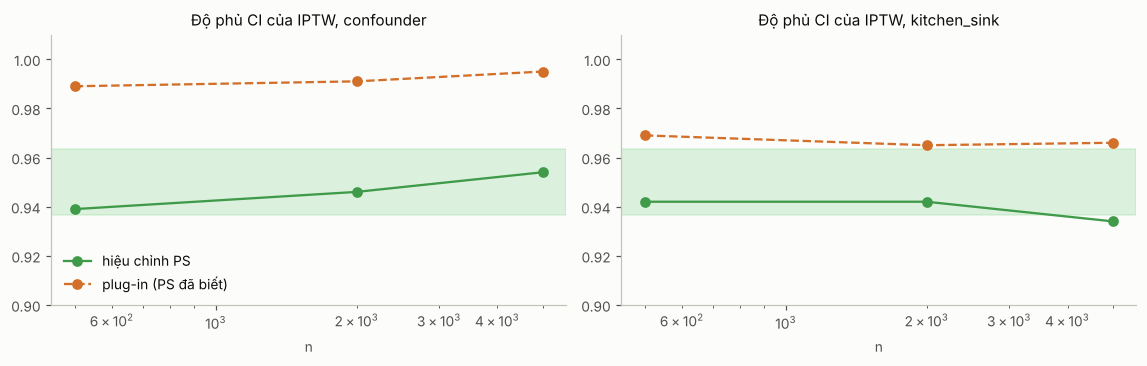

In [26]:
rows = []
for scn, st in (("confounder", "C1"), ("kitchen_sink", "conf")):
    sim = RoleSimulation(scn)
    for n in (500, 2000, 5000):
        s, _ = monte_carlo(sim, n=n, reps=REPS, seed=SEED, methods=("iptw", "iptw_plugin"), strategies={st: sim.strategies[st]}, n_jobs=2)
        for m in ("iptw", "iptw_plugin"):
            r = s[s.method == m].iloc[0]
            rows.append({"kịch bản": scn, "n": n, "SE": "hiệu chỉnh PS" if m == "iptw" else "plug-in (PS đã biết)",
                         "SD thật": r.sd, "SE trung bình": r.mean_se, "SE/SD": r.mean_se / r.sd, "coverage": r.coverage, "độ rộng CI": r.ci_width})
SEC = pd.DataFrame(rows); display(SEC.round(3))
fig, axes = plt.subplots(1, 2, figsize=(10.5, 3.4))
for j, scn in enumerate(("confounder", "kitchen_sink")):
    d = SEC[SEC["kịch bản"] == scn]
    for lab, col, ls in (("hiệu chỉnh PS", GREEN, "-"), ("plug-in (PS đã biết)", ORANGE, "--")):
        axes[j].plot(d[d.SE == lab].n, d[d.SE == lab]["coverage"], ls, marker="o", color=col, label=lab)
    axes[j].axhspan(0.95 - MC_BAND, 0.95 + MC_BAND, color="#7ED386", alpha=0.25); axes[j].set_xscale("log"); axes[j].set_ylim(0.9, 1.01)
    axes[j].set_title(f"Độ phủ CI của IPTW, {scn}"); axes[j].set_xlabel("n")
axes[0].legend(frameon=False); fig.tight_layout(); plt.show()

**Nhận xét.**

- Với SE **hiệu chỉnh** cho việc ước lượng PS, SE trung bình sát SD thật (tỉ số 0,97–1,02 ở kịch bản confounder; 0,92–0,99 ở kịch bản tổng hợp) và coverage 0,934–0,954, nằm trong hoặc sát dải chấp nhận. Ở kịch bản tổng hợp tại $n=5000$, tỉ số 0,92 và coverage 0,934 hơi thấp, đúng ở biên của dải sai số Monte Carlo (0,936), nên nhóm không kết luận gì thêm.
- Với SE **plug-in** (coi PS đã biết), SE lớn hơn SD thật 1,39–1,45 lần ở kịch bản confounder, coverage 0,989–0,995: quá bảo thủ. Ở kịch bản tổng hợp chênh lệch nhỏ hơn (1,04–1,12 lần).
- Giải thích theo [15]: khi PS được ước lượng bằng mô hình đúng, việc ước lượng này làm *giảm* phương sai của ước lượng IPTW so với khi biết PS thật, nên SE plug-in thừa. Mức thừa lớn hơn khi PS dự báo mạnh theo biến duy nhất ($C_1$ với hệ số 1) và nhỏ hơn khi PS phân tán trên nhiều biến yếu hơn.
- Do đó các kết luận về coverage của IPTW ở mục 5 dựa trên SE hiệu chỉnh; nếu dùng plug-in thì coverage của IPTW sẽ luôn "quá đẹp" (≈ 0,99) và che mất sai lệch.

## 10. Kết luận, hạn chế và hướng tiếp theo

### 10.1 Kết luận chính

1. **Vai trò của biến do vị trí trong DAG quyết định, không do số liệu.** Confounder, mediator, collider hậu can thiệp và M-bias đều "liên quan" đến cả $A$ và $Y$ trong dữ liệu (mục 4), nhưng đòi hỏi bốn cách xử lý khác nhau.
2. **Chọn sai biến gây bias không giảm theo $n$** và làm coverage sụp đổ khi $n$ tăng, vì SE co lại trong khi bias giữ nguyên. Đặc biệt với M-bias và proxy, kết quả ở $n=200$ trông ổn nhưng ở $n=2000$ thì không.
3. **Mức độ nghiêm trọng khác nhau:** collider hậu can thiệp (−1,5 đến −2,3) và mediator (−1,0) nặng hơn nhiều so với M-bias (−0,29) và instrument (không lệch, chỉ tăng SD). "Đưa hết biến vào" đưa ước lượng từ +0,56 (naive) đến −2,11.
4. **Phương pháp ước lượng ít quan trọng hơn tập biến.** Ở mọi tập biến sai, cả OLS, IPTW và AIPW cùng sai gần như giống nhau; sự khác biệt chủ yếu nằm ở phương sai (IPTW và AIPW bất ổn nhất khi PS cực đoan). AIPW bền vững với sai mô hình nhưng không bền vững với sai biến.
5. **ESS và trọng số lớn nhất** là chẩn đoán hữu ích hơn SMD để phát hiện biến hậu can thiệp hoặc instrument mạnh bị đưa vào PS.

### 10.2 Hạn chế (cần nói rõ khi trình bày)

- **Mô hình đúng dạng.** Outcome tuyến tính và PS logistic đều đúng, nên các kết quả ở đây tách riêng vấn đề *chọn biến*. Khi mô hình sai dạng (nhóm phi tuyến), các phát hiện có thể thay đổi, nhất là vai trò của AIPW.
- **DAG được biết trước.** Thực tế DAG là giả định; các biến được phân vai bằng kiến thức chuyên môn, và chúng ta không mô phỏng việc *phân vai sai*.
- **Hệ số được chọn mạnh** (đặc biệt M-bias, collider) để nhìn rõ hiệu ứng; trong dữ liệu thực M-bias thường nhỏ hơn [11]. Phép quét ở mục 6 cho thấy xu hướng nhưng không thay thế được việc hiệu chỉnh theo bối cảnh cụ thể.
- **Các biến ngoại sinh độc lập, chuẩn,** nên chưa xét tương tác giữa vai trò biến và cộng tuyến hay phân phối lệch đã khảo sát ở các nhóm trước.
- **Hiệu ứng đồng nhất, $A$ nhị phân, một mức confounding ẩn** (chỉ ở kịch bản khuếch đại), và chưa có biến đổi theo thời gian (ví dụ mediator–confounder phụ thuộc thời gian).
- **Một số lời giải thích chưa được kiểm chứng riêng:** vì sao IPTW cũng lợi từ biến precision (5.3), và vì sao AIPW có SD lớn hơn IPTW khi PS quá cực đoan (6.1).
- **Tài liệu tham khảo ghi theo hiểu biết của người viết;** cần kiểm tra lại trước khi trích dẫn chính thức.

### 10.3 Bước tiếp theo cho pipeline

1. **Module "bảng vai trò biến":** đầu vào là bảng chuyên gia điền (tên biến, thời điểm đo, có thể là hậu quả của $A$ hay $Y$ không); đầu ra là tập hiệu chỉnh (đã có hàm `classify_roles` và `recommended_adjustment_set` trong `utilities.py`, cần mở rộng cho bảng thay vì DAG).
2. **Module chẩn đoán:** ESS, trọng số lớn nhất, tỉ lệ PS cực đoan, SMD (chỉ trên biến tiền can thiệp) trước khi chạy ước lượng; cảnh báo khi một biến mới làm ESS giảm mạnh.
3. **Module ước lượng:** AIPW (SE theo hàm ảnh hưởng) là mặc định, OLS và IPTW (SE đã hiệu chỉnh PS) để đối chiếu; báo cáo cả ba.
4. **Phân tích độ nhạy** cho confounder không đo hoặc đo có sai số (E-value).
5. **Kết hợp với các nhóm trước:** chạy lại các kịch bản vai trò với covariate lệch, dịch vị trí, phương sai lớn, cộng tuyến để xem các quy tắc ở mục 8 còn đúng không, rồi bổ sung phương pháp ước lượng (ví dụ bổ sung ML cho nuisance) vào các kịch bản trước khi cần.

## 11. Lưu kết quả để tái sử dụng
Toàn bộ bảng kết quả được lưu vào thư mục `results/` (định dạng pickle) để vẽ lại hình hoặc dùng trong slide mà không phải chạy lại mô phỏng.

In [27]:
os.makedirs("results", exist_ok=True)
for name, obj in {"RES": RES, "ASYM_TAB": ASYM_TAB, "SWP": SWP, "SEC": SEC, "SUM": SUM, "OVL": OVL, "FINGERPRINT": fp, "BALANCE": bal}.items():
    pd.to_pickle(obj, f"results/{name}.pkl")
RES.to_csv("results/monte_carlo_summary.csv", index=False)
print("đã lưu:", sorted(os.listdir("results")))

đã lưu: ['ASYM_TAB.pkl', 'BALANCE.pkl', 'FINGERPRINT.pkl', 'OVL.pkl', 'RES.pkl', 'SEC.pkl', 'SUM.pkl', 'SWP.pkl', 'monte_carlo_summary.csv']
